# Customer Transaction Behavior Segmentation Using Machine Learning


# 3. MODEL EXPERIMENTATION

Tahap ini berfokus pada pengujian beberapa algoritma
Unsupervised Machine Learning untuk mengidentifikasi
kelompok akun berdasarkan karakteristik transaksi.

Eksperimen dilakukan dengan membandingkan beberapa
representasi data, strategi feature scaling, transformasi
fitur, serta konfigurasi algoritma clustering.

Algoritma yang akan digunakan:
1. K-Means Clustering
2. Agglomerative Clustering
3. DBSCAN

Alasan Pemilihan Algoritma Clustering:

Tiga algoritma clustering dipilih untuk membandingkan pendekatan
yang memiliki karakteristik berbeda dalam membentuk kelompok pelanggan:

1. **K-Means Clustering**  
   Dipilih sebagai baseline karena sederhana, efisien, dan efektif
   untuk mengidentifikasi cluster berbasis kedekatan terhadap centroid.
   Algoritma ini cocok digunakan sebagai titik awal untuk mengetahui
   struktur segmentasi pelanggan.

2. **Agglomerative Clustering**  
   Dipilih sebagai pendekatan hierarchical clustering untuk melihat
   apakah struktur kelompok pelanggan yang ditemukan K-Means juga
   dapat terbentuk melalui proses penggabungan cluster secara bertahap.
   Perbandingan ini membantu menguji apakah hasil segmentasi bergantung
   pada pendekatan centroid atau tidak.

3. **DBSCAN**  
   Dipilih karena menggunakan pendekatan berbasis kepadatan dan mampu
   mengidentifikasi observasi yang bersifat noise atau outlier.
   Algoritma ini memberikan perspektif berbeda terhadap kemungkinan
   adanya kelompok pelanggan yang tidak berbentuk cluster
   konvensional.

Dengan menggunakan ketiga algoritma tersebut, eksperimen tidak hanya
mencari model dengan skor evaluasi terbaik, tetapi juga membandingkan
tiga perspektif berbeda dalam menemukan struktur pelanggan:
**centroid-based, hierarchical, dan density-based clustering.**


Evaluasi awal dilakukan menggunakan Silhouette Score,
Davies-Bouldin Index, dan Calinski-Harabasz Index.

Hasil eksperimen akan digunakan sebagai dasar untuk
evaluasi stabilitas, pemilihan model, dan interpretasi
cluster pada tahap selanjutnya.

In [ ]:
# Importing libraries for machine learning experiments

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)

from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries successfully imported.")

Libraries successfully imported.


## 3.2 Loading Preprocessed Dataset

Memuat hasil preprocessing dari Notebook 1 sebagai input
utama eksperimen Machine Learning.

Dua file digunakan dalam tahap ini:

1. customer_features_for_clustering_unscaled.csv
   Berisi 495 observasi akun dengan 29 fitur kandidat
   yang belum melalui proses feature scaling.

2. customer_level_features_audit.csv
   Berisi informasi pendukung hasil agregasi akun yang
   digunakan untuk analisis lebih lanjut pada tahap
   cluster profiling.

Dataset asli tidak diproses ulang karena seluruh proses
data cleaning dan feature engineering telah dilakukan
pada Notebook 1.

Pendekatan ini menjaga pemisahan tanggung jawab antara
data preparation dan model experimentation.

In [ ]:
# Uploading preprocessing outputs from Notebook 1

from google.colab import files

uploaded = files.upload()

required_files = [
    "customer_features_for_clustering_unscaled.csv",
    "customer_level_features_audit.csv"
]

missing_files = [
    file for file in required_files
    if file not in uploaded
]

if missing_files:

    raise FileNotFoundError(
        f"Required files not uploaded: {missing_files}"
    )


# Loading final feature matrix
X_customer = pd.read_csv(
    "customer_features_for_clustering_unscaled.csv",
    index_col=0
)

# Loading customer-level audit dataset
customer_audit = pd.read_csv(
    "customer_level_features_audit.csv",
    index_col=0
)


print("Feature matrix successfully loaded.")
print("Customer audit dataset successfully loaded.")

Saving customer_level_features_audit.csv to customer_level_features_audit.csv
Saving customer_features_for_clustering_unscaled.csv to customer_features_for_clustering_unscaled.csv
Feature matrix successfully loaded.
Customer audit dataset successfully loaded.


Proses pemuatan dataset hasil preprocessing dari Notebook 1 berhasil dilakukan. Dua file yang digunakan, yaitu customer_features_for_clustering_unscaled.csv dan customer_level_features_audit.csv.

Dataset pertama digunakan sebagai input utama dalam eksperimen clustering, sedangkan dataset kedua digunakan untuk menyimpan informasi pendukung dan membantu proses interpretasi karakteristik pelanggan.

Dengan demikian, proses eksperimen Machine Learning telah menggunakan hasil preprocessing yang sama dengan tahap sebelumnya.

## 3.3 Input Dataset Validation

Melakukan validasi terhadap dataset hasil preprocessing
sebelum digunakan dalam eksperimen clustering.

Pemeriksaan mencakup:
1. Jumlah observasi dan fitur.
2. Keunikan AccountID.
3. Kesesuaian AccountID antara kedua file.
4. Konsistensi tipe data numerik.
5. Missing values.
6. Infinite values.

Validasi dilakukan untuk memastikan bahwa input eksperimen
berasal dari hasil preprocessing yang sama dan tidak
mengalami perubahan struktur selama proses ekspor.

In [ ]:
# Validating AccountID indexes

X_customer.index = X_customer.index.astype(str).str.strip()

customer_audit.index = (
    customer_audit.index.astype(str).str.strip()
)

# Checking duplicate account identifiers
if not X_customer.index.is_unique:

    raise ValueError(
        "Duplicate AccountID found in feature matrix."
    )

if not customer_audit.index.is_unique:

    raise ValueError(
        "Duplicate AccountID found in audit dataset."
    )


# Checking AccountID consistency
if set(X_customer.index) != set(customer_audit.index):

    raise ValueError(
        "AccountID mismatch between the two uploaded datasets."
    )


# Aligning audit data with feature matrix
customer_audit = customer_audit.loc[
    X_customer.index
]


# Converting all feature columns into numeric data
X_customer = X_customer.apply(
    pd.to_numeric,
    errors="raise"
)


# Checking missing and infinite values
missing_count = X_customer.isnull().sum().sum()

infinite_count = np.isinf(
    X_customer.to_numpy()
).sum()


print("Number of customers:", X_customer.shape[0])

print("Number of features:", X_customer.shape[1])

print("Missing values:", missing_count)

print("Infinite values:", infinite_count)

print("Duplicated AccountID:", X_customer.index.duplicated().sum())


if missing_count > 0 or infinite_count > 0:

    raise ValueError(
        "Invalid values detected. Review preprocessing output first."
    )


print("\nInput dataset validation completed.")

display(X_customer.head())

Number of customers: 495
Number of features: 29
Missing values: 0
Infinite values: 0
Duplicated AccountID: 0

Input dataset validation completed.


,Transaction_Record_Count,Active_Months,Transaction_Span_Days,Observed_Transaction_Amount_Sum,Average_Transaction_Amount,Median_Transaction_Amount,Std_Transaction_Amount,Debit_Amount_Sum,Credit_Amount_Sum,Average_Account_Balance,...,Debit_Count,Credit_Count,ATM_Count,Branch_Count,Online_Count,Debit_Ratio,Credit_Ratio,ATM_Ratio,Branch_Ratio,Online_Ratio
AccountID,,,,,,,,,,,,,,,,,,,,,
AC00001,2,2,59.997384,260.76,130.380000,130.380,116.799898,260.76,0.00,2915.160000,...,2,0,0,1,1,1.000000,0.000000,0.000000,0.500000,0.500000
AC00002,7,6,345.041875,2056.21,293.744286,331.660,195.695091,1539.74,516.47,4480.421429,...,6,1,2,3,2,0.857143,0.142857,0.285714,0.428571,0.285714
AC00003,5,4,273.091829,1266.34,253.268000,237.970,158.484753,849.72,416.62,7329.568000,...,4,1,4,0,1,0.800000,0.200000,0.800000,0.000000,0.200000
AC00004,8,7,244.939340,2118.46,264.807500,204.775,236.187478,2019.21,99.25,2712.905000,...,7,1,2,4,2,0.875000,0.125000,0.250000,0.500000,0.250000
AC00005,9,6,285.071771,3131.77,347.974444,377.920,189.487268,2713.97,417.80,4457.837778,...,8,1,0,7,1,0.888889,0.111111,0.000000,0.777778,0.111111



Hasil validasi menunjukkan bahwa dataset memiliki 495 observasi pelanggan dengan 29 fitur numerik.

Tidak ditemukan missing values, infinite values, maupun AccountID yang terduplikasi pada feature matrix.

Kondisi tersebut menunjukkan bahwa setiap pelanggan telah memiliki satu representasi data yang konsisten dan seluruh fitur dapat digunakan dalam proses perhitungan jarak.

Selain itu, kesesuaian AccountID antara feature matrix dan customer audit dataset juga telah diperiksa untuk memastikan bahwa kedua file memiliki identitas pelanggan yang sama.

Berdasarkan hasil tersebut, dataset dinyatakan memenuhi persyaratan awal untuk digunakan dalam eksperimen clustering.

## 3.4 Original Feature Distribution and Skewness Analysis

Menganalisis distribusi statistik dan tingkat kemencengan
setiap fitur pada customer-level dataset.

Pengukuran skewness digunakan untuk mengidentifikasi fitur
yang memiliki distribusi tidak simetris.

Fitur dengan skewness positif tinggi menunjukkan adanya
kecenderungan nilai yang terkonsentrasi pada rentang lebih
rendah dengan sebagian observasi bernilai lebih besar.

Hasil analisis ini akan digunakan sebagai pertimbangan
untuk menguji log transformation pada fitur tertentu.

Transformasi tidak diterapkan secara otomatis ke seluruh
fitur karena setiap atribut memiliki karakteristik
dan interpretasi yang berbeda.

In [ ]:
# Calculating original feature distribution

feature_distribution = pd.DataFrame({

    "Mean": X_customer.mean(),

    "Median": X_customer.median(),

    "Standard Deviation": X_customer.std(),

    "Minimum": X_customer.min(),

    "Maximum": X_customer.max(),

    "Skewness": X_customer.skew()

})

feature_distribution["Skewness_Category"] = np.select(

    [
        feature_distribution["Skewness"] > 1,

        feature_distribution["Skewness"] < -1
    ],

    [
        "Highly Right-Skewed",

        "Highly Left-Skewed"
    ],

    default="Moderately Distributed"

)


display(
    feature_distribution.sort_values(
        by="Skewness",
        ascending=False
    )
)

,Mean,Median,Standard Deviation,Minimum,Maximum,Skewness,Skewness_Category
Average_Login_Attempts,1.115590,1.000000,0.286834,1.000000,4.000000,3.908830,Highly Right-Skewed
Maximum_Login_Attempts,1.555556,1.000000,1.180323,1.000000,5.000000,1.983934,Highly Right-Skewed
Credit_Amount_Sum,344.666949,180.360000,439.012293,0.000000,2640.220000,1.717860,Highly Right-Skewed
Median_Transaction_Amount,242.842535,226.370000,138.965353,7.080000,907.920000,1.165437,Highly Right-Skewed
Std_Transaction_Amount,257.510299,231.718833,144.573773,8.269016,867.192749,1.144770,Highly Right-Skewed
Online_Count,1.597980,1.000000,1.276539,0.000000,9.000000,1.031833,Highly Right-Skewed
Debit_Amount_Sum,1127.836465,957.060000,811.540821,0.000000,3999.690000,0.923691,Moderately Distributed
Credit_Ratio,0.217514,0.200000,0.201558,0.000000,1.000000,0.881140,Moderately Distributed
Credit_Count,1.123232,1.000000,1.052742,0.000000,5.000000,0.870462,Moderately Distributed
Branch_Count,1.717172,1.000000,1.392871,0.000000,7.000000,0.866759,Moderately Distributed


Hasil analisis statistik menunjukkan bahwa setiap fitur memiliki karakteristik distribusi yang berbeda.

Pada fitur aktivitas pelanggan, jumlah transaksi memiliki rata-rata sekitar 5,04 transaksi dan median sebanyak 5 transaksi per pelanggan. Hal ini menunjukkan bahwa jumlah transaksi pelanggan secara umum berada di sekitar lima transaksi.

Pada fitur finansial, Average_Account_Balance memiliki rata-rata sekitar 5.136,93, sedangkan Average_Transaction_Amount memiliki rata-rata sekitar 294,34. Perbedaan antara nilai rata-rata dan median pada beberapa fitur menunjukkan adanya variasi nominal transaksi dan saldo antar pelanggan.

Secara keseluruhan, hasil statistik menunjukkan bahwa distribusi fitur belum sepenuhnya seimbang. Karakteristik ini perlu diperhatikan karena algoritma clustering berbasis jarak dapat dipengaruhi oleh perbedaan distribusi dan rentang nilai antarfitur.

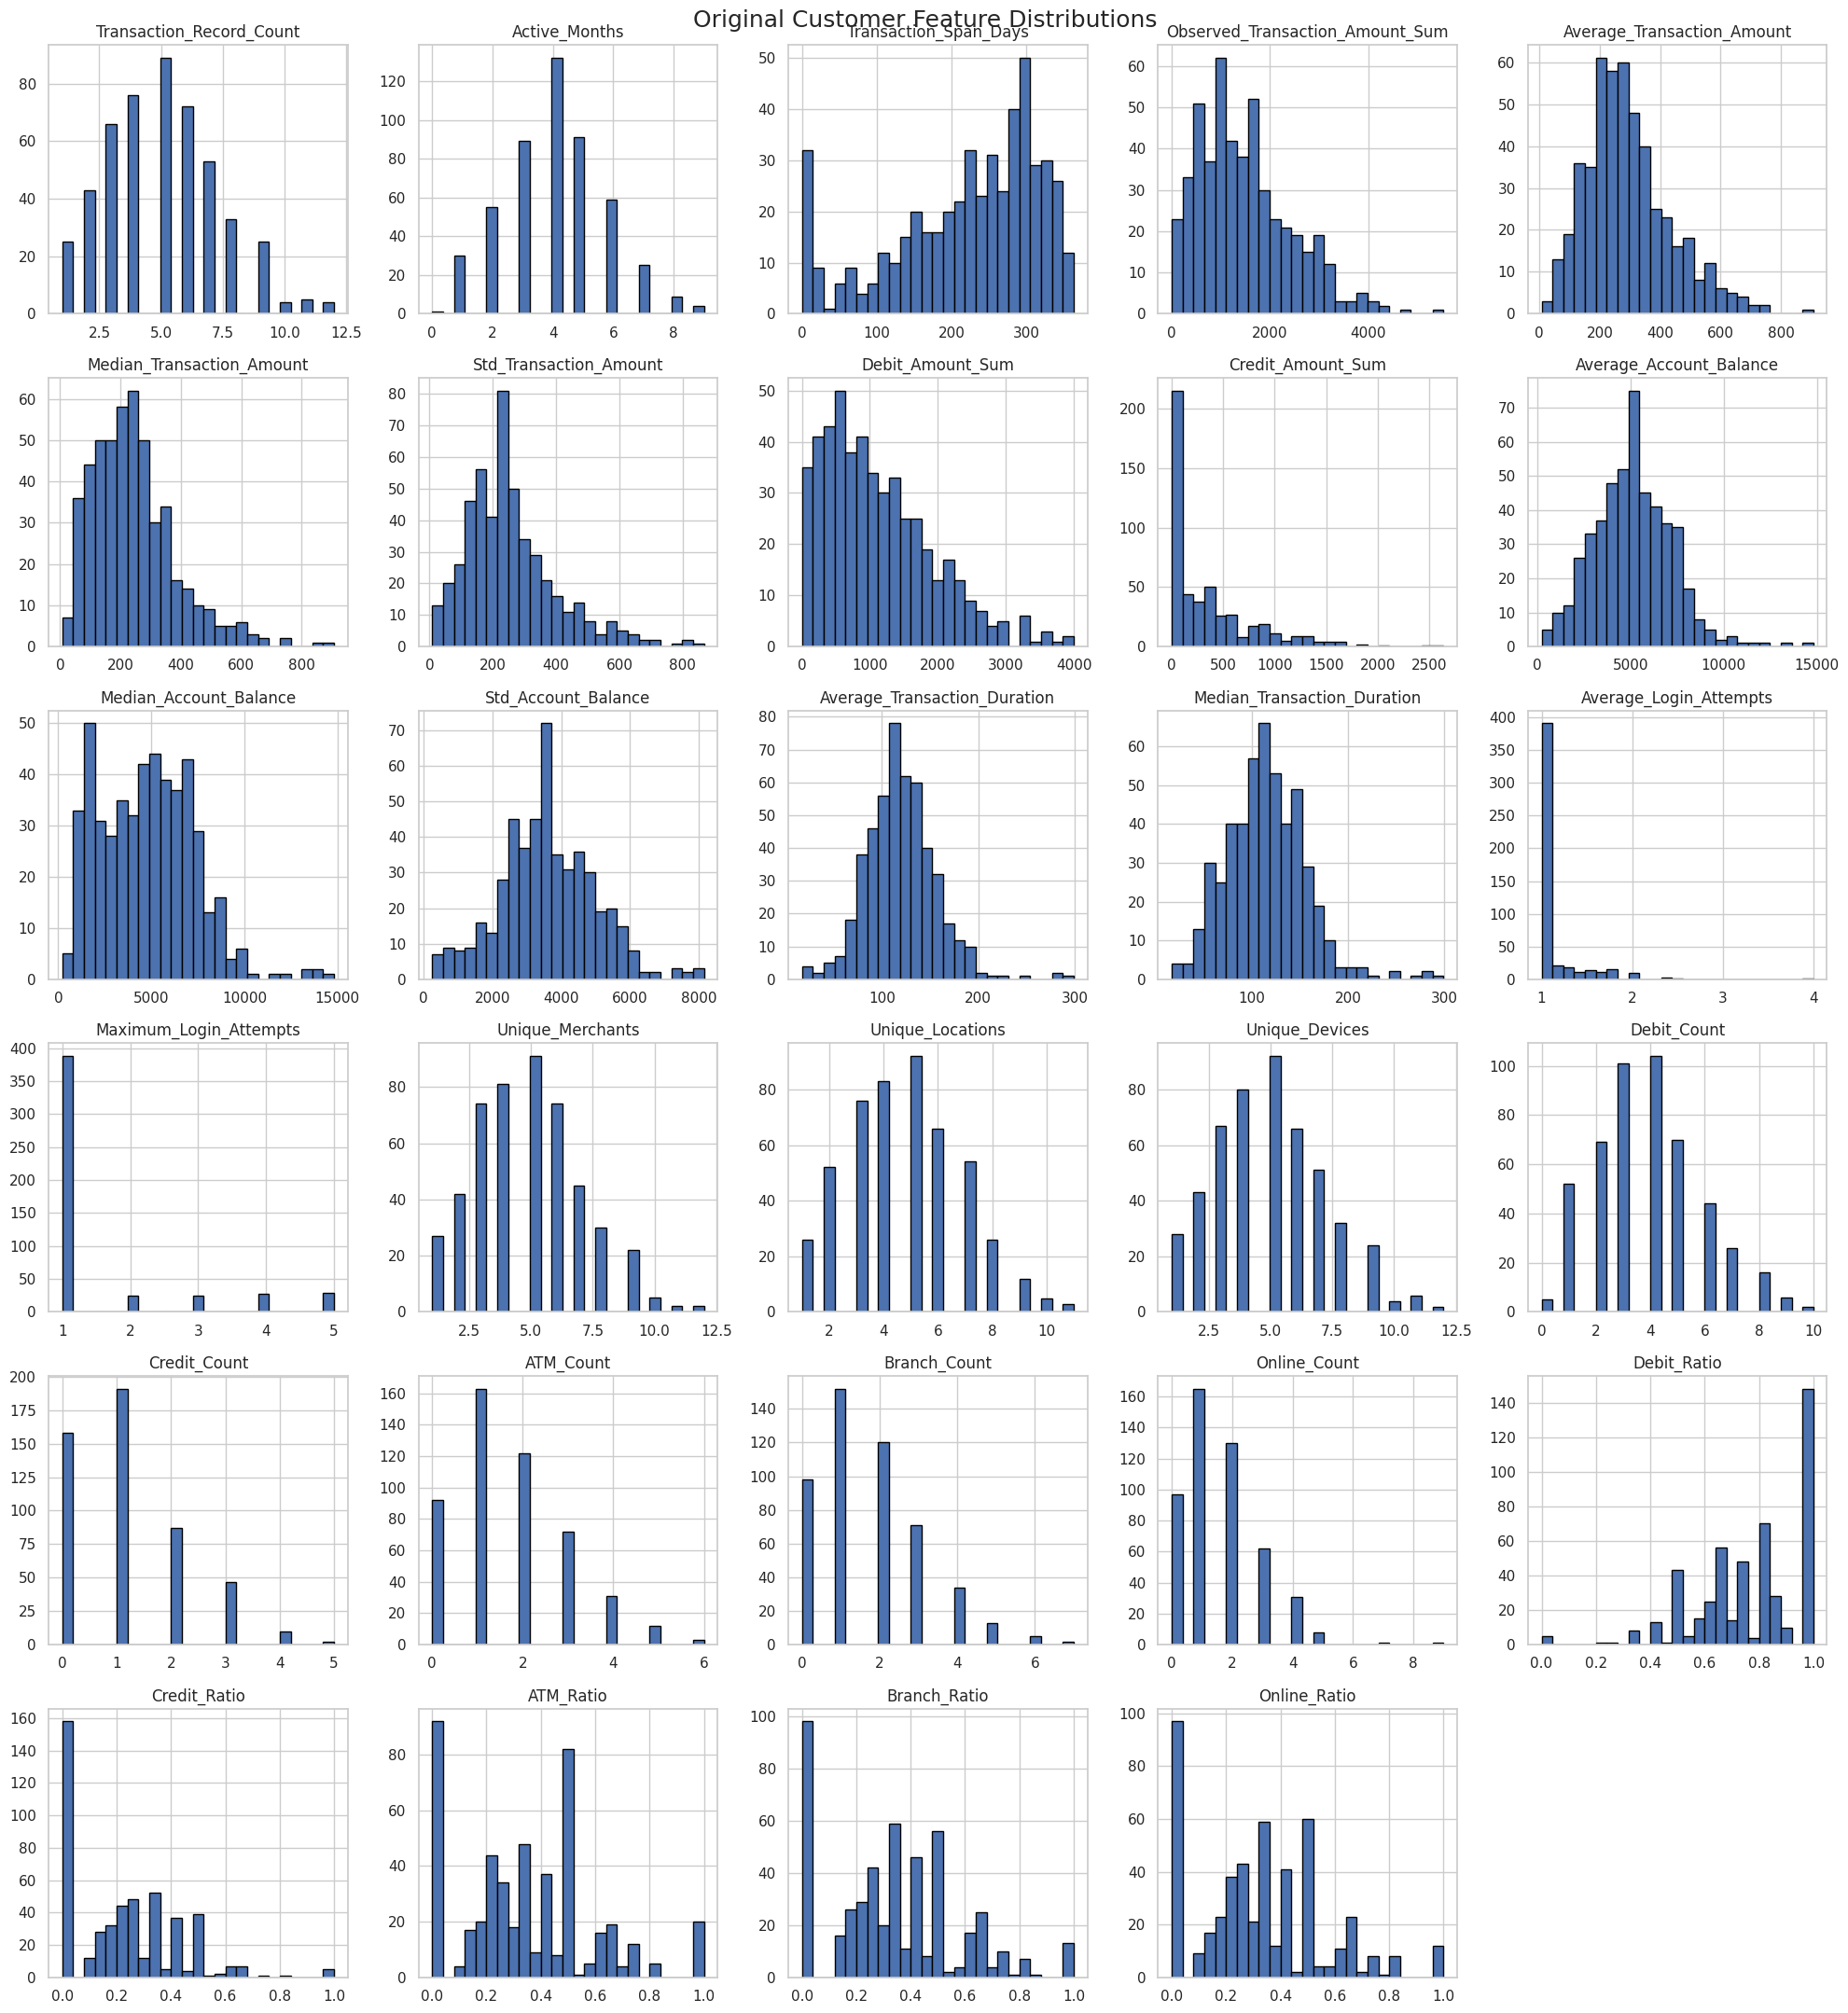

In [ ]:
# Visualizing original feature distributions

X_customer.hist(
    figsize=(20, 22),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Original Customer Feature Distributions",
    fontsize=18
)

plt.tight_layout()
plt.show()

Hasil visualisasi histogram memperlihatkan bahwa sebagian besar fitur memiliki pola distribusi yang berbeda.

Fitur Transaction_Record_Count dan Active_Months memperlihatkan konsentrasi data pada jumlah transaksi dan bulan aktif tertentu. Sementara itu, fitur nominal transaksi dan jumlah kredit menunjukkan kecenderungan distribusi ke kanan, dengan sebagian kecil pelanggan memiliki nilai yang jauh lebih tinggi dibandingkan pelanggan lainnya.

Sementara itu, fitur rasio seperti Debit_Ratio, Credit_Ratio, ATM_Ratio, Branch_Ratio, dan Online_Ratio memiliki rentang nilai antara 0 hingga 1 karena merepresentasikan proporsi aktivitas pelanggan.

Perbedaan pola distribusi tersebut menunjukkan bahwa penggunaan feature scaling dan pengujian transformasi data diperlukan sebelum proses clustering dilakukan

## 3.5 Original Feature Correlation Analysis

Menganalisis korelasi antarfitur untuk mengidentifikasi
variabel yang memiliki hubungan linear sangat kuat.

Fitur dengan korelasi absolut yang tinggi berpotensi
merepresentasikan informasi yang saling tumpang tindih.

Dalam clustering berbasis jarak, kondisi tersebut dapat
menyebabkan karakteristik tertentu memperoleh bobot
berlebihan dalam pembentukan kelompok.

Analisis dilakukan menggunakan Pearson Correlation.

Pasangan fitur dengan absolute correlation >= 0.90
ditandai sebagai kandidat yang perlu diperiksa lebih lanjut.

Penghapusan fitur tidak dilakukan secara otomatis.
Keputusan feature selection juga mempertimbangkan
makna dan relevansi setiap variabel.

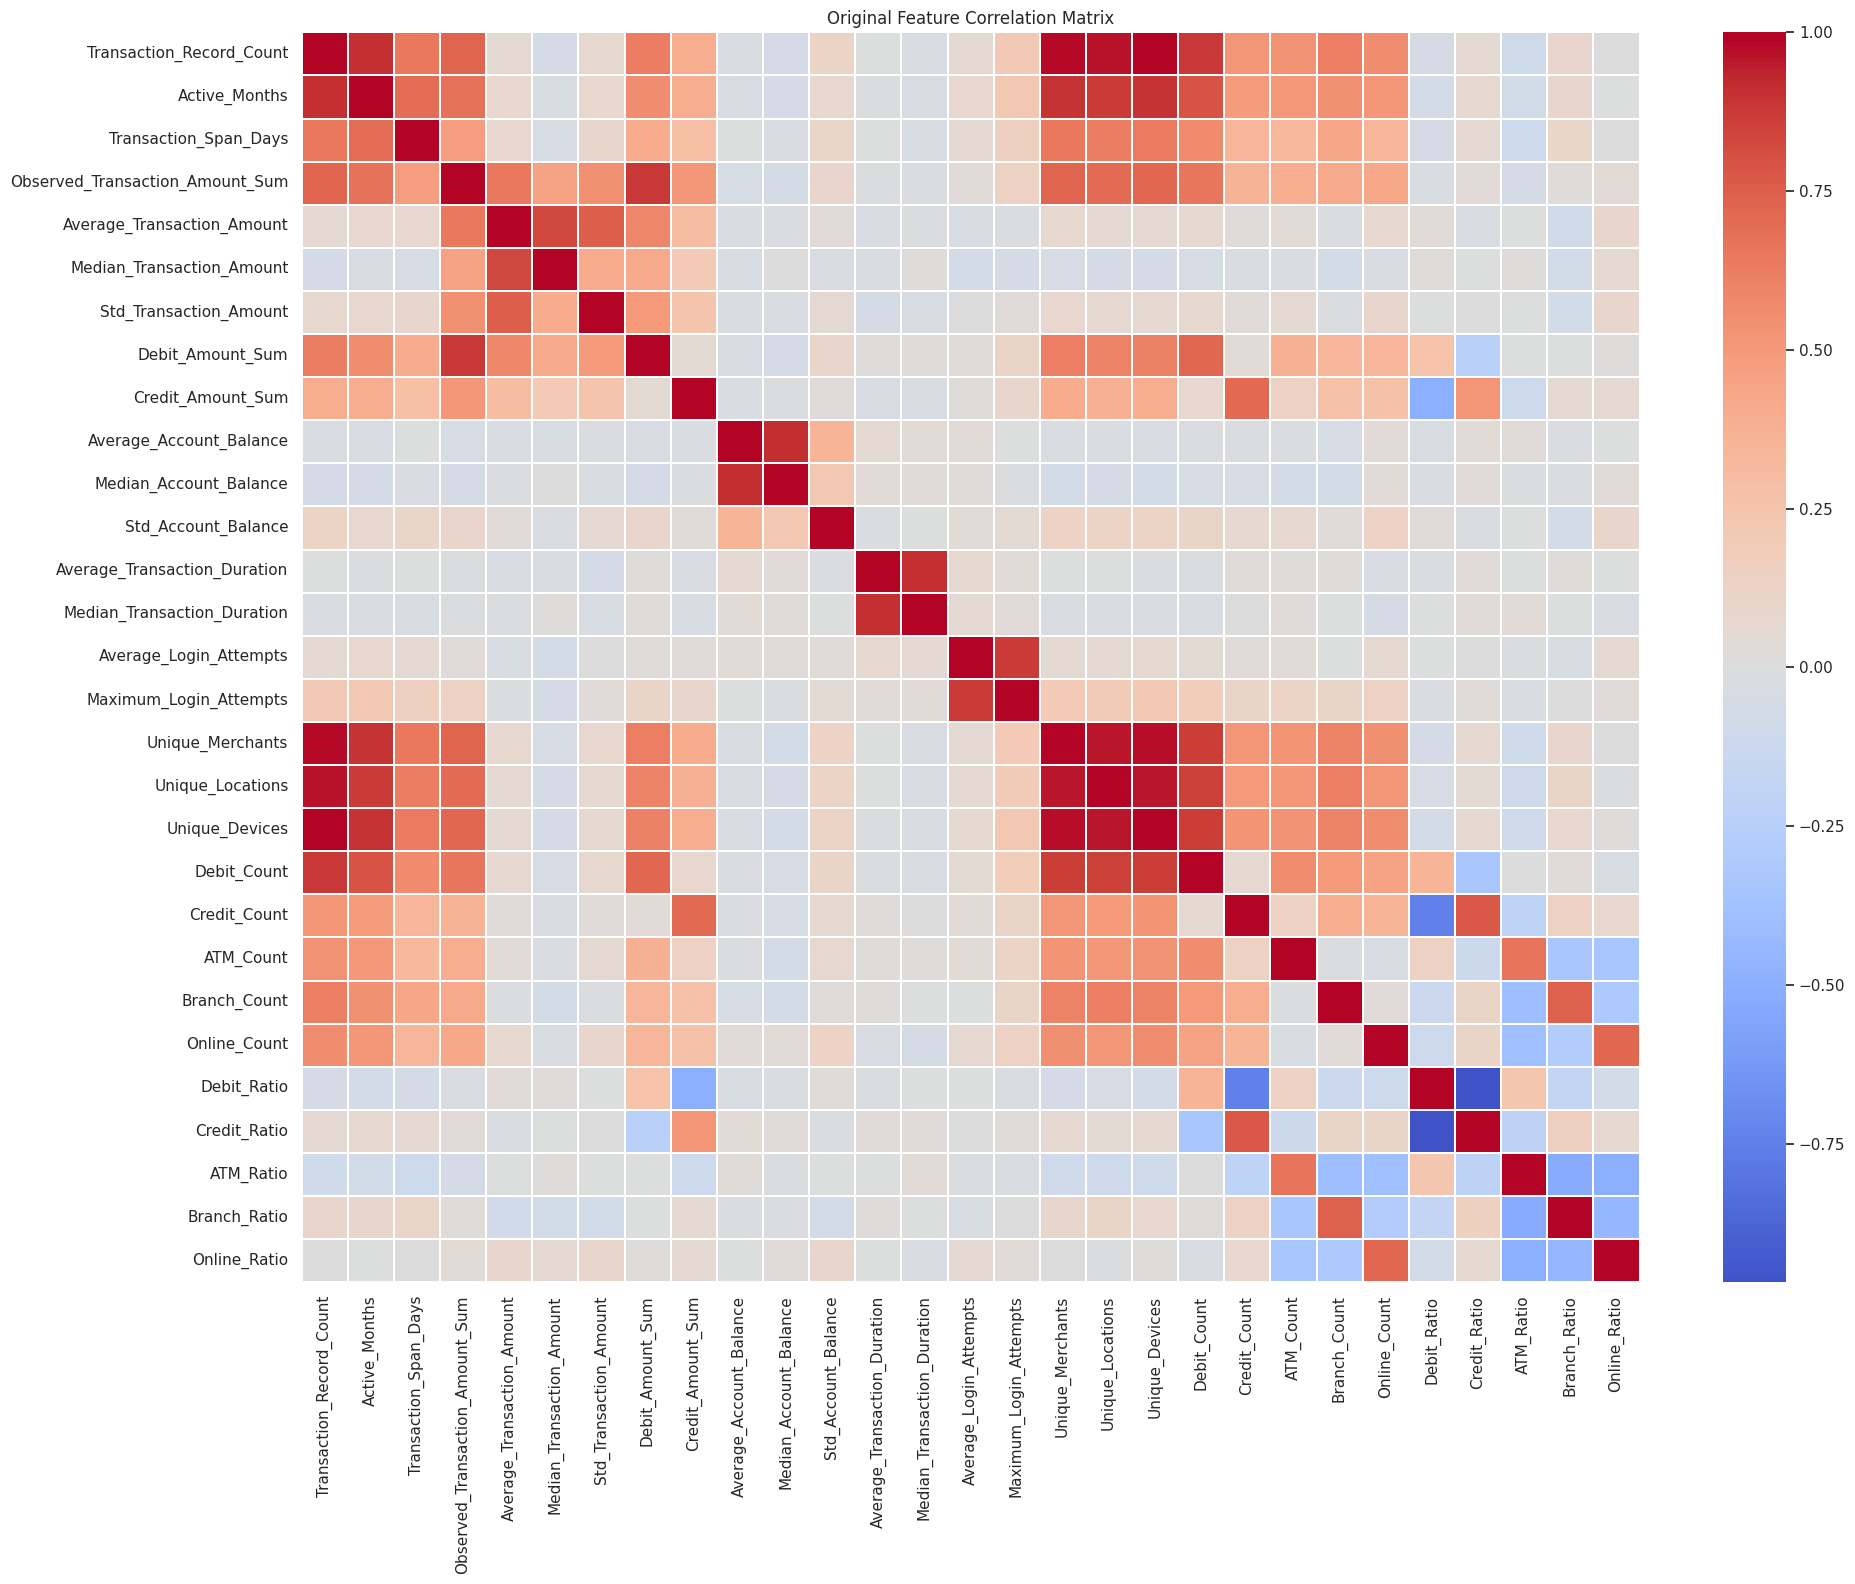

In [ ]:
# Calculating correlation matrix

correlation_matrix = X_customer.corr()

plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Original Feature Correlation Matrix")

plt.tight_layout()
plt.show()

Hasil visualisasi correlation matrix menunjukkan adanya beberapa hubungan yang cukup kuat antarfitur.

Hubungan positif yang kuat terlihat pada kelompok fitur aktivitas transaksi, seperti Transaction_Record_Count dengan jumlah merchant, lokasi, dan perangkat yang digunakan pelanggan.

Selain itu, Average_Account_Balance dan Median_Account_Balance juga menunjukkan hubungan positif yang kuat. Pola serupa ditemukan pada Average_Transaction_Duration dan Median_Transaction_Duration.

Di sisi lain, Debit_Ratio dan Credit_Ratio memperlihatkan hubungan negatif yang kuat karena keduanya merepresentasikan proporsi dua jenis transaksi yang berbeda.

Temuan ini menunjukkan bahwa beberapa fitur memiliki informasi yang saling berkaitan sehingga berpotensi memberikan pengaruh yang berulang dalam perhitungan jarak antar pelanggan.

In [ ]:
# Identifying highly correlated feature pairs

correlation_abs = correlation_matrix.abs()

upper_triangle = correlation_abs.where(
    np.triu(
        np.ones(correlation_abs.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute Correlation"] >= 0.90
    ]
    .sort_values(
        by="Absolute Correlation",
        ascending=False
    )
)

display(high_correlation_pairs)

,Feature 1,Feature 2,Absolute Correlation
17,Transaction_Record_Count,Unique_Devices,0.991200
15,Transaction_Record_Count,Unique_Merchants,0.983609
329,Unique_Merchants,Unique_Devices,0.975169
396,Debit_Ratio,Credit_Ratio,0.968265
16,Transaction_Record_Count,Unique_Locations,0.965925
340,Unique_Locations,Unique_Devices,0.957842
328,Unique_Merchants,Unique_Locations,0.954606
216,Average_Account_Balance,Median_Account_Balance,0.914658
0,Transaction_Record_Count,Active_Months,0.904733
270,Average_Transaction_Duration,Median_Transaction_Duration,0.900973


Hasil identifikasi menunjukkan bahwa terdapat 10 pasangan fitur yang memiliki nilai korelasi absolut sebesar 0,90 atau lebih.

Korelasi tertinggi ditemukan pada Transaction_Record_Count dengan Unique_Devices sebesar 0,9912. Selanjutnya, Transaction_Record_Count dengan Unique_Merchants memiliki korelasi sebesar 0,9836.

Hubungan kuat juga ditemukan pada pasangan Debit_Ratio dan Credit_Ratio sebesar 0,9683 serta Average_Account_Balance dan Median_Account_Balance sebesar 0,9147.

Temuan tersebut menunjukkan bahwa beberapa fitur memiliki informasi yang hampir serupa dalam menggambarkan aktivitas pelanggan.

Oleh karena itu, pengurangan fitur perlu dipertimbangkan untuk mengurangi informasi yang terlalu berulang dan menghasilkan representasi pelanggan yang lebih efisien dalam proses clustering.

## 3.6 Feature Selection: Reduced Feature Matrix

Membentuk alternatif feature matrix menggunakan fitur yang
dipilih berdasarkan relevansi analitis dan potensi redundansi.

Pengurangan fitur dilakukan untuk mengurangi representasi
informasi yang saling tumpang tindih dalam proses penghitungan
jarak antar akun.

Pendekatan ini menggunakan beberapa pertimbangan:

1. Median dan mean pada beberapa fitur yang sangat berkaitan
   tidak selalu perlu digunakan secara bersamaan.

2. Active_Months dikombinasikan dengan jumlah transaksi
   menjadi Transactions_Per_Active_Month.

3. Jumlah merchant, lokasi, dan perangkat diubah menjadi
   rasio terhadap jumlah transaksi.

4. Credit_Ratio, Branch_Ratio, dan Online_Ratio dipertahankan
   untuk merepresentasikan karakteristik transaksi.

Reduced feature matrix ini merupakan alternatif eksperimen,
bukan pengganti permanen seluruh 29 fitur.

Kualitas representasi akan diuji melalui perbandingan
hasil clustering pada konfigurasi berikutnya.

In [ ]:
# Creating reduced feature matrix

X_reduced = pd.DataFrame(
    index=X_customer.index
)


# 1. Transaction Activity

X_reduced["Transaction_Record_Count"] = (
    X_customer["Transaction_Record_Count"]
)

X_reduced["Transaction_Span_Days"] = (
    X_customer["Transaction_Span_Days"]
)

X_reduced["Transactions_Per_Active_Month"] = (
    X_customer["Transaction_Record_Count"] /
    X_customer["Active_Months"].replace(0, np.nan)
)


# 2. Transaction Amount

X_reduced["Average_Transaction_Amount"] = (
    X_customer["Average_Transaction_Amount"]
)

X_reduced["Std_Transaction_Amount"] = (
    X_customer["Std_Transaction_Amount"]
)

X_reduced["Debit_Amount_Sum"] = (
    X_customer["Debit_Amount_Sum"]
)

X_reduced["Credit_Amount_Sum"] = (
    X_customer["Credit_Amount_Sum"]
)


# 3. Financial Characteristics

X_reduced["Average_Account_Balance"] = (
    X_customer["Average_Account_Balance"]
)

X_reduced["Std_Account_Balance"] = (
    X_customer["Std_Account_Balance"]
)


# 4. Transaction Behavior

X_reduced["Average_Transaction_Duration"] = (
    X_customer["Average_Transaction_Duration"]
)

X_reduced["Average_Login_Attempts"] = (
    X_customer["Average_Login_Attempts"]
)

X_reduced["Maximum_Login_Attempts"] = (
    X_customer["Maximum_Login_Attempts"]
)


# 5. Transaction Preferences

X_reduced["Credit_Ratio"] = (
    X_customer["Credit_Ratio"]
)

X_reduced["Branch_Ratio"] = (
    X_customer["Branch_Ratio"]
)

X_reduced["Online_Ratio"] = (
    X_customer["Online_Ratio"]
)


# 6. Transaction Diversity

X_reduced["Merchants_Per_Transaction"] = (
    X_customer["Unique_Merchants"] /
    X_customer["Transaction_Record_Count"]
)

X_reduced["Locations_Per_Transaction"] = (
    X_customer["Unique_Locations"] /
    X_customer["Transaction_Record_Count"]
)

X_reduced["Devices_Per_Transaction"] = (
    X_customer["Unique_Devices"] /
    X_customer["Transaction_Record_Count"]
)


# Handling missing and infinite values from derived ratios
X_reduced = X_reduced.replace(
    [np.inf, -np.inf],
    np.nan
)

reduced_missing_before = X_reduced.isnull().sum()

X_reduced = X_reduced.fillna(
    X_reduced.median()
)


print("Original feature count:", X_customer.shape[1])

print("Reduced feature count:", X_reduced.shape[1])

print("Customer records:", X_reduced.shape[0])

print(
    "Missing values after feature engineering:",
    X_reduced.isnull().sum().sum()
)

print(
    "Newly imputed values:",
    reduced_missing_before.sum()
)

display(X_reduced.head())

Original feature count: 29
Reduced feature count: 18
Customer records: 495
Missing values after feature engineering: 0
Newly imputed values: 1


,Transaction_Record_Count,Transaction_Span_Days,Transactions_Per_Active_Month,Average_Transaction_Amount,Std_Transaction_Amount,Debit_Amount_Sum,Credit_Amount_Sum,Average_Account_Balance,Std_Account_Balance,Average_Transaction_Duration,Average_Login_Attempts,Maximum_Login_Attempts,Credit_Ratio,Branch_Ratio,Online_Ratio,Merchants_Per_Transaction,Locations_Per_Transaction,Devices_Per_Transaction
AccountID,,,,,,,,,,,,,,,,,,
AC00001,2,59.997384,1.000000,130.380000,116.799898,260.76,0.00,2915.160000,1789.319568,107.500000,1.000000,1.0,0.000000,0.500000,0.500000,1.000000,1.000000,0.5
AC00002,7,345.041875,1.166667,293.744286,195.695091,1539.74,516.47,4480.421429,2409.741268,109.857143,1.142857,2.0,0.142857,0.428571,0.285714,0.857143,1.000000,1.0
AC00003,5,273.091829,1.250000,253.268000,158.484753,849.72,416.62,7329.568000,4680.948009,49.200000,1.000000,1.0,0.200000,0.000000,0.200000,0.800000,1.000000,1.0
AC00004,8,244.939340,1.142857,264.807500,236.187478,2019.21,99.25,2712.905000,1816.641437,115.000000,1.000000,1.0,0.125000,0.500000,0.250000,1.000000,1.000000,1.0
AC00005,9,285.071771,1.500000,347.974444,189.487268,2713.97,417.80,4457.837778,3239.726440,145.111111,1.000000,1.0,0.111111,0.777778,0.111111,1.000000,0.888889,1.0


Hasil pembentukan reduced feature matrix menunjukkan bahwa jumlah fitur berhasil dikurangi dari 29 menjadi 18 fitur, dengan tetap mempertahankan 495 observasi pelanggan.

Pengurangan fitur dilakukan dengan mempertimbangkan relevansi informasi serta hubungan antarfitur yang ditemukan pada analisis korelasi sebelumnya.

Selain mempertahankan fitur utama, dilakukan pula pembentukan fitur baru seperti Transactions_Per_Active_Month, Merchants_Per_Transaction, Locations_Per_Transaction, dan Devices_Per_Transaction.

Fitur-fitur tersebut digunakan untuk menggambarkan aktivitas pelanggan berdasarkan frekuensi maupun proporsi aktivitasnya.




## 3.7 Reduced Feature Correlation Analysis

Mengevaluasi kembali hubungan korelasi setelah proses
pengurangan dan pembentukan fitur.

Tujuan analisis ini adalah mengetahui apakah reduced feature
matrix masih memiliki pasangan fitur dengan korelasi tinggi.

Hasilnya digunakan untuk menilai efektivitas strategi
feature selection dan mengidentifikasi kemungkinan
redundansi yang masih tersisa.

Perlu diperhatikan bahwa fitur dengan korelasi tinggi
tidak selalu harus dihapus karena dapat memiliki makna
analitis yang berbeda.

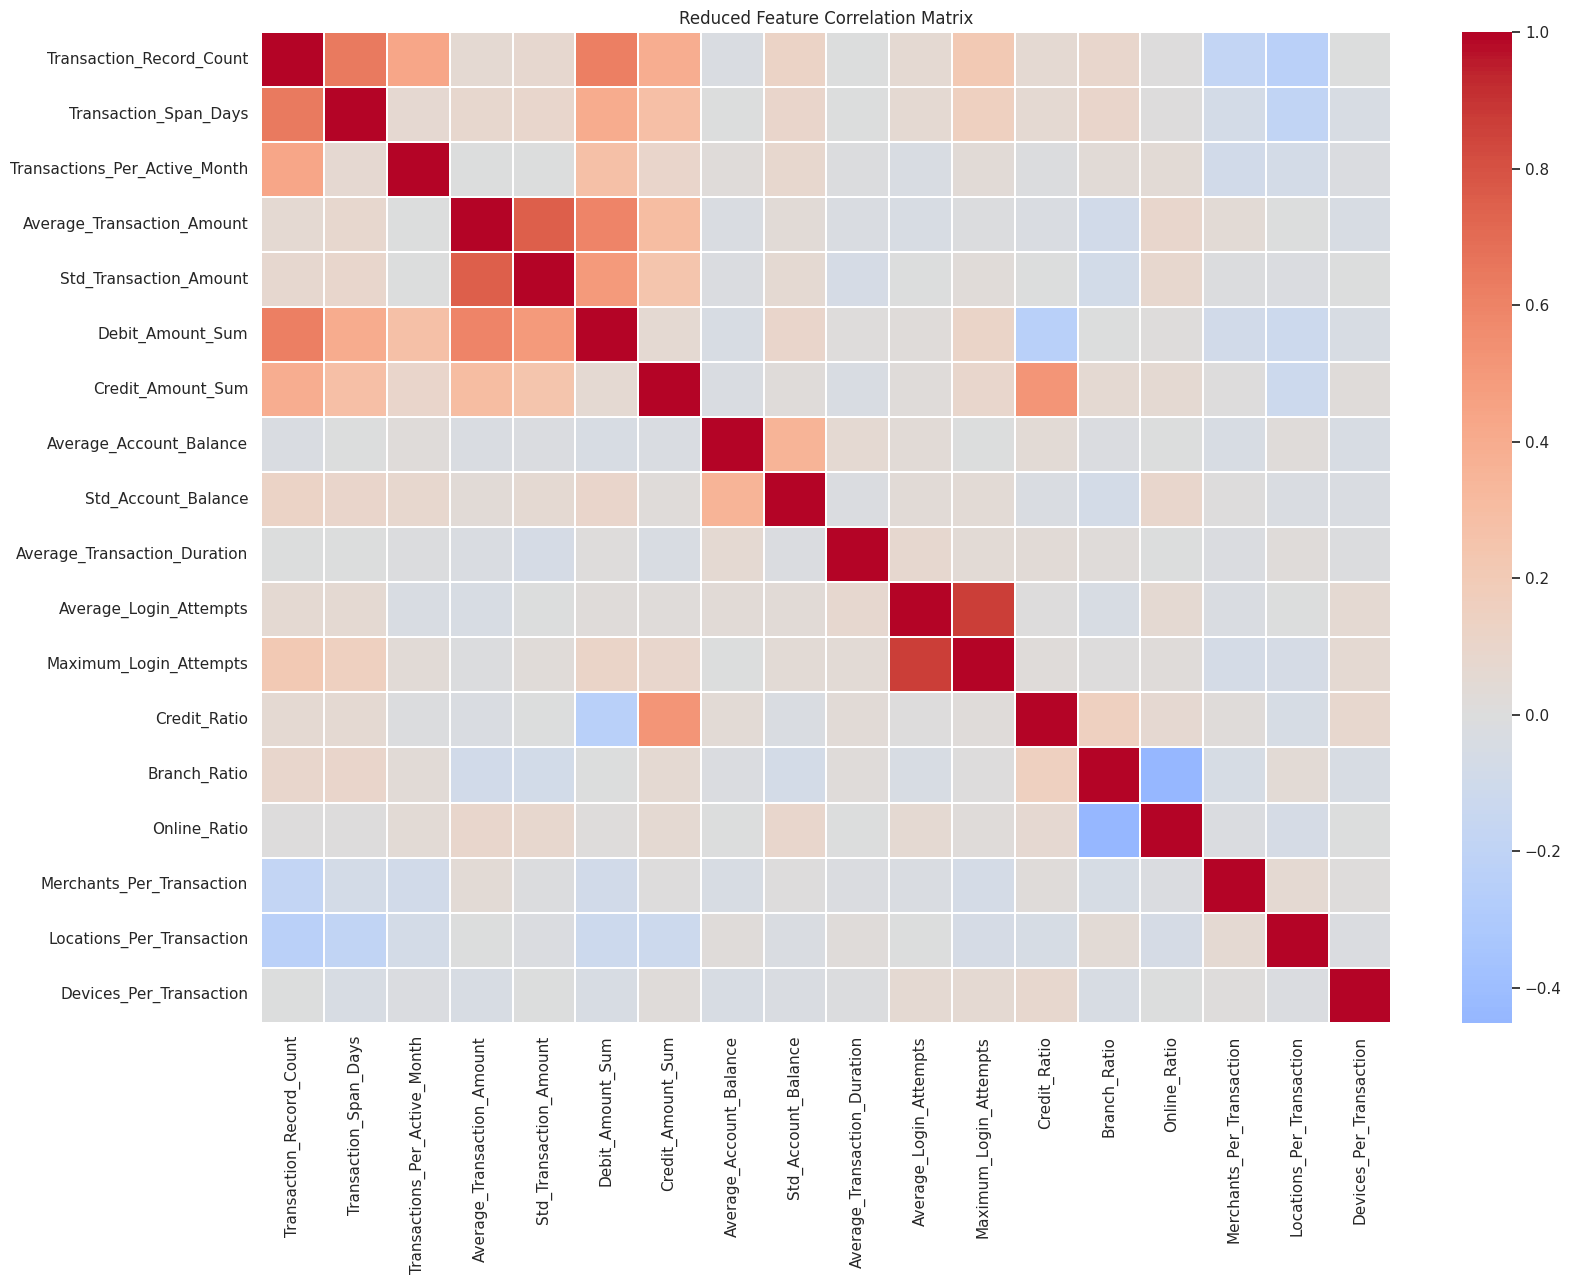

,Feature 1,Feature 2,Absolute Correlation


In [ ]:
# Calculating reduced feature correlation

reduced_correlation_matrix = X_reduced.corr()

plt.figure(figsize=(17, 13))

sns.heatmap(
    reduced_correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Reduced Feature Correlation Matrix")

plt.tight_layout()
plt.show()


# Identifying remaining high correlations

reduced_upper = (
    reduced_correlation_matrix.abs()
    .where(
        np.triu(
            np.ones(reduced_correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
)

reduced_high_correlation = (
    reduced_upper.stack()
    .reset_index()
)

reduced_high_correlation.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

reduced_high_correlation = (
    reduced_high_correlation[
        reduced_high_correlation["Absolute Correlation"] >= 0.90
    ]
    .sort_values(
        "Absolute Correlation",
        ascending=False
    )
)

display(reduced_high_correlation)

Hasil visualisasi reduced correlation matrix menunjukkan bahwa hubungan korelasi antarfitur secara umum menjadi lebih rendah dibandingkan representasi awal dengan 29 fitur.

Hal ini terlihat dari berkurangnya pasangan fitur yang memiliki warna korelasi sangat kuat pada heatmap.

Pemeriksaan lanjutan juga menunjukkan bahwa tidak terdapat pasangan fitur dengan nilai korelasi absolut sebesar 0,90 atau lebih.

Hasil tersebut menunjukkan bahwa proses feature selection berhasil mengurangi hubungan yang terlalu kuat antarfitur berdasarkan batas korelasi yang digunakan.

Dengan demikian, reduced feature matrix memiliki representasi fitur yang lebih ringkas dan tidak memiliki pasangan korelasi yang sangat tinggi berdasarkan batas yang ditentukan.

## 3.8 Feature Scaling and Transformation Experiments

Menguji pengaruh strategi transformasi dan feature scaling
terhadap representasi data yang digunakan dalam clustering.

Empat konfigurasi disiapkan:

A. Full 29 Features + StandardScaler
B. Reduced 18 Features + StandardScaler
C. Reduced 18 Features + RobustScaler
D. Reduced 18 Features + Log1p + RobustScaler

StandardScaler digunakan untuk mengubah fitur berdasarkan
mean dan standard deviation.

RobustScaler digunakan untuk melakukan scaling berdasarkan
median dan interquartile range, sehingga lebih tahan
terhadap pengaruh nilai ekstrem.

Log1p digunakan untuk fitur yang memiliki skewness positif
tinggi dan nilai non-negatif.

Fitur rasio yang memiliki rentang terbatas tidak langsung
diberi log transformation agar interpretasi proporsinya
tidak berubah secara tidak perlu.

Seluruh konfigurasi menggunakan AccountID dan jumlah
observasi yang sama untuk menjaga konsistensi eksperimen.

In [ ]:
# Preparing experimental data representations

data_spaces = {}

scaler_objects = {}


# A. Full Features + StandardScaler

scaler_full = StandardScaler()

X_full_standard = scaler_full.fit_transform(
    X_customer
)

data_spaces["A_Full29_Standard"] = pd.DataFrame(
    X_full_standard,
    index=X_customer.index,
    columns=X_customer.columns
)

scaler_objects["A_Full29_Standard"] = scaler_full


# B. Reduced Features + StandardScaler

scaler_reduced_standard = StandardScaler()

X_reduced_standard = scaler_reduced_standard.fit_transform(
    X_reduced
)

data_spaces["B_Reduced18_Standard"] = pd.DataFrame(
    X_reduced_standard,
    index=X_reduced.index,
    columns=X_reduced.columns
)

scaler_objects["B_Reduced18_Standard"] = (
    scaler_reduced_standard
)


# C. Reduced Features + RobustScaler

scaler_reduced_robust = RobustScaler()

X_reduced_robust = scaler_reduced_robust.fit_transform(
    X_reduced
)

data_spaces["C_Reduced18_Robust"] = pd.DataFrame(
    X_reduced_robust,
    index=X_reduced.index,
    columns=X_reduced.columns
)

scaler_objects["C_Reduced18_Robust"] = (
    scaler_reduced_robust
)


print("Initial scaling experiments completed.")

for name, data in data_spaces.items():

    print(name, ":", data.shape)

Initial scaling experiments completed.
A_Full29_Standard : (495, 29)
B_Reduced18_Standard : (495, 18)
C_Reduced18_Robust : (495, 18)


Hasil persiapan feature scaling menghasilkan tiga representasi data awal dengan jumlah observasi yang tetap sama, yaitu 495 pelanggan.

Representasi yang dihasilkan meliputi:

- A_Full29_Standard: menggunakan 29 fitur dengan StandardScaler.

- B_Reduced18_Standard: menggunakan 18 fitur dengan StandardScaler.

- C_Reduced18_Robust: menggunakan 18 fitur dengan RobustScaler.

Perbedaan utama dari ketiga konfigurasi tersebut terletak pada jumlah fitur dan metode scaling yang digunakan.

Pemisahan ini dilakukan untuk mengetahui apakah penggunaan fitur yang lebih sedikit dan metode scaling yang berbeda dapat memberikan hasil clustering yang lebih baik.

In [ ]:
# Identifying features suitable for log transformation

reduced_skewness = X_reduced.skew()

# Ratio features are excluded from Log1p transformation
bounded_features = [
    "Credit_Ratio",
    "Branch_Ratio",
    "Online_Ratio",
    "Merchants_Per_Transaction",
    "Locations_Per_Transaction",
    "Devices_Per_Transaction"
]

log_features = [
    column
    for column in X_reduced.columns

    if (
        reduced_skewness[column] > 1
        and X_reduced[column].min() >= 0
        and column not in bounded_features
    )
]

print("Features selected for Log1p transformation:")

display(
    pd.DataFrame({
        "Feature": log_features,
        "Skewness": [
            reduced_skewness[column]
            for column in log_features
        ]
    })
)

Features selected for Log1p transformation:


,Feature,Skewness
0,Transactions_Per_Active_Month,1.227496
1,Std_Transaction_Amount,1.144770
2,Credit_Amount_Sum,1.717860
3,Average_Login_Attempts,3.908830
4,Maximum_Login_Attempts,1.983934


Hasil identifikasi menunjukkan bahwa terdapat lima fitur yang memenuhi kriteria untuk dilakukan Log1p transformation.

Fitur tersebut adalah Transactions_Per_Active_Month dengan skewness 1,23, Std_Transaction_Amount sebesar 1,14, Credit_Amount_Sum sebesar 1,72, Average_Login_Attempts sebesar 3,91, dan Maximum_Login_Attempts sebesar 1,98.

Kelima fitur tersebut memiliki kecenderungan distribusi ke kanan dan nilai yang memenuhi persyaratan transformasi.

In [ ]:
# Applying Log1p transformation

X_reduced_log = X_reduced.copy()

for column in log_features:

    X_reduced_log[column] = np.log1p(
        X_reduced_log[column]
    )


# Applying RobustScaler after transformation

scaler_log_robust = RobustScaler()

X_log_robust = scaler_log_robust.fit_transform(
    X_reduced_log
)

data_spaces["D_Reduced18_Log1p_Robust"] = pd.DataFrame(
    X_log_robust,
    index=X_reduced_log.index,
    columns=X_reduced_log.columns
)

scaler_objects["D_Reduced18_Log1p_Robust"] = (
    scaler_log_robust
)


print("Log1p transformation completed.")

print("Transformed features:", len(log_features))

display(
    X_reduced_log[log_features].describe().T
)

Log1p transformation completed.
Transformed features: 5


,count,mean,std,min,25%,50%,75%,max
Transactions_Per_Active_Month,495.0,0.793400,0.107369,0.693147,0.693147,0.788457,0.847298,1.178655
Std_Transaction_Amount,495.0,5.381517,0.648739,2.226677,5.070729,5.449831,5.786623,6.766414
Credit_Amount_Sum,495.0,3.916913,2.842527,0.000000,0.000000,5.200484,6.246705,7.878996
Average_Login_Attempts,495.0,0.742164,0.113273,0.693147,0.693147,0.693147,0.693147,1.609438
Maximum_Login_Attempts,495.0,0.864826,0.348629,0.693147,0.693147,0.693147,0.693147,1.791759


Proses Log1p transformation berhasil diterapkan pada lima fitur yang telah dipilih sebelumnya.

Hasil statistik menunjukkan bahwa seluruh fitur memiliki 495 observasi setelah transformasi.

Transformasi ini mengubah skala nilai dengan cara memperkecil jarak antara nilai rendah dan nilai tinggi, sehingga nilai-nilai ekstrem tidak terlalu mendominasi rentang data.

Sebagai contoh, Credit_Amount_Sum yang sebelumnya memiliki rentang nilai hingga 2.640,22 telah berubah menjadi skala logaritmik dengan nilai maksimum sekitar 7,88.

Setelah transformasi, RobustScaler kembali diterapkan untuk menghasilkan representasi data keempat, yaitu D_Reduced18_Log1p_Robust.

Dengan demikian, empat konfigurasi representasi data telah tersedia untuk dibandingkan dalam eksperimen clustering.

## 3.9 Experimental Representation Validation

Melakukan validasi terhadap seluruh representasi data
yang telah dibentuk.

Pemeriksaan mencakup jumlah observasi, jumlah fitur,
missing values, infinite values, dan karakteristik
skala data setelah transformasi.

Tahap ini memastikan bahwa seluruh konfigurasi memiliki
jumlah AccountID yang sama dan dapat digunakan dalam
eksperimen clustering.

Jika ditemukan nilai tidak valid atau perbedaan jumlah
observasi, eksperimen harus dihentikan sampai masalahnya
diselesaikan.

In [ ]:
# Validating all experimental representations

representation_summary = []

for name, data in data_spaces.items():

    representation_summary.append({

        "Representation": name,

        "Observations": data.shape[0],

        "Features": data.shape[1],

        "Missing Values": data.isnull().sum().sum(),

        "Infinite Values": np.isinf(
            data.to_numpy()
        ).sum(),

        "Overall Mean": data.to_numpy().mean(),

        "Overall Standard Deviation": data.to_numpy().std()

    })


representation_summary_df = pd.DataFrame(
    representation_summary
)

display(representation_summary_df)


# Additional validation
for name, data in data_spaces.items():

    if data.shape[0] != X_customer.shape[0]:

        raise ValueError(
            f"Observation mismatch in {name}"
        )

    if not np.isfinite(data.to_numpy()).all():

        raise ValueError(
            f"Invalid values detected in {name}"
        )


print("All representations passed validation.")

,Representation,Observations,Features,Missing Values,Infinite Values,Overall Mean,Overall Standard Deviation
0,A_Full29_Standard,495,29,0,0,-2.375900e-17,1.000000
1,B_Reduced18_Standard,495,18,0,0,-9.509789e-17,1.000000
2,C_Reduced18_Robust,495,18,0,0,5.296075e-02,0.766992
3,D_Reduced18_Log1p_Robust,495,18,0,0,-1.733035e-02,0.682791


All representations passed validation.


Hasil validasi menunjukkan bahwa keempat representasi data memiliki jumlah observasi yang sama, yaitu 495 pelanggan.

Jumlah fitur berbeda sesuai dengan konfigurasi masing-masing, yaitu 29 fitur pada A_Full29_Standard dan 18 fitur pada tiga konfigurasi lainnya.

Seluruh representasi data juga tidak memiliki missing values maupun infinite values.

Pada konfigurasi StandardScaler, nilai rata-rata keseluruhan mendekati nol dengan standar deviasi sebesar satu. Hal tersebut menunjukkan bahwa proses standardization telah berjalan sesuai dengan tujuannya.

Sementara itu, konfigurasi RobustScaler memiliki nilai rata-rata dan standar deviasi yang berbeda karena metode ini menggunakan median dan interquartile range sebagai dasar scaling.

Berdasarkan seluruh hasil pemeriksaan, keempat representasi data berhasil melewati proses validasi dan siap digunakan dalam eksperimen clustering.

## 3.10 K-Means Clustering Experiment

Menerapkan K-Means Clustering pada empat representasi data
yang telah dipersiapkan.

K-Means merupakan algoritma clustering berbasis centroid
yang membagi observasi ke dalam beberapa kelompok
berdasarkan kedekatan jarak terhadap pusat cluster.

Eksperimen dilakukan dengan variasi jumlah cluster
mulai dari 2 hingga 8.

Setiap konfigurasi menggunakan random_state yang sama
serta beberapa inisialisasi centroid untuk mengurangi
ketergantungan terhadap pemilihan centroid awal.

Evaluasi dilakukan menggunakan:
1. Silhouette Score.
2. Davies-Bouldin Index.
3. Calinski-Harabasz Index.
4. Inertia.

Jumlah observasi pada setiap cluster juga diperiksa
untuk mengetahui keseimbangan hasil segmentasi.

Hasil eksperimen disimpan untuk dibandingkan dengan
algoritma clustering lainnya.

In [ ]:
# Running K-Means clustering experiments

kmeans_results = []

kmeans_models = {}

kmeans_labels = {}

cluster_range = range(2, 9)


for representation, data in data_spaces.items():

    for k in cluster_range:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=30,
            max_iter=500
        )

        labels = model.fit_predict(data)

        # Calculating evaluation metrics
        silhouette = silhouette_score(
            data,
            labels
        )

        db_index = davies_bouldin_score(
            data,
            labels
        )

        ch_index = calinski_harabasz_score(
            data,
            labels
        )

        # Checking cluster distribution
        cluster_sizes = pd.Series(labels).value_counts()

        kmeans_results.append({

            "Model": "K-Means",

            "Representation": representation,

            "Number of Clusters": k,

            "Silhouette Score": silhouette,

            "Davies-Bouldin Index": db_index,

            "Calinski-Harabasz Index": ch_index,

            "Inertia": model.inertia_,

            "Minimum Cluster Size": cluster_sizes.min(),

            "Maximum Cluster Size": cluster_sizes.max()

        })

        # Saving models and labels
        model_key = f"{representation}_KMeans_k{k}"

        kmeans_models[model_key] = model

        kmeans_labels[model_key] = labels


kmeans_results_df = pd.DataFrame(kmeans_results)

display(
    kmeans_results_df.sort_values(
        "Silhouette Score",
        ascending=False
    )
)

,Model,Representation,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia,Minimum Cluster Size,Maximum Cluster Size
14,K-Means,C_Reduced18_Robust,2,0.204832,1.777622,78.352540,4211.862268,83,412
0,K-Means,A_Full29_Standard,2,0.164061,1.955020,117.760726,11587.213616,222,273
15,K-Means,C_Reduced18_Robust,3,0.149895,2.073088,77.362801,3713.440354,74,263
16,K-Means,C_Reduced18_Robust,4,0.136179,1.975219,67.214941,3460.208785,75,205
17,K-Means,C_Reduced18_Robust,5,0.130733,1.953278,59.744780,3281.046566,60,190
21,K-Means,D_Reduced18_Log1p_Robust,2,0.127638,2.389353,79.849824,3402.630748,242,253
22,K-Means,D_Reduced18_Log1p_Robust,3,0.121735,2.119888,65.669140,3120.685418,103,206
18,K-Means,C_Reduced18_Robust,6,0.118548,2.151646,54.917119,3125.953670,60,112
8,K-Means,B_Reduced18_Standard,3,0.115418,2.361004,56.037621,7256.910552,69,227
19,K-Means,C_Reduced18_Robust,7,0.112910,1.996285,51.778866,2982.511435,41,104


Hasil eksperimen K-Means menunjukkan bahwa sebanyak 28 konfigurasi clustering telah diuji menggunakan empat representasi data dengan variasi jumlah cluster dari 2 hingga 8.

Berdasarkan hasil evaluasi, konfigurasi terbaik berdasarkan Silhouette Score adalah C_Reduced18_Robust dengan jumlah cluster sebanyak 2.

Konfigurasi tersebut menghasilkan Silhouette Score sebesar 0,2048, Davies-Bouldin Index sebesar 1,7776, dan Calinski-Harabasz Index sebesar 78,35.

Namun, distribusi cluster yang terbentuk masih belum seimbang. Cluster terkecil memiliki 83 pelanggan, sedangkan cluster terbesar memiliki 412 pelanggan.

Di sisi lain, konfigurasi A_Full29_Standard dengan dua cluster menghasilkan Silhouette Score sebesar 0,1641 dan Calinski-Harabasz Index tertinggi di antara hasil K-Means, yaitu 117,76.

Konfigurasi tersebut menghasilkan distribusi yang lebih seimbang, dengan ukuran cluster sebesar 222 dan 273 pelanggan.

Hasil ini menunjukkan bahwa konfigurasi dengan Silhouette Score tertinggi belum tentu menghasilkan distribusi cluster yang paling seimbang.

Oleh karena itu, pemilihan konfigurasi K-Means perlu mempertimbangkan beberapa metrik evaluasi sekaligus, termasuk distribusi jumlah pelanggan pada setiap cluster.

## 3.11 K-Means Elbow Method Visualization

Memvisualisasikan perubahan Inertia terhadap jumlah cluster
pada setiap representasi data.

Inertia mengukur total squared distance antara observasi
dengan centroid cluster masing-masing.

Semakin banyak cluster yang digunakan, Inertia umumnya
akan semakin rendah.

Elbow Method digunakan untuk mengidentifikasi titik ketika
penambahan jumlah cluster mulai memberikan pengurangan
Inertia yang semakin kecil.

Grafik dianalisis secara terpisah untuk setiap representasi
karena skala Inertia dapat berbeda akibat perbedaan jumlah
fitur dan strategi transformasi.

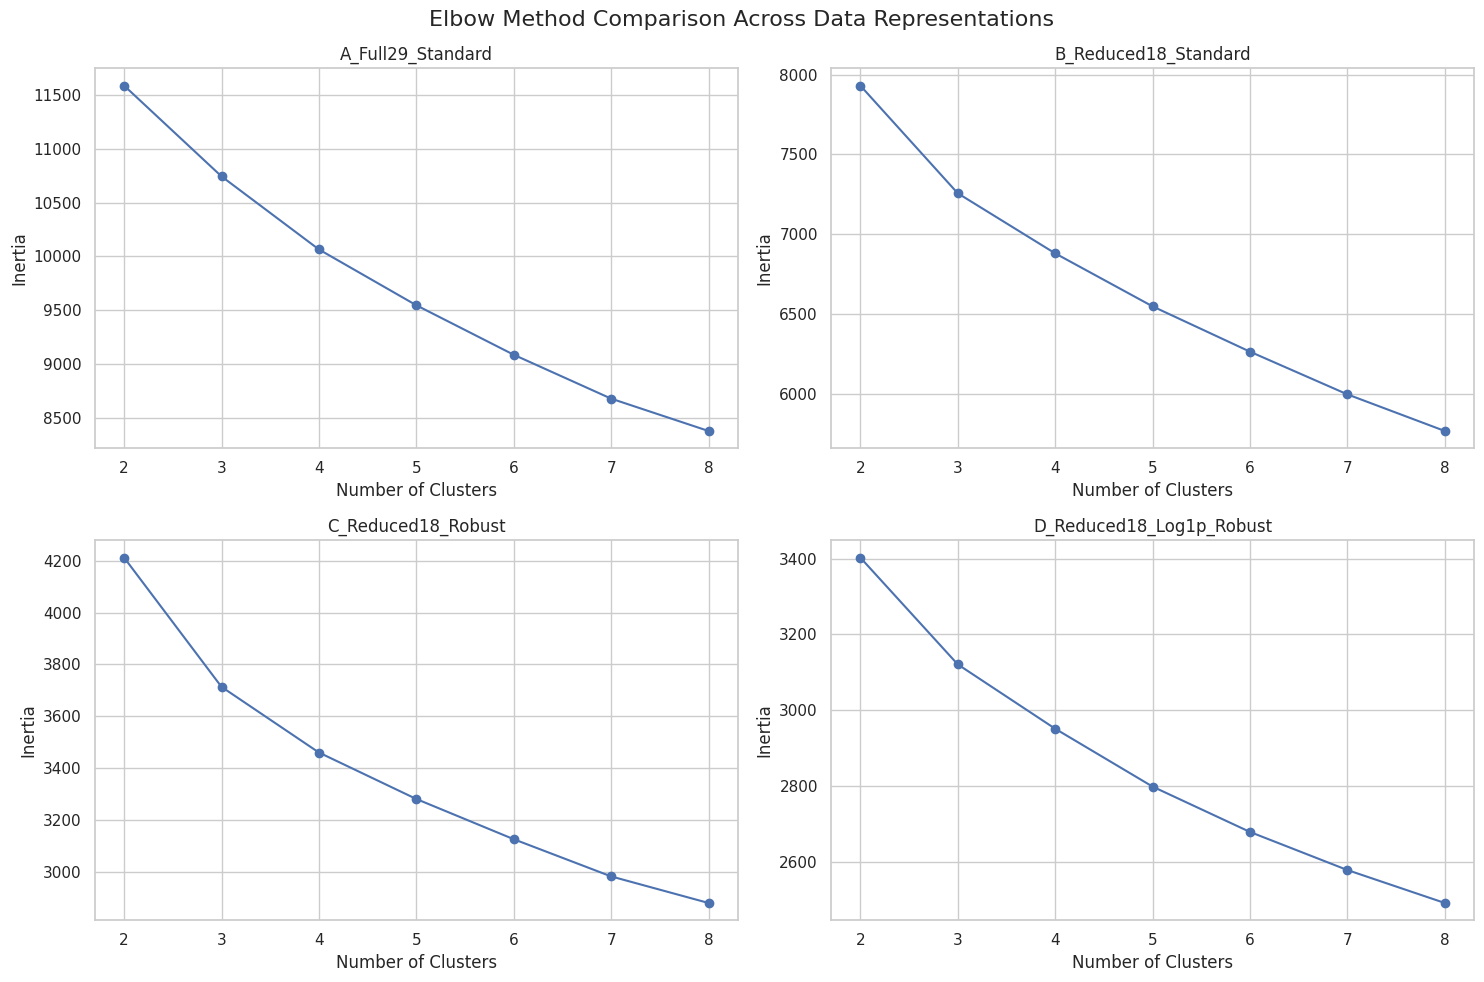

In [ ]:
# Visualizing K-Means Elbow Method

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

axes = axes.flatten()

for ax, representation in zip(
    axes,
    data_spaces.keys()
):

    subset = kmeans_results_df[
        kmeans_results_df["Representation"] == representation
    ]

    ax.plot(
        subset["Number of Clusters"],
        subset["Inertia"],
        marker="o"
    )

    ax.set_title(representation)

    ax.set_xlabel("Number of Clusters")

    ax.set_ylabel("Inertia")

    ax.set_xticks(list(cluster_range))

    ax.grid(True)


plt.suptitle(
    "Elbow Method Comparison Across Data Representations",
    fontsize=16
)

plt.tight_layout()
plt.show()

Hasil visualisasi Elbow Method menunjukkan bahwa nilai Inertia terus mengalami penurunan seiring dengan bertambahnya jumlah cluster.

Penurunan paling terlihat terjadi ketika jumlah cluster meningkat dari 2 menjadi 3, khususnya pada representasi C_Reduced18_Robust.

Namun, tidak terlihat titik elbow yang benar-benar jelas pada seluruh representasi data. Penurunan Inertia masih berlangsung secara bertahap ketika jumlah cluster ditingkatkan.

Hal tersebut menunjukkan bahwa grafik Elbow Method belum dapat memberikan keputusan yang pasti mengenai jumlah cluster paling optimal.

Oleh karena itu, penentuan jumlah cluster perlu didukung dengan hasil evaluasi lainnya, seperti Silhouette Score, Davies-Bouldin Index, dan distribusi anggota cluster.

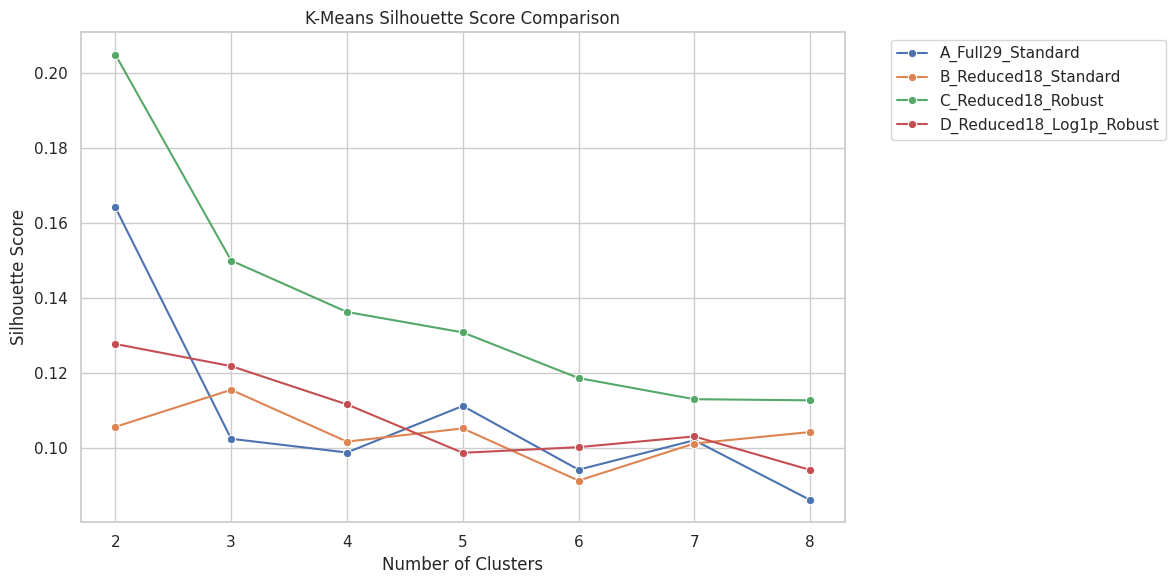

In [ ]:
# Visualizing K-Means Silhouette Scores

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=kmeans_results_df,
    x="Number of Clusters",
    y="Silhouette Score",
    hue="Representation",
    marker="o"
)

plt.title("K-Means Silhouette Score Comparison")

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.xticks(list(cluster_range))

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Hasil visualisasi Silhouette Score menunjukkan bahwa representasi C_Reduced18_Robust secara konsisten menghasilkan nilai yang lebih tinggi dibandingkan representasi lainnya pada berbagai jumlah cluster.

Nilai tertinggi diperoleh ketika menggunakan dua cluster, yaitu sekitar 0,2048.

Setelah jumlah cluster ditingkatkan, nilai Silhouette Score pada representasi tersebut cenderung mengalami penurunan secara bertahap.

Sementara itu, representasi A_Full29_Standard, B_Reduced18_Standard, dan D_Reduced18_Log1p_Robust menghasilkan nilai Silhouette Score yang relatif lebih rendah.

Hasil ini menunjukkan bahwa penggunaan 18 fitur dengan RobustScaler memberikan pemisahan cluster yang relatif lebih baik dalam eksperimen K-Means.

Meskipun demikian, nilai Silhouette Score yang masih relatif rendah menunjukkan bahwa pemisahan antarcluster belum terlalu kuat

## 3.12 Agglomerative Clustering Experiment

Menerapkan Agglomerative Clustering pada seluruh
representasi data yang telah dipersiapkan.

Agglomerative Clustering merupakan pendekatan hierarchical
clustering yang dimulai dengan menganggap setiap observasi
sebagai cluster terpisah.

Cluster kemudian digabungkan secara bertahap berdasarkan
jarak dan kriteria linkage yang digunakan.

Eksperimen menggunakan Ward Linkage dengan variasi
jumlah cluster dari 2 hingga 8.

Ward Linkage berusaha meminimalkan peningkatan within-cluster
variance pada setiap proses penggabungan.

Evaluasi dilakukan menggunakan Silhouette Score,
Davies-Bouldin Index, dan Calinski-Harabasz Index.

Hasil eksperimen akan dibandingkan dengan K-Means
untuk mengetahui perbedaan karakteristik kedua pendekatan.

In [ ]:
# Running Agglomerative Clustering experiments

agglomerative_results = []

agglomerative_models = {}

agglomerative_labels = {}


for representation, data in data_spaces.items():

    for k in cluster_range:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = model.fit_predict(data)

        # Calculating evaluation metrics
        silhouette = silhouette_score(
            data,
            labels
        )

        db_index = davies_bouldin_score(
            data,
            labels
        )

        ch_index = calinski_harabasz_score(
            data,
            labels
        )

        # Checking cluster distribution
        cluster_sizes = pd.Series(labels).value_counts()

        agglomerative_results.append({

            "Model": "Agglomerative",

            "Representation": representation,

            "Number of Clusters": k,

            "Silhouette Score": silhouette,

            "Davies-Bouldin Index": db_index,

            "Calinski-Harabasz Index": ch_index,

            "Inertia": np.nan,

            "Minimum Cluster Size": cluster_sizes.min(),

            "Maximum Cluster Size": cluster_sizes.max()

        })

        # Saving models and labels
        model_key = f"{representation}_Agglomerative_k{k}"

        agglomerative_models[model_key] = model

        agglomerative_labels[model_key] = labels


agglomerative_results_df = pd.DataFrame(
    agglomerative_results
)

display(
    agglomerative_results_df.sort_values(
        "Silhouette Score",
        ascending=False
    )
)

,Model,Representation,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia,Minimum Cluster Size,Maximum Cluster Size
14,Agglomerative,C_Reduced18_Robust,2,0.194771,1.813585,75.561890,NaN,84,411
0,Agglomerative,A_Full29_Standard,2,0.133381,2.273857,83.979258,NaN,191,304
16,Agglomerative,C_Reduced18_Robust,4,0.117671,2.203064,58.585153,NaN,74,185
15,Agglomerative,C_Reduced18_Robust,3,0.110569,2.466032,65.078669,NaN,84,226
9,Agglomerative,B_Reduced18_Standard,4,0.106501,2.248780,42.342693,NaN,27,255
8,Agglomerative,B_Reduced18_Standard,3,0.105972,2.565920,48.828155,NaN,72,255
21,Agglomerative,D_Reduced18_Log1p_Robust,2,0.101762,2.759012,59.289277,NaN,216,279
18,Agglomerative,C_Reduced18_Robust,6,0.095671,2.027878,47.342844,NaN,32,185
11,Agglomerative,B_Reduced18_Standard,6,0.094669,2.039054,35.390673,NaN,27,228
22,Agglomerative,D_Reduced18_Log1p_Robust,3,0.094118,2.380892,52.716043,NaN,94,216


Hasil eksperimen Agglomerative Clustering menunjukkan bahwa sebanyak 28 konfigurasi telah diuji menggunakan empat representasi data dengan variasi jumlah cluster dari 2 hingga 8.

Konfigurasi dengan hasil terbaik berdasarkan Silhouette Score adalah C_Reduced18_Robust dengan dua cluster.

Konfigurasi tersebut menghasilkan Silhouette Score sebesar 0,1948, Davies-Bouldin Index sebesar 1,8136, dan Calinski-Harabasz Index sebesar 75,56.

Distribusi cluster menunjukkan bahwa cluster terkecil memiliki 84 pelanggan, sedangkan cluster terbesar memiliki 411 pelanggan.

Hasil tersebut memperlihatkan bahwa Agglomerative Clustering dengan representasi reduced feature dan RobustScaler juga mampu menghasilkan pemisahan cluster yang relatif lebih baik dibandingkan sebagian besar konfigurasi lainnya.

Namun, nilai Silhouette Score masih menunjukkan bahwa pemisahan antarcluster belum terlalu kuat.

## 3.13 Initial Comparison: K-Means vs Agglomerative

Menggabungkan hasil eksperimen K-Means dan Agglomerative
Clustering untuk membandingkan performa kedua algoritma.

Perbandingan dilakukan berdasarkan:
1. Silhouette Score.
2. Davies-Bouldin Index.
3. Calinski-Harabasz Index.
4. Jumlah cluster.
5. Ukuran minimum dan maksimum cluster.

Hasil perbandingan digunakan untuk mengidentifikasi
konfigurasi yang memiliki karakteristik pemisahan cluster
paling menjanjikan.

Perlu diperhatikan bahwa skor evaluasi tidak menjadi
satu-satunya dasar pemilihan model.

Keseimbangan ukuran cluster serta karakteristik data
juga perlu dipertimbangkan.

In [ ]:
# Combining K-Means and Agglomerative results

partitioning_results_df = pd.concat(
    [
        kmeans_results_df,
        agglomerative_results_df
    ],
    ignore_index=True
)


# Sorting the results
partitioning_results_sorted = (
    partitioning_results_df
    .sort_values(
        by="Silhouette Score",
        ascending=False
    )
    .reset_index(drop=True)
)


# Displaying the comparison
display(
    partitioning_results_sorted[
        [
            "Model",
            "Representation",
            "Number of Clusters",
            "Silhouette Score",
            "Davies-Bouldin Index",
            "Calinski-Harabasz Index",
            "Minimum Cluster Size",
            "Maximum Cluster Size"
        ]
    ].head(20)
)

,Model,Representation,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Minimum Cluster Size,Maximum Cluster Size
0,K-Means,C_Reduced18_Robust,2,0.204832,1.777622,78.352540,83,412
1,Agglomerative,C_Reduced18_Robust,2,0.194771,1.813585,75.561890,84,411
2,K-Means,A_Full29_Standard,2,0.164061,1.955020,117.760726,222,273
3,K-Means,C_Reduced18_Robust,3,0.149895,2.073088,77.362801,74,263
4,K-Means,C_Reduced18_Robust,4,0.136179,1.975219,67.214941,75,205
5,Agglomerative,A_Full29_Standard,2,0.133381,2.273857,83.979258,191,304
6,K-Means,C_Reduced18_Robust,5,0.130733,1.953278,59.744780,60,190
7,K-Means,D_Reduced18_Log1p_Robust,2,0.127638,2.389353,79.849824,242,253
8,K-Means,D_Reduced18_Log1p_Robust,3,0.121735,2.119888,65.669140,103,206
9,K-Means,C_Reduced18_Robust,6,0.118548,2.151646,54.917119,60,112


Hasil perbandingan pada konfigurasi C_Reduced18_Robust dengan dua cluster menunjukkan bahwa K-Means memberikan performa evaluasi yang sedikit lebih unggul dibandingkan Agglomerative Clustering.

K-Means mencatatkan skor yang lebih baik di seluruh metrik, meliputi Silhouette Score yang lebih tinggi (0,2048 vs 0,1948), Davies-Bouldin Index yang lebih rendah (1,7776 vs 1,8136), serta Calinski-Harabasz Index yang lebih besar (78,35 vs 75,56).

Meskipun K-Means lebih optimal, distribusi ukuran cluster pada kedua model tergolong mirip dan masih cukup timpang, masing-masing membagi data menjadi 83 dan 412 pelanggan untuk K-Means, serta 84 dan 411 pelanggan untuk Agglomerative Clustering. Oleh karena itu, karakteristik dari masing-masing kelompok masih perlu dianalisis lebih lanjut.

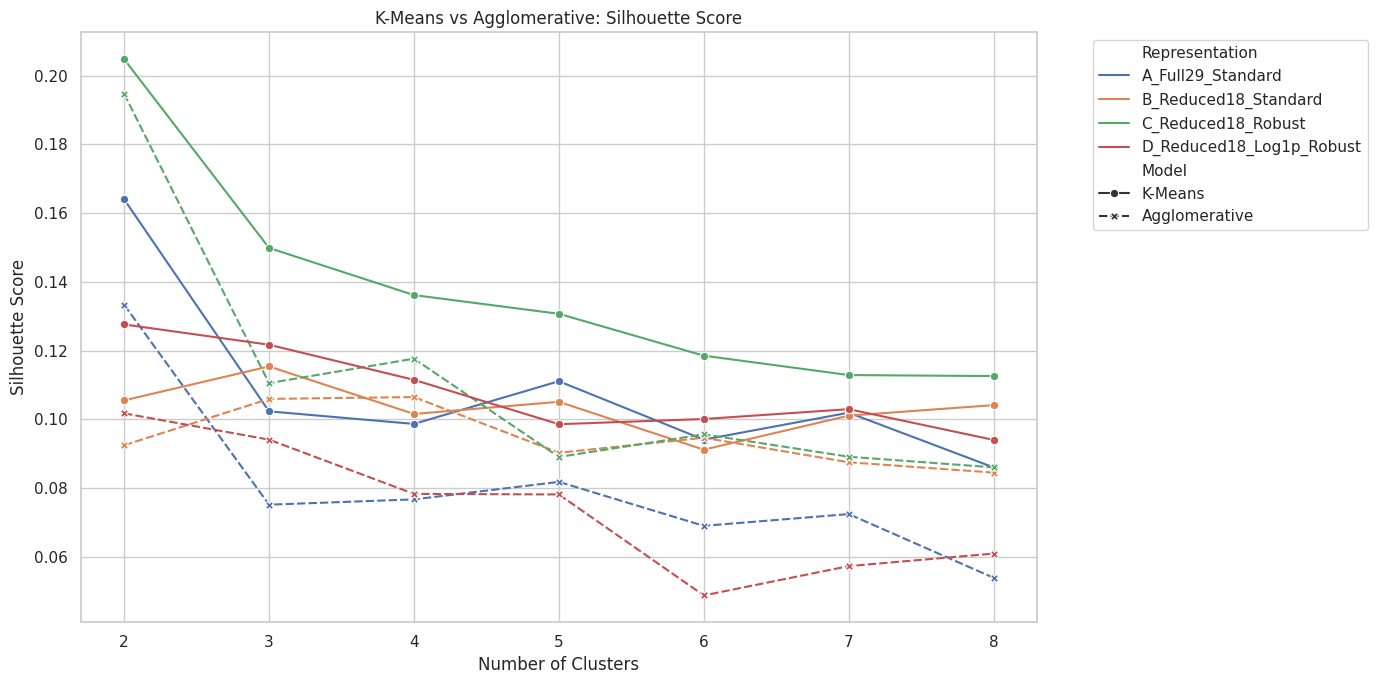

In [ ]:
# Comparing K-Means and Agglomerative Silhouette Scores (Visual Perbandingan)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=partitioning_results_df,
    x="Number of Clusters",
    y="Silhouette Score",
    hue="Representation",
    style="Model",
    markers=True,
    dashes=True
)

plt.title(
    "K-Means vs Agglomerative: Silhouette Score"
)

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.xticks(list(cluster_range))

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Hasil visualisasi menunjukkan bahwa K-Means dan Agglomerative Clustering memiliki pola perubahan Silhouette Score yang relatif serupa.

Representasi C_Reduced18_Robust menghasilkan nilai tertinggi pada kedua algoritma ketika menggunakan dua cluster.

Selain itu, K-Means cenderung menghasilkan nilai Silhouette Score yang sedikit lebih tinggi dibandingkan Agglomerative Clustering pada beberapa konfigurasi.

Temuan ini memperkuat hasil perbandingan sebelumnya bahwa penggunaan reduced feature dengan RobustScaler merupakan salah satu konfigurasi yang paling menjanjikan.

## 3.14 DBSCAN: K-Distance Analysis

Melakukan analisis K-Distance untuk membantu menentukan
rentang parameter eps yang akan digunakan dalam DBSCAN.

K-Distance Plot menunjukkan distribusi jarak dari setiap
observasi menuju tetangga ke-k.

Eksperimen dilakukan menggunakan beberapa nilai
min_samples, yaitu 5, 10, dan 15.

Perubahan kemiringan pada kurva digunakan sebagai indikasi
awal untuk menentukan rentang eps yang layak diuji.

Nilai eps tidak ditetapkan hanya berdasarkan satu titik
pada grafik, melainkan akan diuji menggunakan beberapa
kandidat nilai pada eksperimen berikutnya.

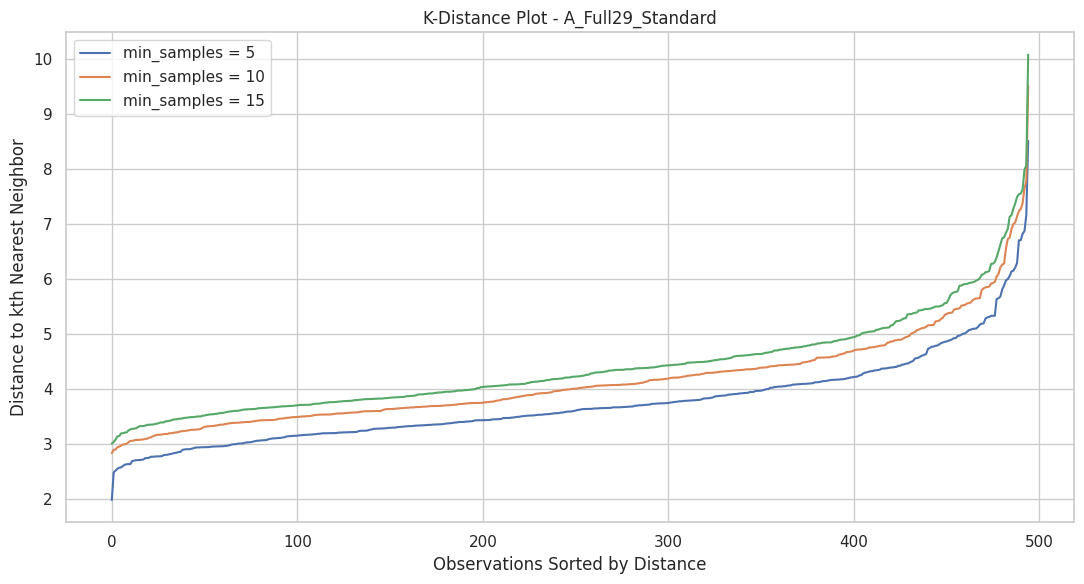

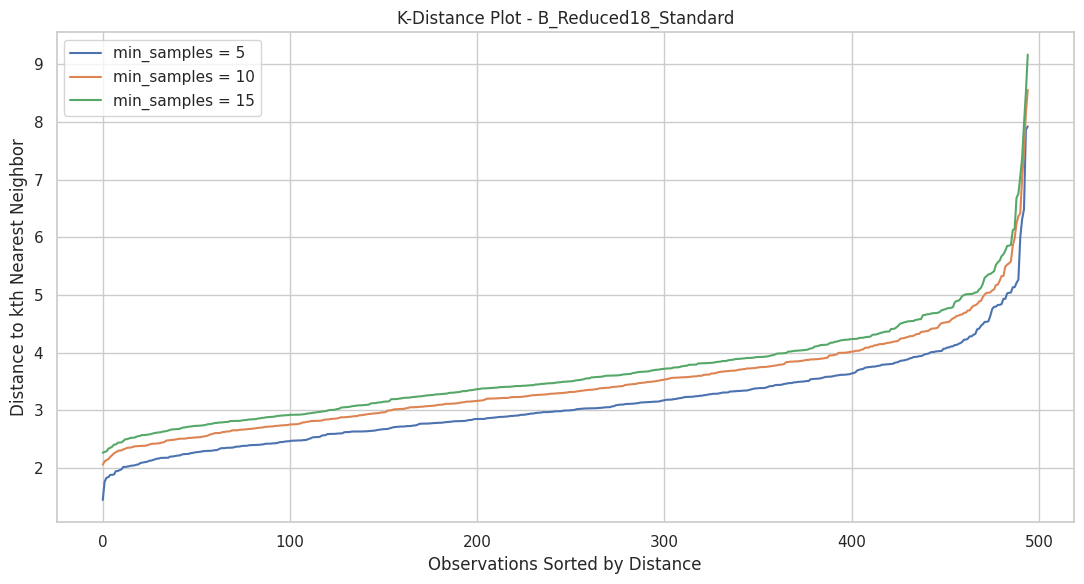

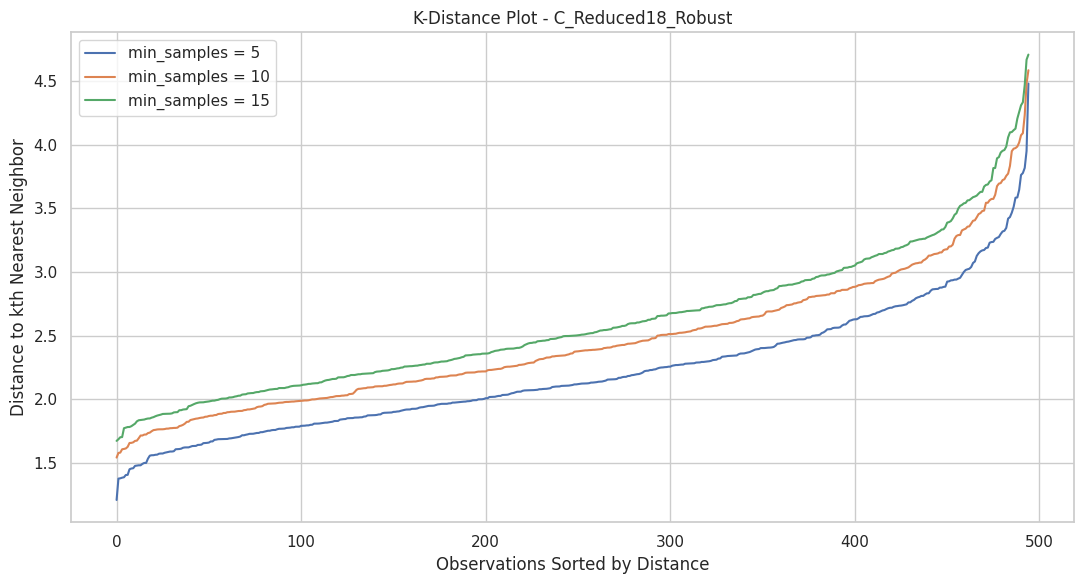

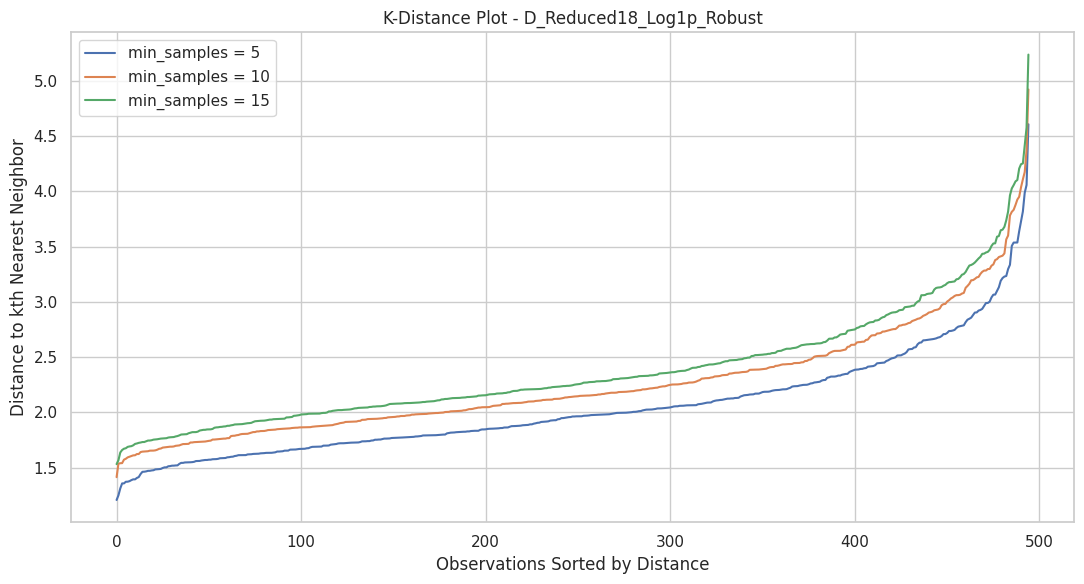

In [ ]:
# Performing K-Distance Analysis

min_samples_options = [5, 10, 15]

nearest_neighbor_distances = {}

eps_quantiles = [
    0.70,
    0.80,
    0.90,
    0.95,
    0.975
]


for representation, data in data_spaces.items():

    plt.figure(figsize=(11, 6))

    for min_samples in min_samples_options:

        neighbors = NearestNeighbors(
            n_neighbors=min_samples
        )

        neighbors.fit(data)

        distances, indices = neighbors.kneighbors(data)

        # Extracting distance to kth nearest neighbor
        k_distances = np.sort(
            distances[:, -1]
        )

        nearest_neighbor_distances[
            (representation, min_samples)
        ] = k_distances

        plt.plot(
            k_distances,
            label=f"min_samples = {min_samples}"
        )


    plt.title(
        f"K-Distance Plot - {representation}"
    )

    plt.xlabel("Observations Sorted by Distance")

    plt.ylabel("Distance to kth Nearest Neighbor")

    plt.legend()

    plt.tight_layout()

    plt.show()

Hasil visualisasi K-Distance menunjukkan bahwa jarak antarobservasi mengalami peningkatan secara bertahap, kemudian meningkat lebih tajam pada bagian akhir grafik.

Bagian kurva yang mengalami peningkatan tajam menunjukkan adanya sejumlah observasi yang memiliki jarak relatif lebih jauh terhadap tetangga terdekatnya.

Pola tersebut dapat digunakan sebagai petunjuk awal untuk menentukan nilai eps dalam algoritma DBSCAN.

Selain itu, peningkatan nilai min_samples dari 5 menjadi 10 dan 15 menghasilkan jarak tetangga ke-k yang lebih besar.

Perbedaan rentang jarak juga terlihat pada masing-masing representasi data. Hal ini menunjukkan bahwa metode scaling dan transformasi memengaruhi struktur jarak antarobservasi.

Namun, tidak terlihat satu titik elbow yang benar-benar tegas pada seluruh grafik.

Oleh karena itu, nilai eps tidak ditentukan hanya berdasarkan pengamatan visual, tetapi diuji menggunakan beberapa kandidat nilai yang diperoleh dari distribusi K-Distance.

## 3.15 DBSCAN Parameter Experiment

Menerapkan DBSCAN pada seluruh representasi data dengan
menguji kombinasi parameter eps dan min_samples.

Kandidat eps diperoleh dari beberapa kuantil distribusi
jarak tetangga terdekat pada K-Distance Analysis.

Nilai min_samples yang digunakan adalah 5, 10, dan 15.

Evaluasi mencakup:
1. Jumlah cluster yang terbentuk.
2. Jumlah dan persentase noise.
3. Persentase observasi yang berhasil dikelompokkan.
4. Silhouette Score.
5. Davies-Bouldin Index.
6. Calinski-Harabasz Index.
7. Ukuran minimum dan maksimum cluster.

Observasi dengan label -1 dianggap sebagai noise dan
dikeluarkan dari perhitungan metrik internal.

Persentase noise tetap dilaporkan untuk memastikan bahwa
nilai evaluasi tidak terlihat tinggi hanya karena model
mengelompokkan sebagian kecil observasi.

Konfigurasi DBSCAN dengan kurang dari dua cluster
non-noise tidak dapat dievaluasi menggunakan tiga
metrik pemisahan cluster.

In [ ]:
# Creating DBSCAN evaluation function (Fungsi Evaluasi DBSCAN)

def evaluate_dbscan(data, labels):

    labels = np.asarray(labels)

    noise_mask = labels == -1

    non_noise_mask = ~noise_mask

    non_noise_data = data.iloc[
        np.where(non_noise_mask)[0]
    ]

    non_noise_labels = labels[non_noise_mask]

    n_clusters = len(
        np.unique(non_noise_labels)
    )

    noise_count = int(noise_mask.sum())

    noise_percentage = (
        noise_count / len(labels) * 100
    )

    coverage_percentage = (
        non_noise_mask.sum() / len(labels) * 100
    )

    silhouette = np.nan

    db_index = np.nan

    ch_index = np.nan

    # Calculate metrics only when at least 2 valid clusters exist
    if (
        n_clusters >= 2
        and n_clusters < len(non_noise_labels)
    ):

        silhouette = silhouette_score(
            non_noise_data,
            non_noise_labels
        )

        db_index = davies_bouldin_score(
            non_noise_data,
            non_noise_labels
        )

        ch_index = calinski_harabasz_score(
            non_noise_data,
            non_noise_labels
        )

    # Cluster size analysis
    cluster_sizes = pd.Series(
        non_noise_labels
    ).value_counts()

    if len(cluster_sizes) > 0:

        min_cluster_size = cluster_sizes.min()

        max_cluster_size = cluster_sizes.max()

    else:

        min_cluster_size = 0

        max_cluster_size = 0


    return {

        "Number of Clusters": n_clusters,

        "Noise Count": noise_count,

        "Noise Percentage": noise_percentage,

        "Coverage Percentage": coverage_percentage,

        "Silhouette Score": silhouette,

        "Davies-Bouldin Index": db_index,

        "Calinski-Harabasz Index": ch_index,

        "Minimum Cluster Size": min_cluster_size,

        "Maximum Cluster Size": max_cluster_size

    }

In [ ]:
# Running DBSCAN parameter experiments (Experimen DBSCAN)

dbscan_results = []

dbscan_models = {}

dbscan_labels = {}


for representation, data in data_spaces.items():

    for min_samples in min_samples_options:

        # Retrieving k-distance values
        k_distances = nearest_neighbor_distances[
            (representation, min_samples)
        ]

        # Generating candidate eps values
        eps_candidates = np.quantile(
            k_distances,
            eps_quantiles
        )

        eps_candidates = np.unique(
            np.round(eps_candidates, 6)
        )

        # Excluding zero or negative eps
        eps_candidates = eps_candidates[
            eps_candidates > 0
        ]


        for eps in eps_candidates:

            model = DBSCAN(
                eps=float(eps),
                min_samples=min_samples,
                metric="euclidean"
            )

            labels = model.fit_predict(data)

            # Evaluating DBSCAN configuration
            metrics = evaluate_dbscan(
                data,
                labels
            )

            dbscan_results.append({

                "Model": "DBSCAN",

                "Representation": representation,

                "Eps": float(eps),

                "Min Samples": min_samples,

                **metrics

            })


            # Saving model and labels
            model_key = (
                f"{representation}_DBSCAN_"
                f"eps{eps}_min{min_samples}"
            )

            dbscan_models[model_key] = model

            dbscan_labels[model_key] = labels


dbscan_results_df = pd.DataFrame(
    dbscan_results
)


print(
    "Total DBSCAN configurations:",
    len(dbscan_results_df)
)

display(
    dbscan_results_df.sort_values(
        by=[
            "Silhouette Score",
            "Coverage Percentage"
        ],
        ascending=[False, False],
        na_position="last"
    ).head(20)
)

Total DBSCAN configurations: 60


,Model,Representation,Eps,Min Samples,Number of Clusters,Noise Count,Noise Percentage,Coverage Percentage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Minimum Cluster Size,Maximum Cluster Size
46,DBSCAN,D_Reduced18_Log1p_Robust,2.348110,5,2,48,9.696970,90.303030,0.223859,1.112930,7.730148,4,443
0,DBSCAN,A_Full29_Standard,3.945862,5,2,65,13.131313,86.868687,0.219316,0.875842,6.868096,3,427
30,DBSCAN,C_Reduced18_Robust,2.388975,5,2,72,14.545455,85.454545,0.175951,1.079326,5.220811,3,420
59,DBSCAN,D_Reduced18_Log1p_Robust,3.717264,15,1,0,0.000000,100.000000,NaN,NaN,NaN,495,495
14,DBSCAN,A_Full29_Standard,6.811935,15,1,1,0.202020,99.797980,NaN,NaN,NaN,494,494
34,DBSCAN,C_Reduced18_Robust,3.339162,5,1,1,0.202020,99.797980,NaN,NaN,NaN,494,494
39,DBSCAN,C_Reduced18_Robust,3.747113,10,1,1,0.202020,99.797980,NaN,NaN,NaN,494,494
43,DBSCAN,C_Reduced18_Robust,3.643054,15,1,1,0.202020,99.797980,NaN,NaN,NaN,494,494
44,DBSCAN,C_Reduced18_Robust,3.976966,15,1,1,0.202020,99.797980,NaN,NaN,NaN,494,494
9,DBSCAN,A_Full29_Standard,6.457007,10,1,2,0.404040,99.595960,NaN,NaN,NaN,493,493


Hasil eksperimen dari 60 kombinasi parameter DBSCAN menunjukkan bahwa konfigurasi terbaik diperoleh pada representasi data D_Reduced18_Log1p_Robust (eps = 2,348110; min_samples = 5).

Konfigurasi ini membentuk dua cluster dengan Silhouette Score tertinggi sebesar 0,2239 dan Davies-Bouldin Index 1,1129. Namun, distribusinya sangat tidak seimbang karena satu cluster mencakup 443 pelanggan sementara cluster lainnya hanya berisi 4 pelanggan, serta menyisakan 48 observasi (9,70%) sebagai noise.

Sementara itu, representasi A_Full29_Standard juga mencatat Silhouette Score yang cukup tinggi (0,2193), tetapi menghasilkan proporsi noise yang lebih besar, yakni 65 observasi (13,13%).

In [ ]:
# Summarizing DBSCAN clustering outcomes (Distribusi Jumlah Cluster dan Noise DBSCAN)

dbscan_distribution = (
    dbscan_results_df
    .groupby("Representation")
    .agg(
        Average_Clusters=(
            "Number of Clusters", "mean"
        ),

        Average_Noise_Percentage=(
            "Noise Percentage", "mean"
        ),

        Average_Coverage=(
            "Coverage Percentage", "mean"
        ),

        Valid_Silhouette_Results=(
            "Silhouette Score",
            "count"
        )
    )
    .reset_index()
)

display(dbscan_distribution)

,Representation,Average_Clusters,Average_Noise_Percentage,Average_Coverage,Valid_Silhouette_Results
0,A_Full29_Standard,1.066667,4.148148,95.851852,1
1,B_Reduced18_Standard,1.000000,4.282828,95.717172,0
2,C_Reduced18_Robust,1.066667,3.946128,96.053872,1
3,D_Reduced18_Log1p_Robust,1.066667,5.063973,94.936027,1


Hasil rangkuman menunjukkan bahwa rata-rata jumlah cluster yang terbentuk pada setiap representasi data berada di sekitar satu cluster.

Representasi A_Full29_Standard dan C_Reduced18_Robust menghasilkan rata-rata jumlah cluster sebesar 1,07. Sementara itu, B_Reduced18_Standard menghasilkan rata-rata satu cluster.

Persentase noise rata-rata berada pada kisaran 3,95% hingga 5,06%, dengan C_Reduced18_Robust menghasilkan persentase noise rata-rata terendah sebesar 3,95%.

Namun, jumlah hasil yang memiliki Silhouette Score valid hanya satu pada representasi A, C, dan D. Sementara itu, representasi B tidak menghasilkan konfigurasi dengan Silhouette Score valid.

Temuan ini menunjukkan bahwa sebagian besar kombinasi parameter DBSCAN belum mampu membentuk minimal dua cluster non-noise yang dapat dievaluasi.

Oleh karena itu, DBSCAN perlu dipertimbangkan secara hati-hati karena hasil clustering yang terbentuk belum konsisten menghasilkan beberapa kelompok pelanggan yang dapat digunakan untuk segmentasi.

## 3.16 Comprehensive Model Comparison

Menggabungkan seluruh hasil eksperimen K-Means,
Agglomerative Clustering, dan DBSCAN.

Tujuannya adalah membandingkan kualitas hasil clustering
berdasarkan beberapa metrik evaluasi internal serta
karakteristik distribusi cluster.

Aspek yang dibandingkan:
1. Silhouette Score.
2. Davies-Bouldin Index.
3. Calinski-Harabasz Index.
4. Jumlah cluster.
5. Minimum dan maximum cluster size.
6. Coverage percentage.
7. Noise percentage untuk DBSCAN.

Khusus DBSCAN, metrik internal dihitung hanya berdasarkan
observasi yang bukan noise.

Oleh karena itu, hasil DBSCAN harus dianalisis bersama
persentase coverage dan noise.

Hasil pada tahap ini masih merupakan perbandingan awal.
Pemilihan model akhir akan dilakukan setelah evaluasi
stabilitas dan interpretasi karakteristik cluster.

In [ ]:
# Combining all clustering experiment results

all_model_results = pd.concat(
    [
        partitioning_results_df,
        dbscan_results_df
    ],
    ignore_index=True,
    sort=False
)


# Adding common coverage and noise columns
all_model_results["Coverage Percentage"] = (
    all_model_results["Coverage Percentage"]
    .fillna(100)
)

all_model_results["Noise Percentage"] = (
    all_model_results["Noise Percentage"]
    .fillna(0)
)

all_model_results["Noise Count"] = (
    all_model_results["Noise Count"]
    .fillna(0)
)


# Sorting configurations based on evaluation results
all_model_results_sorted = (
    all_model_results
    .sort_values(
        by=[
            "Silhouette Score",
            "Coverage Percentage"
        ],
        ascending=[False, False],
        na_position="last"
    )
    .reset_index(drop=True)
)


# Preparing display columns
comparison_columns = [
    "Model",
    "Representation",
    "Number of Clusters",
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index",
    "Coverage Percentage",
    "Noise Percentage"
]


display(
    all_model_results_sorted[
        comparison_columns
    ].head(25)
)

,Model,Representation,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Coverage Percentage,Noise Percentage
0,DBSCAN,D_Reduced18_Log1p_Robust,2,0.223859,1.112930,7.730148,90.303030,9.696970
1,DBSCAN,A_Full29_Standard,2,0.219316,0.875842,6.868096,86.868687,13.131313
2,K-Means,C_Reduced18_Robust,2,0.204832,1.777622,78.352540,100.000000,0.000000
3,Agglomerative,C_Reduced18_Robust,2,0.194771,1.813585,75.561890,100.000000,0.000000
4,DBSCAN,C_Reduced18_Robust,2,0.175951,1.079326,5.220811,85.454545,14.545455
5,K-Means,A_Full29_Standard,2,0.164061,1.955020,117.760726,100.000000,0.000000
6,K-Means,C_Reduced18_Robust,3,0.149895,2.073088,77.362801,100.000000,0.000000
7,K-Means,C_Reduced18_Robust,4,0.136179,1.975219,67.214941,100.000000,0.000000
8,Agglomerative,A_Full29_Standard,2,0.133381,2.273857,83.979258,100.000000,0.000000
9,K-Means,C_Reduced18_Robust,5,0.130733,1.953278,59.744780,100.000000,0.000000


Hasil perbandingan menyeluruh menunjukkan bahwa DBSCAN dengan representasi D_Reduced18_Log1p_Robust menghasilkan Silhouette Score tertinggi sebesar 0,2239.

Diikuti DBSCAN dengan representasi A_Full29_Standard sebesar 0,2193.

Sementara itu, K-Means dengan C_Reduced18_Robust menghasilkan Silhouette Score sebesar 0,2048, diikuti Agglomerative Clustering sebesar 0,1948.

Meskipun DBSCAN menghasilkan nilai Silhouette Score yang lebih tinggi, hasil tersebut hanya dihitung berdasarkan observasi yang tidak termasuk kategori noise.

Selain itu, ukuran cluster terkecil pada beberapa konfigurasi DBSCAN hanya terdiri atas 3 hingga 4 pelanggan.

Di sisi lain, K-Means dan Agglomerative Clustering mampu mengelompokkan seluruh 495 pelanggan tanpa menghasilkan noise.

Hal ini menunjukkan bahwa perbandingan performa model tidak dapat hanya didasarkan pada Silhouette Score. Persentase observasi yang berhasil dikelompokkan serta distribusi ukuran cluster juga perlu diperhatikan

In [ ]:
# Identifying top candidates from each algorithm

best_candidates = []

for model_name in [
    "K-Means",
    "Agglomerative",
    "DBSCAN"
]:

    subset = all_model_results[
        (all_model_results["Model"] == model_name) &
        (all_model_results["Silhouette Score"].notna())
    ].copy()


    if not subset.empty:

        best_candidate = subset.sort_values(
            by=[
                "Silhouette Score",
                "Coverage Percentage"
            ],
            ascending=[False, False]
        ).iloc[0]

        best_candidates.append(best_candidate)


best_candidates_df = pd.DataFrame(
    best_candidates
)

display(
    best_candidates_df[
        comparison_columns
    ]
)

,Model,Representation,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Coverage Percentage,Noise Percentage
14,K-Means,C_Reduced18_Robust,2,0.204832,1.777622,78.352540,100.00000,0.00000
42,Agglomerative,C_Reduced18_Robust,2,0.194771,1.813585,75.561890,100.00000,0.00000
102,DBSCAN,D_Reduced18_Log1p_Robust,2,0.223859,1.112930,7.730148,90.30303,9.69697


Hasil identifikasi kandidat terbaik menghasilkan tiga konfigurasi utama berdasarkan Silhouette Score tertinggi dari masing-masing algoritma.

K-Means menghasilkan kandidat terbaik pada representasi C_Reduced18_Robust dengan dua cluster dan Silhouette Score sebesar 0,2048.

Agglomerative Clustering menghasilkan kandidat terbaik pada representasi yang sama dengan Silhouette Score sebesar 0,1948.

Sementara itu, DBSCAN menghasilkan kandidat terbaik pada D_Reduced18_Log1p_Robust dengan Silhouette Score sebesar 0,2239.

Namun, DBSCAN hanya memiliki coverage sebesar 90,30%, sedangkan kedua algoritma lainnya mampu mengelompokkan seluruh observasi.

Hasil tersebut menunjukkan bahwa DBSCAN unggul berdasarkan Silhouette Score, tetapi K-Means dan Agglomerative memiliki keunggulan dalam mempertahankan seluruh observasi pelanggan.

Dengan demikian, ketiga konfigurasi tersebut dapat dijadikan kandidat awal untuk proses evaluasi lebih lanjut, bukan sebagai keputusan akhir pemilihan model

## 3.17 Model Evaluation Visualization

Memvisualisasikan perbandingan konfigurasi clustering
berdasarkan metrik evaluasi internal.

Visualisasi dilakukan untuk membantu mengidentifikasi
konfigurasi dengan karakteristik pemisahan cluster
yang lebih baik.

Tiga metrik yang digunakan:

1. Silhouette Score: nilai lebih tinggi menunjukkan
   pemisahan cluster yang lebih baik.

2. Davies-Bouldin Index: nilai lebih rendah menunjukkan
   cluster yang relatif lebih kompak dan terpisah.

3. Calinski-Harabasz Index: nilai lebih tinggi menunjukkan
   rasio pemisahan antarcluster terhadap variasi dalam
   cluster yang lebih besar.

Hasil visualisasi digunakan sebagai pendukung analisis,
bukan sebagai satu-satunya dasar pemilihan model.

In [ ]:
# Creating readable configuration labels

plot_results = all_model_results.copy()

def create_configuration_label(row):

    if row["Model"] == "DBSCAN":

        return (
            f"DBSCAN | {row['Representation']} | "
            f"eps={row['Eps']:.4f} | "
            f"min={int(row['Min Samples'])}"
        )

    else:

        return (
            f"{row['Model']} | {row['Representation']} | "
            f"k={int(row['Number of Clusters'])}"
        )


plot_results["Configuration"] = plot_results.apply(
    create_configuration_label,
    axis=1
)

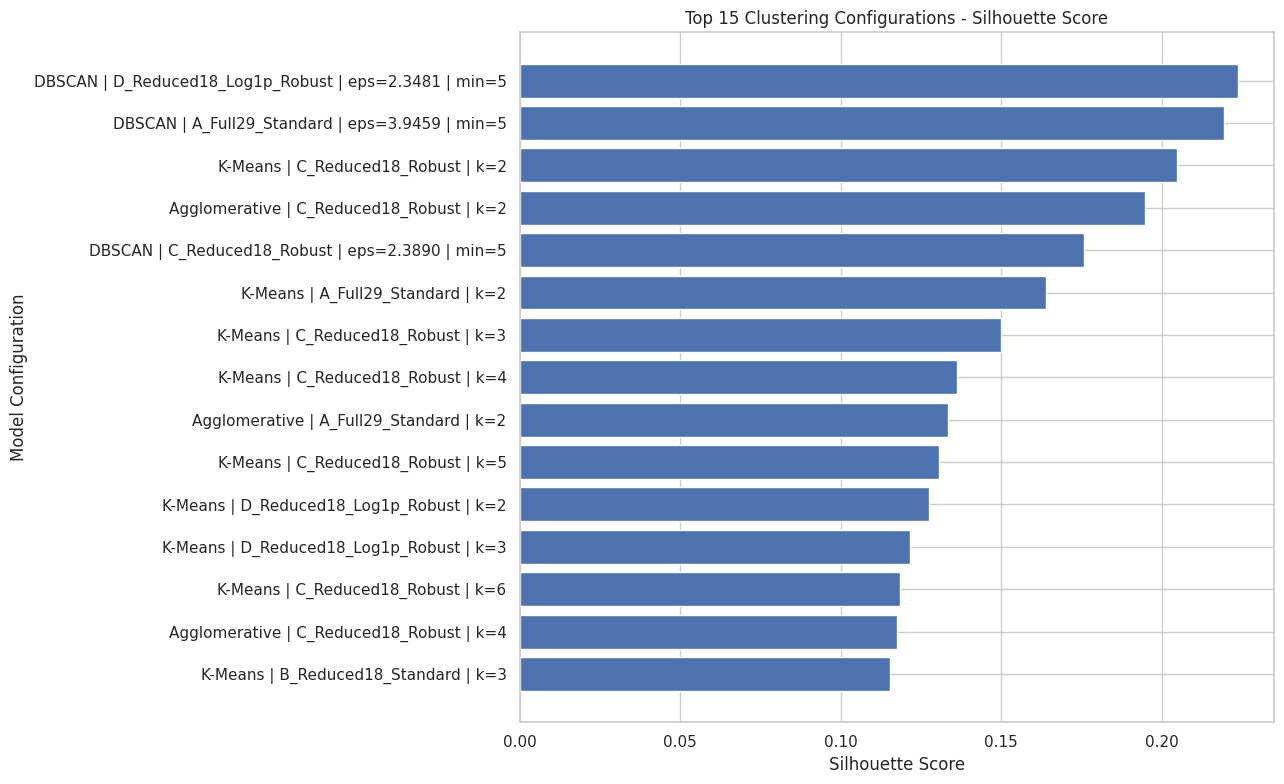

In [ ]:
# Visualizing top configurations by Silhouette Score (Silhoutte score)

silhouette_plot = (
    plot_results[
        plot_results["Silhouette Score"].notna()
    ]
    .nlargest(15, "Silhouette Score")
    .sort_values("Silhouette Score")
)

plt.figure(figsize=(13, 8))

plt.barh(
    silhouette_plot["Configuration"],
    silhouette_plot["Silhouette Score"]
)

plt.title("Top 15 Clustering Configurations - Silhouette Score")

plt.xlabel("Silhouette Score")

plt.ylabel("Model Configuration")

plt.tight_layout()
plt.show()

Hasil visualisasi menunjukkan bahwa konfigurasi DBSCAN D_Reduced18_Log1p_Robust menempati posisi pertama dengan Silhouette Score sekitar 0,224.

Selanjutnya, DBSCAN A_Full29_Standard berada pada posisi kedua, diikuti K-Means dan Agglomerative Clustering dengan representasi C_Reduced18_Robust.

Hasil ini memperlihatkan bahwa DBSCAN memiliki nilai Silhouette Score yang relatif lebih tinggi dibandingkan algoritma lainnya.

Namun, beberapa konfigurasi DBSCAN memiliki jumlah noise dan distribusi cluster yang tidak seimbang. Oleh karena itu, posisi tertinggi pada grafik belum tentu menunjukkan model yang paling sesuai untuk segmentasi pelanggan.

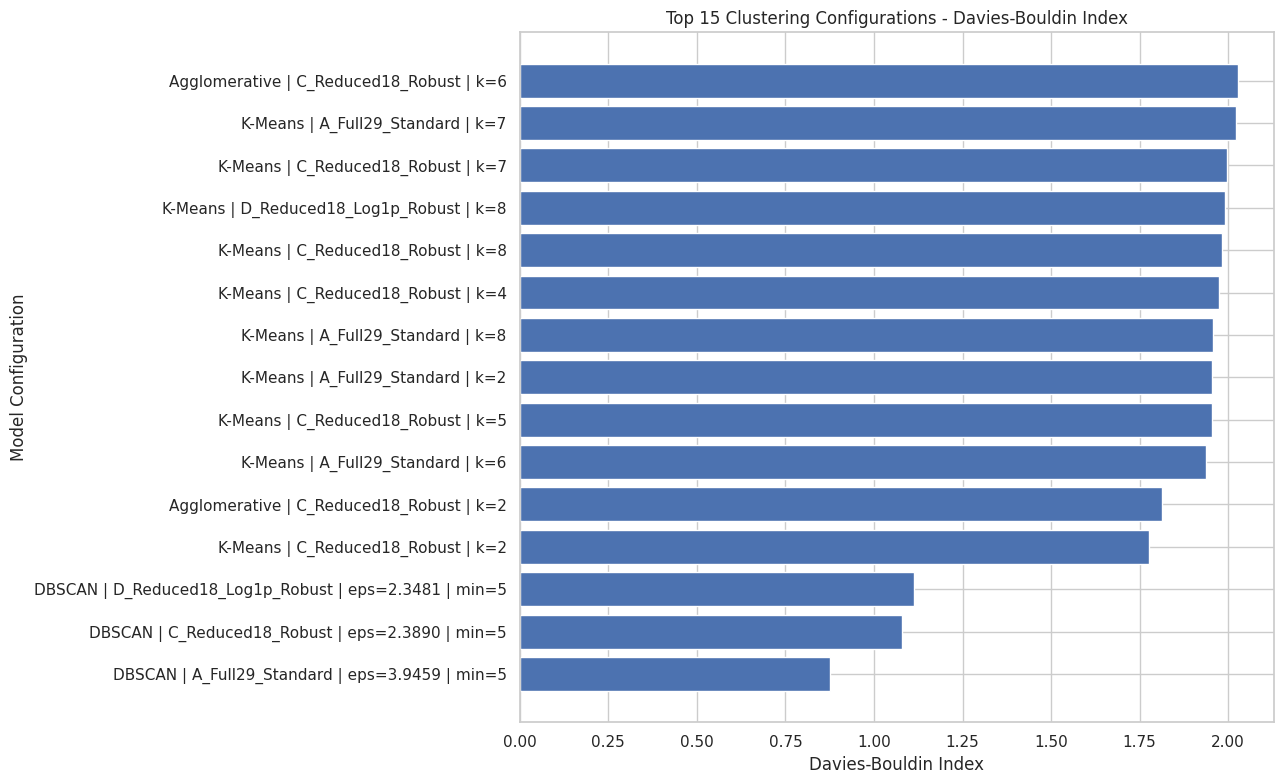

In [ ]:
# Visualizing top configurations by Davies-Bouldin Index

db_plot = (
    plot_results[
        plot_results["Davies-Bouldin Index"].notna()
    ]
    .nsmallest(15, "Davies-Bouldin Index")
    .sort_values("Davies-Bouldin Index", ascending=True)
)

plt.figure(figsize=(13, 8))

plt.barh(
    db_plot["Configuration"],
    db_plot["Davies-Bouldin Index"]
)

plt.title("Top 15 Clustering Configurations - Davies-Bouldin Index")

plt.xlabel("Davies-Bouldin Index")

plt.ylabel("Model Configuration")

plt.tight_layout()
plt.show()

Hasil visualisasi menunjukkan bahwa konfigurasi DBSCAN A_Full29_Standard menghasilkan Davies-Bouldin Index terendah, yaitu sekitar 0,876.

Nilai tersebut menunjukkan bahwa cluster yang terbentuk memiliki karakteristik kekompakan dan pemisahan yang relatif lebih baik berdasarkan metrik Davies-Bouldin.

Namun, hasil tersebut tetap perlu diperhatikan bersama persentase noise karena DBSCAN hanya menghitung metrik berdasarkan observasi yang tidak dikategorikan sebagai noise.

Dengan demikian, hasil Davies-Bouldin Index tidak dapat langsung dijadikan satu-satunya dasar pemilihan model.

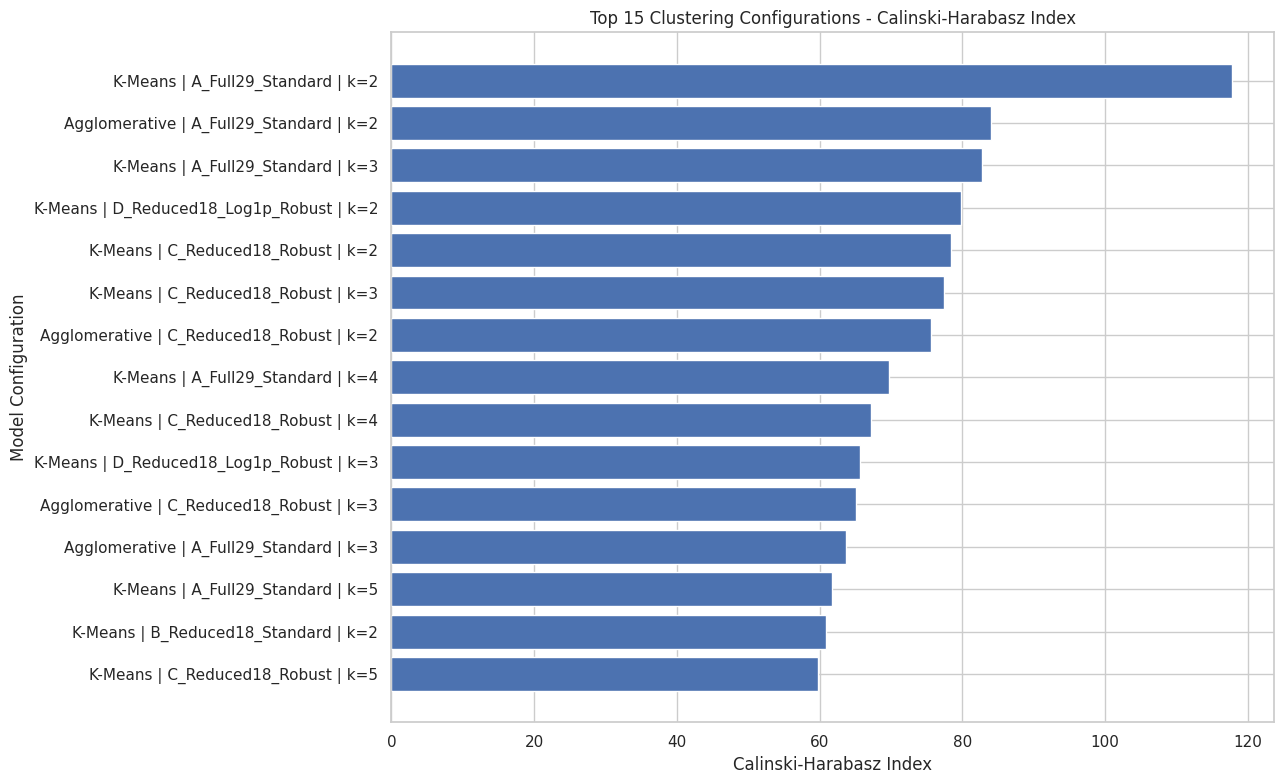

In [ ]:
# Visualizing top configurations by Calinski-Harabasz Index

ch_plot = (
    plot_results[
        plot_results["Calinski-Harabasz Index"].notna()
    ]
    .nlargest(15, "Calinski-Harabasz Index")
    .sort_values("Calinski-Harabasz Index")
)

plt.figure(figsize=(13, 8))

plt.barh(
    ch_plot["Configuration"],
    ch_plot["Calinski-Harabasz Index"]
)

plt.title("Top 15 Clustering Configurations - Calinski-Harabasz Index")

plt.xlabel("Calinski-Harabasz Index")

plt.ylabel("Model Configuration")

plt.tight_layout()
plt.show()

Hasil visualisasi menunjukkan bahwa K-Means dengan representasi A_Full29_Standard dan dua cluster menghasilkan Calinski-Harabasz Index tertinggi, yaitu sekitar 117,76.

Selanjutnya, Agglomerative Clustering dengan representasi yang sama menghasilkan nilai sekitar 83,98.

Hasil tersebut menunjukkan bahwa representasi full feature dengan StandardScaler memiliki rasio pemisahan antarcluster terhadap variasi dalam cluster yang relatif tinggi berdasarkan metrik ini.

Berbeda dengan hasil Silhouette Score dan Davies-Bouldin Index, Calinski-Harabasz Index justru lebih mengunggulkan konfigurasi K-Means dengan 29 fitur.

Perbedaan hasil tersebut menunjukkan bahwa setiap metrik memiliki sudut pandang evaluasi yang berbeda. Oleh karena itu, pemilihan model akhir perlu mempertimbangkan keseluruhan hasil evaluasi dan karakteristik distribusi cluster

## 3.18 Export Experimental Results

Menyimpan seluruh hasil eksperimen clustering sebagai
artefak penelitian untuk dokumentasi dan evaluasi lanjutan.

File yang dihasilkan mencakup:
1. K-Means experiment results.
2. Agglomerative experiment results.
3. DBSCAN experiment results.
4. Comprehensive model comparison.
5. Reduced feature matrix.
6. Cluster labels dari seluruh konfigurasi.

Penyimpanan dilakukan untuk menjaga reproducibility
dan memungkinkan hasil eksperimen diperiksa kembali
tanpa harus mengulang seluruh proses pemodelan.

Model akhir belum ditentukan pada tahap ini.
Seluruh kandidat akan dievaluasi lebih lanjut
pada tahap Model Evaluation and Comparison.

In [ ]:
# Creating output directory

output_dir = "stage3_outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)


# Exporting K-Means results
kmeans_results_df.to_csv(
    f"{output_dir}/stage3_kmeans_results.csv",
    index=False
)


# Exporting Agglomerative results
agglomerative_results_df.to_csv(
    f"{output_dir}/stage3_agglomerative_results.csv",
    index=False
)


# Exporting DBSCAN results
dbscan_results_df.to_csv(
    f"{output_dir}/stage3_dbscan_results.csv",
    index=False
)


# Exporting comprehensive comparison
all_model_results_sorted.to_csv(
    f"{output_dir}/stage3_comprehensive_model_comparison.csv",
    index=False
)


# Exporting reduced feature matrix
X_reduced.to_csv(
    f"{output_dir}/stage3_reduced_feature_matrix.csv",
    index=True
)


# Combining all cluster labels
all_experiment_labels = {
    **kmeans_labels,
    **agglomerative_labels,
    **dbscan_labels
}

experiment_labels_df = pd.DataFrame(
    all_experiment_labels,
    index=X_customer.index
)

experiment_labels_df.index.name = "AccountID"


# Exporting cluster labels
experiment_labels_df.to_csv(
    f"{output_dir}/stage3_experimental_cluster_labels.csv"
)


# Exporting representation summary
representation_summary_df.to_csv(
    f"{output_dir}/stage3_representation_summary.csv",
    index=False
)


print("All Stage 3 results successfully exported.")

print("\nExported files:")

for filename in os.listdir(output_dir):

    print("-", filename)

All Stage 3 results successfully exported.

Exported files:
- stage3_agglomerative_results.csv
- stage3_dbscan_results.csv
- stage3_comprehensive_model_comparison.csv
- stage3_kmeans_results.csv
- stage3_representation_summary.csv
- stage3_experimental_cluster_labels.csv
- stage3_reduced_feature_matrix.csv


Seluruh hasil eksperimen clustering berhasil disimpan dalam direktori stage3_outputs.

File yang dihasilkan mencakup hasil eksperimen K-Means, Agglomerative Clustering, DBSCAN, comprehensive model comparison, reduced feature matrix, cluster labels dari seluruh konfigurasi, serta representation summary.

Penyimpanan hasil ini bertujuan untuk menjaga dokumentasi eksperimen dan memudahkan proses evaluasi lanjutan tanpa harus mengulang seluruh proses clustering.

Dengan demikian, hasil Tahap 3 telah tersedia sebagai dasar untuk melakukan evaluasi stabilitas, perbandingan kualitas model, dan penentuan konfigurasi clustering yang paling sesuai pada Tahap 4.

Model akhir belum ditetapkan pada tahap ini karena masih diperlukan pemeriksaan stabilitas serta pertimbangan terhadap distribusi dan karakteristik masing-masing cluster.

# 4. MODEL EVALUATION & COMPARISON

Tahap ini mengevaluasi kembali kandidat model yang dihasilkan pada Tahap 3. Fokus evaluasi bukan mengulang seluruh eksperimen, melainkan memeriksa konsistensi data, membandingkan kandidat berdasarkan beberapa metrik, menganalisis distribusi cluster, dan menguji stabilitas hasil clustering.

Pengujian stabilitas dilakukan melalui dua pendekatan:
1. **Random-seed stability** untuk melihat konsistensi K-Means ketika `random_state` diubah.
2. **Sampling stability** untuk melihat apakah hasil pengelompokan tetap serupa ketika model dilatih menggunakan 80% sampel pelanggan yang dipilih secara acak.

Hasil Tahap 4 digunakan untuk memilih kandidat yang paling layak dibawa ke Tahap 5 — Cluster Profiling. Pemilihan ini tetap perlu dikonfirmasi melalui karakteristik dan kegunaan bisnis setiap cluster.

## 4.1 Input and Experimental Results Validation

Memastikan kembali bahwa feature matrix, hasil eksperimen, dan cluster labels dari Tahap 3 memiliki jumlah AccountID yang sama dan urutan identitas yang konsisten.

Pemeriksaan ini penting agar perbandingan label cluster tidak dilakukan pada pelanggan yang berbeda.

In [ ]:
# Validating Stage 3 objects before Stage 4

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

# These objects are generated in Stage 3 of this notebook.
required_objects = [
    "X_customer",
    "X_reduced",
    "data_spaces",
    "all_model_results",
    "experiment_labels_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Stage 3 objects are missing: " + str(missing_objects)
        + ". Run Stage 3 first, then continue to Stage 4."
    )

# Confirm that AccountID indexes are aligned.
if not X_customer.index.equals(X_reduced.index):
    raise ValueError("AccountID mismatch between original and reduced feature matrices.")

if not X_customer.index.equals(experiment_labels_df.index):
    raise ValueError("AccountID mismatch between feature matrix and cluster labels.")

for representation, data in data_spaces.items():
    if not data.index.equals(X_customer.index):
        raise ValueError(f"AccountID mismatch in {representation}.")

stage4_input_validation = pd.DataFrame([
    {
        "Item": "Original feature matrix",
        "Rows": X_customer.shape[0],
        "Columns": X_customer.shape[1],
        "Unique AccountID": X_customer.index.nunique(),
        "Missing Values": X_customer.isna().sum().sum()
    },
    {
        "Item": "Reduced feature matrix",
        "Rows": X_reduced.shape[0],
        "Columns": X_reduced.shape[1],
        "Unique AccountID": X_reduced.index.nunique(),
        "Missing Values": X_reduced.isna().sum().sum()
    },
    {
        "Item": "Saved cluster label matrix",
        "Rows": experiment_labels_df.shape[0],
        "Columns": experiment_labels_df.shape[1],
        "Unique AccountID": experiment_labels_df.index.nunique(),
        "Missing Values": experiment_labels_df.isna().sum().sum()
    }
])

display(stage4_input_validation)
print("Stage 4 input validation completed successfully.")

,Item,Rows,Columns,Unique AccountID,Missing Values
0,Original feature matrix,495,29,495,0
1,Reduced feature matrix,495,18,495,0
2,Saved cluster label matrix,495,116,495,0


Stage 4 input validation completed successfully.


Hasil validasi menunjukkan bahwa feature matrix awal memiliki 495 observasi dan 29 fitur, sedangkan reduced feature matrix memiliki 495 observasi dan 18 fitur. File cluster labels juga mencakup 495 AccountID dengan 116 kolom label konfigurasi eksperimen.

Seluruh AccountID bersifat unik dan tidak ditemukan missing values pada ketiga objek tersebut. Pemeriksaan kesesuaian index juga berhasil dilakukan, sehingga setiap baris fitur dapat dipasangkan dengan label cluster milik pelanggan yang tepat.

Dengan demikian, hasil Tahap 3 dapat digunakan untuk evaluasi lanjutan tanpa perlu mengulang proses preprocessing.

## 4.2 Candidate Model Selection and Metric Comparison

Kandidat dipilih dari hasil Tahap 3 dengan mempertimbangkan hasil terbaik dari setiap algoritma. Selain itu, satu konfigurasi K-Means dengan distribusi cluster yang lebih seimbang tetap dipertahankan sebagai alternatif.

Kandidat yang dibandingkan:
1. K-Means — `C_Reduced18_Robust`, 2 cluster.
2. K-Means — `A_Full29_Standard`, 2 cluster.
3. Agglomerative — `C_Reduced18_Robust`, 2 cluster.
4. DBSCAN — `D_Reduced18_Log1p_Robust`, `eps=2.348110`, `min_samples=5`.

Metrik yang dibaca kembali adalah Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Index. Untuk DBSCAN, metrik internal dihitung hanya pada observasi yang bukan noise.

In [ ]:
# Selecting the main candidates from Stage 3

candidate_specs = [
    {
        "Candidate": "K-Means | C_Reduced18_Robust | k=2",
        "Model": "K-Means",
        "Representation": "C_Reduced18_Robust",
        "Number of Clusters": 2,
        "Role": "Best Silhouette among full-coverage models"
    },
    {
        "Candidate": "K-Means | A_Full29_Standard | k=2",
        "Model": "K-Means",
        "Representation": "A_Full29_Standard",
        "Number of Clusters": 2,
        "Role": "Alternative with more balanced cluster sizes"
    },
    {
        "Candidate": "Agglomerative | C_Reduced18_Robust | k=2",
        "Model": "Agglomerative",
        "Representation": "C_Reduced18_Robust",
        "Number of Clusters": 2,
        "Role": "Hierarchical clustering comparison"
    },
    {
        "Candidate": "DBSCAN | D_Reduced18_Log1p_Robust | eps=2.348110 | min_samples=5",
        "Model": "DBSCAN",
        "Representation": "D_Reduced18_Log1p_Robust",
        "Number of Clusters": 2,
        "Role": "Highest Silhouette, with noise observations"
    }
]

stage4_candidate_rows = []

for spec in candidate_specs:
    subset = all_model_results[
        (all_model_results["Model"] == spec["Model"]) &
        (all_model_results["Representation"] == spec["Representation"])
    ].copy()

    if spec["Model"] == "DBSCAN":
        selected_row = subset[
            np.isclose(subset["Eps"], 2.348110, atol=1e-5) &
            (subset["Min Samples"] == 5)
        ].iloc[0]
    else:
        selected_row = subset[
            subset["Number of Clusters"] == 2
        ].iloc[0]

    row = selected_row.to_dict()
    row.update(spec)
    stage4_candidate_rows.append(row)

stage4_candidate_comparison = pd.DataFrame(stage4_candidate_rows)

display(stage4_candidate_comparison[[
    "Candidate",
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index",
    "Minimum Cluster Size",
    "Maximum Cluster Size",
    "Noise Percentage",
    "Coverage Percentage"
]])

,Candidate,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Minimum Cluster Size,Maximum Cluster Size,Noise Percentage,Coverage Percentage
0,K-Means | C_Reduced18_Robust | k=2,0.204832,1.777622,78.352540,83,412,0.00000,100.00000
1,K-Means | A_Full29_Standard | k=2,0.164061,1.955020,117.760726,222,273,0.00000,100.00000
2,Agglomerative | C_Reduced18_Robust | k=2,0.194771,1.813585,75.561890,84,411,0.00000,100.00000
3,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,0.223859,1.112930,7.730148,4,443,9.69697,90.30303


Hasil perbandingan menunjukkan bahwa DBSCAN pada `D_Reduced18_Log1p_Robust` memiliki Silhouette Score tertinggi, yaitu **0,2239**. Namun, nilai tersebut dihitung hanya dari pelanggan yang tidak dikategorikan sebagai noise.

Di antara model yang mengelompokkan seluruh 495 pelanggan, K-Means dengan `C_Reduced18_Robust` memperoleh Silhouette Score tertinggi, yaitu **0,2048**, diikuti Agglomerative dengan nilai **0,1948**. K-Means pada `A_Full29_Standard` menghasilkan Silhouette Score **0,1641**.

Untuk Davies-Bouldin Index, DBSCAN menghasilkan nilai terendah sebesar **1,1129**. Akan tetapi, hasil ini juga hanya memperhitungkan observasi non-noise, sehingga tidak sepenuhnya sebanding dengan model yang mengelompokkan seluruh pelanggan.

Sementara itu, Calinski-Harabasz Index tertinggi diperoleh K-Means `A_Full29_Standard`, yaitu **117,76**. Perbedaan pemenang pada setiap metrik menunjukkan bahwa tidak ada satu metrik yang cukup untuk menentukan model terbaik. Ukuran cluster, coverage, dan stabilitas juga perlu diperhatikan.

## 4.3 Cluster Distribution Analysis

Menganalisis jumlah dan persentase AccountID pada setiap cluster kandidat. Analisis ini digunakan untuk mengetahui apakah hasil segmentasi membentuk kelompok dengan ukuran yang masih layak dianalisis.

Pada DBSCAN, label `-1` diperlakukan sebagai noise, yaitu observasi yang tidak dimasukkan ke cluster mana pun.

In [ ]:
# Mapping each candidate to its saved cluster-label column

candidate_label_columns = {
    "K-Means | C_Reduced18_Robust | k=2":
        "C_Reduced18_Robust_KMeans_k2",
    "K-Means | A_Full29_Standard | k=2":
        "A_Full29_Standard_KMeans_k2",
    "Agglomerative | C_Reduced18_Robust | k=2":
        "C_Reduced18_Robust_Agglomerative_k2"
}

dbscan_label_column = next(
    column for column in experiment_labels_df.columns
    if column.startswith(
        "D_Reduced18_Log1p_Robust_DBSCAN_eps2.34811_min5"
    )
)

candidate_label_columns[
    "DBSCAN | D_Reduced18_Log1p_Robust | eps=2.348110 | min_samples=5"
] = dbscan_label_column

stage4_distribution_rows = []

for candidate, label_column in candidate_label_columns.items():
    labels = experiment_labels_df[label_column]
    cluster_counts = labels.value_counts().sort_index()

    for cluster_label, count in cluster_counts.items():
        cluster_name = "Noise" if cluster_label == -1 else f"Cluster {cluster_label}"

        stage4_distribution_rows.append({
            "Candidate": candidate,
            "Cluster": cluster_name,
            "Customer Count": int(count),
            "Percentage of All Customers": count / len(labels) * 100,
            "Coverage Percentage": (labels != -1).mean() * 100
        })

stage4_cluster_distribution = pd.DataFrame(stage4_distribution_rows)

display(stage4_cluster_distribution)

,Candidate,Cluster,Customer Count,Percentage of All Customers,Coverage Percentage
0,K-Means | C_Reduced18_Robust | k=2,Cluster 0,83,16.767677,100.00000
1,K-Means | C_Reduced18_Robust | k=2,Cluster 1,412,83.232323,100.00000
2,K-Means | A_Full29_Standard | k=2,Cluster 0,273,55.151515,100.00000
3,K-Means | A_Full29_Standard | k=2,Cluster 1,222,44.848485,100.00000
4,Agglomerative | C_Reduced18_Robust | k=2,Cluster 0,411,83.030303,100.00000
5,Agglomerative | C_Reduced18_Robust | k=2,Cluster 1,84,16.969697,100.00000
6,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,Noise,48,9.696970,90.30303
7,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,Cluster 0,443,89.494949,90.30303
8,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,Cluster 1,4,0.808081,90.30303


Hasil distribusi menunjukkan bahwa K-Means `C_Reduced18_Robust` membagi 495 pelanggan menjadi 83 pelanggan (16,77%) pada Cluster 0 dan 412 pelanggan (83,23%) pada Cluster 1. Agglomerative dengan representasi yang sama menghasilkan pembagian yang hampir serupa, yaitu 84 dan 411 pelanggan.

Sebaliknya, K-Means `A_Full29_Standard` menghasilkan pembagian yang lebih seimbang, yaitu 273 pelanggan (55,15%) dan 222 pelanggan (44,85%). Ini menjadi keunggulan penting apabila tujuan segmentasi adalah memperoleh dua kelompok dengan ukuran yang relatif setara.

DBSCAN menghasilkan 443 pelanggan (89,49%) pada Cluster 0, hanya 4 pelanggan (0,81%) pada Cluster 1, serta 48 pelanggan (9,70%) sebagai noise. Dengan demikian, cluster kedua DBSCAN sangat kecil dan sebagian pelanggan tidak memperoleh label cluster.

Hasil ini memperlihatkan bahwa nilai evaluasi yang tinggi belum tentu menghasilkan segmentasi yang praktis. Model juga harus membentuk kelompok pelanggan dengan ukuran yang cukup untuk dianalisis pada Tahap 5.

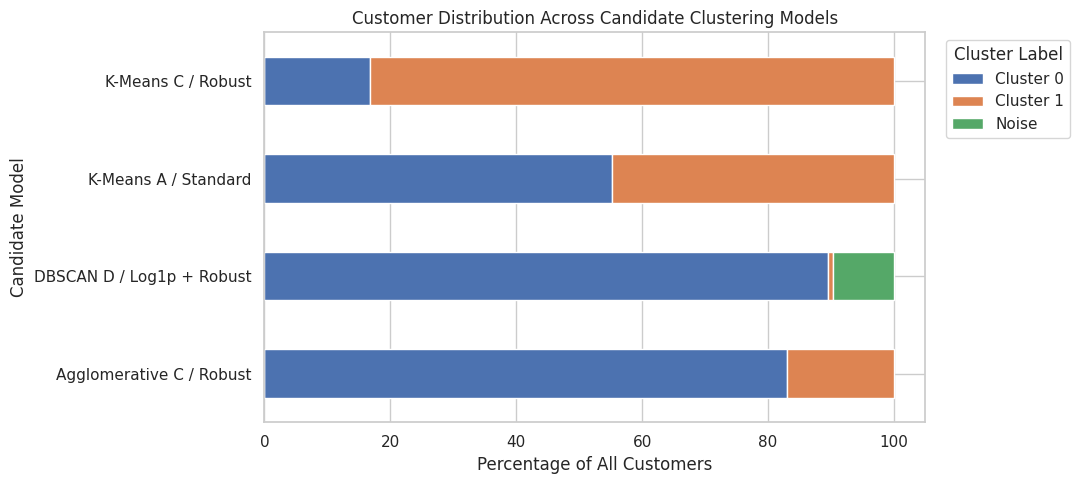

In [ ]:
# Visualizing cluster proportions for each candidate

plot_distribution = stage4_cluster_distribution.copy()
plot_distribution["Candidate Short"] = plot_distribution["Candidate"].map({
    "K-Means | C_Reduced18_Robust | k=2": "K-Means C / Robust",
    "K-Means | A_Full29_Standard | k=2": "K-Means A / Standard",
    "Agglomerative | C_Reduced18_Robust | k=2": "Agglomerative C / Robust",
    "DBSCAN | D_Reduced18_Log1p_Robust | eps=2.348110 | min_samples=5": "DBSCAN D / Log1p + Robust"
})

pivot_distribution = plot_distribution.pivot(
    index="Candidate Short",
    columns="Cluster",
    values="Percentage of All Customers"
).fillna(0)

pivot_distribution.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 5)
)

plt.title("Customer Distribution Across Candidate Clustering Models")
plt.xlabel("Percentage of All Customers")
plt.ylabel("Candidate Model")
plt.legend(title="Cluster Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Grafik memperjelas perbedaan proporsi anggota cluster antar kandidat. K-Means `A_Full29_Standard` terlihat paling seimbang, sedangkan K-Means `C_Reduced18_Robust` dan Agglomerative `C_Reduced18_Robust` menghasilkan satu cluster besar dan satu cluster yang lebih kecil.

Pada DBSCAN, bagian noise dan cluster yang hanya berisi empat pelanggan terlihat sebagai bagian kecil dari keseluruhan data. Kondisi ini perlu diperhatikan karena segmen yang sangat kecil belum tentu cukup kuat untuk dijadikan dasar rekomendasi bisnis.

Visualisasi distribusi ini melengkapi metrik internal dan membantu melihat apakah hasil clustering dapat digunakan untuk membentuk segmen pelanggan yang mudah dianalisis.

## 4.4 Reproducibility Check of Candidate Models

Memastikan bahwa konfigurasi kandidat dapat dijalankan kembali dengan parameter yang sama dan menghasilkan cluster labels yang sesuai dengan hasil tersimpan pada Tahap 3.

Perbandingan menggunakan **Adjusted Rand Index (ARI)**. Nilai ARI sebesar 1 menunjukkan bahwa dua hasil pengelompokan sama, meskipun nomor label cluster dapat tertukar.

In [ ]:
# Re-fitting the four candidates with the same Stage 3 parameters

refit_specs = [
    (
        "K-Means | C_Reduced18_Robust | k=2",
        "C_Reduced18_Robust",
        KMeans(n_clusters=2, random_state=42, n_init=30, max_iter=500)
    ),
    (
        "K-Means | A_Full29_Standard | k=2",
        "A_Full29_Standard",
        KMeans(n_clusters=2, random_state=42, n_init=30, max_iter=500)
    ),
    (
        "Agglomerative | C_Reduced18_Robust | k=2",
        "C_Reduced18_Robust",
        AgglomerativeClustering(n_clusters=2, linkage="ward")
    ),
    (
        "DBSCAN | D_Reduced18_Log1p_Robust | eps=2.348110 | min_samples=5",
        "D_Reduced18_Log1p_Robust",
        DBSCAN(eps=2.348110, min_samples=5)
    )
]

stage4_reproducibility_rows = []

for candidate, representation, model in refit_specs:
    refitted_labels = model.fit_predict(data_spaces[representation])
    saved_labels = experiment_labels_df[
        candidate_label_columns[candidate]
    ].to_numpy()

    ari = adjusted_rand_score(saved_labels, refitted_labels)

    stage4_reproducibility_rows.append({
        "Candidate": candidate,
        "Observations": len(refitted_labels),
        "Saved Label Groups": len(set(saved_labels)),
        "Refit Label Groups": len(set(refitted_labels)),
        "ARI Saved vs Refit": ari,
        "Result": "Match" if ari >= 0.999999 else "Check"
    })

stage4_reproducibility_check = pd.DataFrame(
    stage4_reproducibility_rows
)

display(stage4_reproducibility_check)

,Candidate,Observations,Saved Label Groups,Refit Label Groups,ARI Saved vs Refit,Result
0,K-Means | C_Reduced18_Robust | k=2,495,2,2,1.0,Match
1,K-Means | A_Full29_Standard | k=2,495,2,2,1.0,Match
2,Agglomerative | C_Reduced18_Robust | k=2,495,2,2,1.0,Match
3,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,495,3,3,1.0,Match


Seluruh kandidat menghasilkan ARI sebesar **1,0000** ketika dijalankan kembali dengan konfigurasi yang sama. Artinya, label cluster yang dihasilkan ulang sesuai dengan label yang sudah tersimpan dari Tahap 3.

Hasil ini menunjukkan bahwa proses eksperimen dapat direproduksi dengan parameter dan data yang sama. Namun, pemeriksaan ini belum membuktikan bahwa model stabil terhadap perubahan data. Untuk mengetahui hal tersebut, diperlukan pengujian random seed dan perubahan sampel pada bagian berikutnya.

## 4.5 K-Means Random-Seed Stability

Menguji kestabilan dua kandidat K-Means ketika nilai `random_state` diubah dari 0 hingga 29. Setiap percobaan tetap menggunakan `n_init=30` dan jumlah cluster sebanyak dua.

Label hasil dari setiap percobaan dibandingkan secara berpasangan menggunakan ARI. Dengan 30 percobaan, terdapat 435 perbandingan pasangan hasil.

In [ ]:
# Testing K-Means sensitivity to random_state

stage4_seed_specs = [
    ("K-Means | C_Reduced18_Robust | k=2", "C_Reduced18_Robust"),
    ("K-Means | A_Full29_Standard | k=2", "A_Full29_Standard")
]

stage4_seed_rows = []
stage4_seed_ari_distributions = {}

for candidate, representation in stage4_seed_specs:
    X = data_spaces[representation]
    repeated_labels = []

    for seed_value in range(30):
        model = KMeans(
            n_clusters=2,
            random_state=seed_value,
            n_init=30,
            max_iter=500
        )
        repeated_labels.append(model.fit_predict(X))

    pairwise_ari = [
        adjusted_rand_score(repeated_labels[i], repeated_labels[j])
        for i in range(30)
        for j in range(i + 1, 30)
    ]

    stage4_seed_ari_distributions[candidate] = pairwise_ari

    stage4_seed_rows.append({
        "Candidate": candidate,
        "Runs": 30,
        "Pairwise Comparisons": len(pairwise_ari),
        "Mean ARI": np.mean(pairwise_ari),
        "Std ARI": np.std(pairwise_ari),
        "Minimum ARI": np.min(pairwise_ari),
        "Maximum ARI": np.max(pairwise_ari)
    })

stage4_random_seed_stability = pd.DataFrame(stage4_seed_rows)
display(stage4_random_seed_stability)

,Candidate,Runs,Pairwise Comparisons,Mean ARI,Std ARI,Minimum ARI,Maximum ARI
0,K-Means | C_Reduced18_Robust | k=2,30,435,1.00000,0.000000,1.00000,1.0
1,K-Means | A_Full29_Standard | k=2,30,435,0.99508,0.005186,0.98387,1.0


K-Means dengan `C_Reduced18_Robust` menghasilkan rata-rata ARI sebesar **1,0000**, dengan nilai minimum dan maksimum yang juga 1,0000. Artinya, hasil pengelompokan tidak berubah pada 30 percobaan dengan random seed yang berbeda.

K-Means dengan `A_Full29_Standard` menghasilkan rata-rata ARI sebesar **0,9951**, dengan nilai minimum **0,9839**. Hasil ini juga menunjukkan konsistensi yang sangat tinggi, meskipun terdapat sedikit perbedaan label pada sebagian percobaan.

Berdasarkan pengujian random seed, kedua kandidat K-Means dapat dikatakan stabil. Kandidat `C_Reduced18_Robust` menunjukkan hasil yang paling konsisten pada pengujian ini.

## 4.6 Sampling Stability Analysis

Menguji kestabilan model ketika hanya 80% pelanggan dipilih secara acak untuk proses fitting. Proses ini diulang sebanyak 30 kali untuk setiap kandidat.

Untuk K-Means, model yang dilatih pada 80% sampel digunakan untuk memprediksi label seluruh 495 pelanggan. Untuk Agglomerative dan DBSCAN, yang tidak memiliki fungsi prediksi untuk observasi baru, ARI dihitung pada AccountID yang muncul pada kedua sampel yang dibandingkan.

Setiap kandidat memiliki 435 perbandingan berpasangan. Pada DBSCAN, label noise (`-1`) tetap dihitung sebagai kategori tersendiri dalam ARI utama. Coverage dan jumlah cluster non-noise juga dicatat.

In [ ]:
# Repeated 80% subsampling to evaluate cluster stability

stage4_sampling_specs = [
    (
        "K-Means | C_Reduced18_Robust | k=2",
        "K-Means",
        "C_Reduced18_Robust",
        {"n_clusters": 2, "n_init": 30, "max_iter": 500}
    ),
    (
        "K-Means | A_Full29_Standard | k=2",
        "K-Means",
        "A_Full29_Standard",
        {"n_clusters": 2, "n_init": 30, "max_iter": 500}
    ),
    (
        "Agglomerative | C_Reduced18_Robust | k=2",
        "Agglomerative",
        "C_Reduced18_Robust",
        {"n_clusters": 2, "linkage": "ward"}
    ),
    (
        "DBSCAN | D_Reduced18_Log1p_Robust | eps=2.348110 | min_samples=5",
        "DBSCAN",
        "D_Reduced18_Log1p_Robust",
        {"eps": 2.348110, "min_samples": 5}
    )
]

sample_fraction = 0.80
number_of_runs = 30
number_of_customers = len(X_customer)
sample_size = int(round(number_of_customers * sample_fraction))
rng = np.random.RandomState(2026)

stage4_sampling_rows = []
stage4_sampling_ari_distributions = {}

for candidate, model_type, representation, parameters in stage4_sampling_specs:
    X = data_spaces[representation].to_numpy()
    sampled_indices = []
    sampled_labels = []
    coverage_values = []
    noise_values = []
    cluster_values = []

    for run in range(number_of_runs):
        selected_indices = np.sort(
            rng.choice(number_of_customers, size=sample_size, replace=False)
        )
        X_sample = X[selected_indices]

        if model_type == "K-Means":
            model = KMeans(
                n_clusters=2,
                random_state=run,
                n_init=parameters["n_init"],
                max_iter=parameters["max_iter"]
            )
            model.fit(X_sample)
            # Assign all original customers to the centroids fitted on the 80% sample.
            labels = model.predict(X)

        elif model_type == "Agglomerative":
            model = AgglomerativeClustering(**parameters)
            labels = model.fit_predict(X_sample)

        else:
            model = DBSCAN(**parameters)
            labels = model.fit_predict(X_sample)

        sampled_indices.append(selected_indices)
        sampled_labels.append(labels)

        if model_type == "DBSCAN":
            non_noise = labels != -1
            coverage_values.append(non_noise.mean() * 100)
            noise_values.append((~non_noise).mean() * 100)
            cluster_values.append(len(set(labels) - {-1}))
        else:
            coverage_values.append(100.0)
            noise_values.append(0.0)
            cluster_values.append(len(set(labels)))

    pairwise_ari = []
    non_noise_ari = []
    shared_customer_counts = []

    for i in range(number_of_runs):
        for j in range(i + 1, number_of_runs):
            if model_type == "K-Means":
                labels_i = sampled_labels[i]
                labels_j = sampled_labels[j]
                shared_indices = np.arange(number_of_customers)

            else:
                shared_indices = np.intersect1d(
                    sampled_indices[i], sampled_indices[j]
                )
                map_i = {
                    original_index: local_index
                    for local_index, original_index in enumerate(sampled_indices[i])
                }
                map_j = {
                    original_index: local_index
                    for local_index, original_index in enumerate(sampled_indices[j])
                }
                labels_i = np.array([
                    sampled_labels[i][map_i[index]] for index in shared_indices
                ])
                labels_j = np.array([
                    sampled_labels[j][map_j[index]] for index in shared_indices
                ])

            shared_customer_counts.append(len(shared_indices))
            pairwise_ari.append(
                adjusted_rand_score(labels_i, labels_j)
            )

            if model_type == "DBSCAN":
                valid_non_noise = (labels_i != -1) & (labels_j != -1)
                if (
                    valid_non_noise.sum() > 2 and
                    len(np.unique(labels_i[valid_non_noise])) > 1 and
                    len(np.unique(labels_j[valid_non_noise])) > 1
                ):
                    non_noise_ari.append(
                        adjusted_rand_score(
                            labels_i[valid_non_noise],
                            labels_j[valid_non_noise]
                        )
                    )

    stage4_sampling_ari_distributions[candidate] = pairwise_ari

    stage4_sampling_rows.append({
        "Candidate": candidate,
        "Model": model_type,
        "Subsample Fraction": sample_fraction,
        "Runs": number_of_runs,
        "Pairwise Comparisons": len(pairwise_ari),
        "Average Shared Customers": np.mean(shared_customer_counts),
        "Mean ARI": np.mean(pairwise_ari),
        "Std ARI": np.std(pairwise_ari),
        "Minimum ARI": np.min(pairwise_ari),
        "Maximum ARI": np.max(pairwise_ari),
        "Average Coverage Percentage": np.mean(coverage_values),
        "Average Noise Percentage": np.mean(noise_values),
        "Average Non-noise Clusters": np.mean(cluster_values),
        "Non-noise ARI Comparisons": len(non_noise_ari),
        "Mean Non-noise ARI": np.mean(non_noise_ari) if non_noise_ari else np.nan
    })

stage4_sampling_stability = pd.DataFrame(stage4_sampling_rows)
display(stage4_sampling_stability)

,Candidate,Model,Subsample Fraction,Runs,Pairwise Comparisons,Average Shared Customers,Mean ARI,Std ARI,Minimum ARI,Maximum ARI,Average Coverage Percentage,Average Noise Percentage,Average Non-noise Clusters,Non-noise ARI Comparisons,Mean Non-noise ARI
0,K-Means | C_Reduced18_Robust | k=2,K-Means,0.8,30,435,495.000000,0.994959,0.005430,0.979866,1.000000,100.000000,0.000000,2.0,0,NaN
1,K-Means | A_Full29_Standard | k=2,K-Means,0.8,30,435,495.000000,0.892169,0.067310,0.662154,1.000000,100.000000,0.000000,2.0,0,NaN
2,Agglomerative | C_Reduced18_Robust | k=2,Agglomerative,0.8,30,435,316.535632,0.818501,0.187168,0.098615,0.984179,100.000000,0.000000,2.0,0,NaN
3,DBSCAN | D_Reduced18_Log1p_Robust | eps=2.3481...,DBSCAN,0.8,30,435,316.721839,0.878827,0.041830,0.746593,0.995722,88.400673,11.599327,1.2,15,0.930287


Hasil pengujian sampling menunjukkan perbedaan kestabilan antar kandidat.

K-Means `C_Reduced18_Robust` menghasilkan rata-rata ARI sebesar **0,9950**, dengan nilai minimum **0,9799**. Hasil tersebut menunjukkan bahwa pembagian pelanggan tetap sangat mirip meskipun model dilatih menggunakan 80% sampel yang berbeda.

K-Means `A_Full29_Standard` menghasilkan rata-rata ARI **0,8922**. Hasilnya masih cukup konsisten, tetapi perubahan sampel memberikan pengaruh yang lebih besar dibandingkan konfigurasi C.

Agglomerative menghasilkan rata-rata ARI **0,8185** dan variasi hasil yang lebih besar. Artinya, struktur cluster lebih mudah berubah ketika sebagian data tidak disertakan pada proses fitting.

DBSCAN menghasilkan rata-rata ARI **0,8788** jika noise dihitung sebagai satu kategori. Namun, rata-rata coverage pada pengujian ulang hanya **88,40%**, persentase noise sekitar **11,60%**, dan rata-rata jumlah cluster non-noise hanya **1,2**. Dari 435 perbandingan, hanya 15 pasangan hasil yang sama-sama membentuk lebih dari satu cluster non-noise. Pada 15 pasangan tersebut, rata-rata ARI non-noise adalah **0,9303**.

Dengan demikian, DBSCAN dapat menghasilkan pemisahan yang cukup konsisten ketika dua cluster non-noise sama-sama terbentuk, tetapi pembentukan dua cluster tersebut tidak terjadi secara konsisten pada berbagai sampel. Hal ini memperkuat alasan untuk tidak menjadikan DBSCAN sebagai model utama segmentasi pada tahap ini.

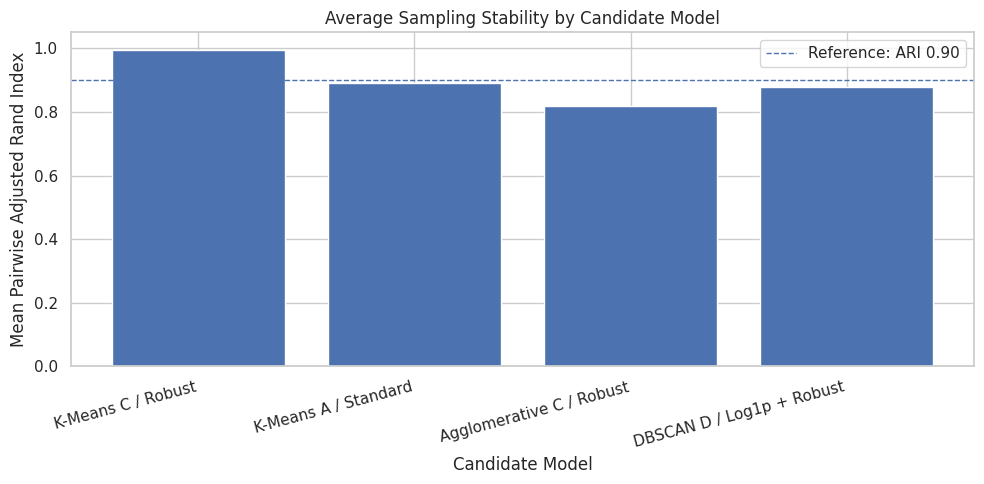

In [ ]:
# Visualizing sampling stability across candidate models

sampling_plot = stage4_sampling_stability.copy()
sampling_plot["Candidate Short"] = [
    "K-Means C / Robust",
    "K-Means A / Standard",
    "Agglomerative C / Robust",
    "DBSCAN D / Log1p + Robust"
]

plt.figure(figsize=(10, 5))
plt.bar(
    sampling_plot["Candidate Short"],
    sampling_plot["Mean ARI"]
)
plt.axhline(0.90, linestyle="--", linewidth=1, label="Reference: ARI 0.90")
plt.ylim(0, 1.05)
plt.title("Average Sampling Stability by Candidate Model")
plt.ylabel("Mean Pairwise Adjusted Rand Index")
plt.xlabel("Candidate Model")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

Grafik menunjukkan bahwa K-Means `C_Reduced18_Robust` memiliki rata-rata ARI paling tinggi dan paling dekat dengan nilai 1. Hal ini memperlihatkan bahwa hasil segmentasinya paling konsisten ketika sampel pelanggan berubah.

K-Means `A_Full29_Standard` berada di bawah konfigurasi C, sedangkan Agglomerative dan DBSCAN menunjukkan nilai rata-rata yang lebih rendah. Garis putus-putus pada ARI 0,90 hanya digunakan sebagai acuan visual untuk memudahkan pembacaan, bukan sebagai batas universal bahwa model di atas atau di bawahnya otomatis baik atau buruk.

Berdasarkan pengujian ini, K-Means `C_Reduced18_Robust` merupakan kandidat yang paling stabil terhadap perubahan sampel.

## 4.7 Final Model Selection

Menentukan kandidat yang akan dibawa ke Tahap 5 berdasarkan gabungan hasil evaluasi internal, distribusi cluster, coverage, dan stabilitas.

Pemilihan pada tahap ini bersifat **model terpilih untuk proses profiling**. Makna dan kegunaan setiap cluster tetap harus diperiksa pada Tahap 5 sebelum segmentasi dinyatakan layak digunakan untuk rekomendasi bisnis.

In [ ]:
# Preparing the selected candidate summary

selected_candidate = "K-Means | C_Reduced18_Robust | k=2"
selected_metric_row = stage4_candidate_comparison[
    stage4_candidate_comparison["Candidate"] == selected_candidate
].iloc[0]
selected_stability_row = stage4_sampling_stability[
    stage4_sampling_stability["Candidate"] == selected_candidate
].iloc[0]
selected_seed_row = stage4_random_seed_stability[
    stage4_random_seed_stability["Candidate"] == selected_candidate
].iloc[0]

stage4_selected_model_summary = pd.DataFrame([{
    "Selected Candidate": selected_candidate,
    "Silhouette Score": selected_metric_row["Silhouette Score"],
    "Davies-Bouldin Index": selected_metric_row["Davies-Bouldin Index"],
    "Calinski-Harabasz Index": selected_metric_row["Calinski-Harabasz Index"],
    "Coverage Percentage": selected_metric_row["Coverage Percentage"],
    "Minimum Cluster Size": selected_metric_row["Minimum Cluster Size"],
    "Maximum Cluster Size": selected_metric_row["Maximum Cluster Size"],
    "Random-Seed Mean ARI": selected_seed_row["Mean ARI"],
    "Sampling Mean ARI": selected_stability_row["Mean ARI"]
}])

display(stage4_selected_model_summary)

,Selected Candidate,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Coverage Percentage,Minimum Cluster Size,Maximum Cluster Size,Random-Seed Mean ARI,Sampling Mean ARI
0,K-Means | C_Reduced18_Robust | k=2,0.204832,1.777622,78.35254,100.0,83,412,1.0,0.994959


Berdasarkan keseluruhan evaluasi, kandidat yang dipilih untuk proses Cluster Profiling pada Tahap 5 adalah **K-Means dengan representasi `C_Reduced18_Robust` dan 2 cluster**.

Pemilihan ini didasarkan pada beberapa pertimbangan. Pertama, konfigurasi tersebut memiliki Silhouette Score tertinggi di antara model yang mengelompokkan seluruh 495 pelanggan, yaitu **0,2048**. Kedua, seluruh pelanggan memperoleh label cluster tanpa noise. Ketiga, hasilnya sangat stabil, dengan rata-rata ARI **1,0000** pada pengujian random seed dan **0,9950** pada pengujian sampling.

Meskipun demikian, distribusi cluster belum seimbang: 83 pelanggan berada pada satu cluster dan 412 pelanggan berada pada cluster lainnya. Kondisi ini tidak otomatis membuat model tidak layak, tetapi perlu diperiksa pada Tahap 5 untuk memastikan bahwa kelompok yang lebih kecil memang memiliki pola perilaku yang berbeda dan bukan sekadar kelompok kecil akibat karakteristik data tertentu.

K-Means `A_Full29_Standard` tetap dicatat sebagai alternatif karena menghasilkan pembagian yang lebih seimbang dan Calinski-Harabasz Index tertinggi. DBSCAN tetap bermanfaat sebagai pembanding untuk mendeteksi observasi yang tidak mengikuti pola umum, tetapi belum dipilih sebagai model segmentasi utama karena jumlah noise dan pembentukan cluster kecilnya kurang konsisten.

Dengan demikian, keputusan Tahap 4 adalah menggunakan K-Means `C_Reduced18_Robust` sebagai kandidat utama untuk profiling, dengan K-Means `A_Full29_Standard` sebagai alternatif pembanding.

## 4.8 Export Stage 4 Evaluation Results

Menyimpan hasil evaluasi Tahap 4 agar dapat digunakan kembali pada tahap berikutnya dan menjadi dokumentasi proses pemilihan model.

File yang disimpan meliputi input validation, candidate comparison, cluster distribution, reproducibility check, random-seed stability, sampling stability, dan selected model summary.

In [ ]:
# Exporting Stage 4 evaluation artifacts

stage4_output_dir = "stage4_outputs"
os.makedirs(stage4_output_dir, exist_ok=True)

stage4_input_validation.to_csv(
    f"{stage4_output_dir}/stage4_input_validation.csv", index=False
)
stage4_candidate_comparison.to_csv(
    f"{stage4_output_dir}/stage4_candidate_comparison.csv", index=False
)
stage4_cluster_distribution.to_csv(
    f"{stage4_output_dir}/stage4_cluster_distribution.csv", index=False
)
stage4_reproducibility_check.to_csv(
    f"{stage4_output_dir}/stage4_reproducibility_check.csv", index=False
)
stage4_random_seed_stability.to_csv(
    f"{stage4_output_dir}/stage4_random_seed_stability.csv", index=False
)
stage4_sampling_stability.to_csv(
    f"{stage4_output_dir}/stage4_sampling_stability.csv", index=False
)
stage4_selected_model_summary.to_csv(
    f"{stage4_output_dir}/stage4_selected_model_summary.csv", index=False
)

print("Stage 4 evaluation results successfully exported.")
print("\nExported files:")
for filename in sorted(os.listdir(stage4_output_dir)):
    print("-", filename)

Stage 4 evaluation results successfully exported.

Exported files:
- stage4_candidate_comparison.csv
- stage4_cluster_distribution.csv
- stage4_input_validation.csv
- stage4_random_seed_stability.csv
- stage4_reproducibility_check.csv
- stage4_sampling_stability.csv
- stage4_selected_model_summary.csv


Seluruh hasil evaluasi Tahap 4 berhasil disimpan ke dalam folder `stage4_outputs`. File-file tersebut berisi perbandingan kandidat, ukuran setiap cluster, hasil pemeriksaan reproduksibilitas, serta hasil pengujian stabilitas.

Artefak ini dapat digunakan kembali pada Tahap 5 tanpa harus mengulang seluruh evaluasi. Untuk proses berikutnya, label cluster dari kandidat K-Means `C_Reduced18_Robust` perlu digabungkan dengan customer-level audit data agar setiap cluster dapat dijelaskan berdasarkan karakteristik transaksi dan perilaku pelanggan.

# 5. CLUSTER PROFILING

Tahap ini bertujuan memahami karakteristik pelanggan yang terbentuk dari model terpilih pada Tahap 4. Profiling dilakukan pada nilai fitur asli (sebelum scaling) agar hasilnya mudah dibaca dan dapat diterjemahkan menjadi insight bisnis.

Model utama yang digunakan adalah **K-Means dengan representasi `C_Reduced18_Robust` dan 2 cluster**. Label cluster diambil dari hasil eksperimen Tahap 3, bukan dibuat ulang dengan urutan yang berbeda.

Analisis mencakup distribusi pelanggan, perbandingan fitur, pemeriksaan perbedaan karakteristik, visualisasi PCA, serta pola kanal dan jenis transaksi. Cluster 0 dan Cluster 1 merupakan label teknis dari algoritma; nama segmen baru diberikan setelah karakteristiknya diperiksa.

## 5.1 Loading Data and Cluster Label Validation

Memuat kembali customer-level feature matrix, customer-level audit dataset, cleaned transaction dataset, reduced feature matrix, dan label clustering yang dihasilkan pada Tahap 3.

Seluruh penggabungan dilakukan menggunakan `AccountID`, bukan berdasarkan posisi baris. Pemeriksaan ini menjaga agar setiap label cluster tetap terhubung dengan pelanggan yang benar.

In [44]:

# ============================================================
# 5.1 LOADING DATA AND CLUSTER LABEL VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.stats import mannwhitneyu
from IPython.display import display


# ------------------------------------------------------------
# 1. DEFINE WORKING DIRECTORY
# ------------------------------------------------------------

base_dir = Path.cwd()

print("Current working directory:", base_dir)


# ------------------------------------------------------------
# 2. DEFINE REQUIRED INPUT FILES
# ------------------------------------------------------------

required_files = {
    "customer_features":
        "customer_features_for_clustering_unscaled.csv",

    "customer_audit":
        "customer_level_features_audit.csv",

    "cleaned_transactions":
        "cleaned_transaction_dataset.csv",

    "reduced_features":
        "stage3_outputs/stage3_reduced_feature_matrix.csv",

    "cluster_labels":
        "stage3_outputs/stage3_experimental_cluster_labels.csv",

    "selected_model":
        "stage4_outputs/stage4_selected_model_summary.csv"
}


# ------------------------------------------------------------
# 3. AUTOMATIC FILE PATH RESOLUTION
# ------------------------------------------------------------

search_roots = [base_dir]

if Path("/content").exists() and Path("/content") not in search_roots:
    search_roots.append(Path("/content"))


def resolve_input_file(relative_path):

    relative_path = Path(relative_path)

    # Check the expected location first
    for root in search_roots:

        candidate = (
            relative_path
            if relative_path.is_absolute()
            else root / relative_path
        )

        if candidate.is_file():
            return candidate.resolve()

    # Search by filename if the expected path is different
    candidates = []

    for root in search_roots:

        if root.exists():

            candidates.extend(
                path for path in root.rglob(relative_path.name)
                if path.is_file()
            )

    candidates = list(dict.fromkeys(candidates))

    if candidates:

        expected_folder = relative_path.parent.name

        if expected_folder not in ("", "."):

            folder_matches = [
                path for path in candidates
                if expected_folder in path.parts
            ]

            if folder_matches:
                candidates = folder_matches

        candidates.sort(
            key=lambda path: (len(path.parts), str(path))
        )

        return candidates[0].resolve()

    raise FileNotFoundError(
        f"File tidak ditemukan: {relative_path.name}\n"
        f"Working directory: {base_dir}\n"
        "Periksa kembali lokasi dan nama file."
    )


# Resolve all input paths
required_files = {
    name: resolve_input_file(path)
    for name, path in required_files.items()
}


# ------------------------------------------------------------
# 4. LOAD ALL DATASETS
# ------------------------------------------------------------

customer_features_df = pd.read_csv(
    required_files["customer_features"],
    dtype={"AccountID": "string"}
)

customer_audit_df = pd.read_csv(
    required_files["customer_audit"],
    dtype={"AccountID": "string"}
)

cleaned_transactions_df = pd.read_csv(
    required_files["cleaned_transactions"],
    dtype={"AccountID": "string"}
)

# Convert transaction date when available
if "TransactionDate" in cleaned_transactions_df.columns:

    cleaned_transactions_df["TransactionDate"] = pd.to_datetime(
        cleaned_transactions_df["TransactionDate"],
        errors="coerce"
    )


reduced_features_df = pd.read_csv(
    required_files["reduced_features"],
    dtype={"AccountID": "string"}
)

cluster_labels_df = pd.read_csv(
    required_files["cluster_labels"],
    dtype={"AccountID": "string"}
)

stage4_selected_model_df = pd.read_csv(
    required_files["selected_model"]
)


# ------------------------------------------------------------
# 5. VALIDATE SELECTED CLUSTER LABEL
# ------------------------------------------------------------

selected_label_column = "C_Reduced18_Robust_KMeans_k2"

if selected_label_column not in cluster_labels_df.columns:

    raise KeyError(
        f"Cluster label tidak ditemukan: {selected_label_column}"
    )


# ------------------------------------------------------------
# 6. VALIDATE ACCOUNT ID CONSISTENCY
# ------------------------------------------------------------

customer_datasets = {
    "customer_features": customer_features_df,
    "customer_audit": customer_audit_df,
    "reduced_features": reduced_features_df,
    "cluster_labels": cluster_labels_df
}

for name, frame in customer_datasets.items():

    if "AccountID" not in frame.columns:

        raise KeyError(
            f"Kolom AccountID tidak ditemukan pada {name}"
        )

    if frame["AccountID"].duplicated().any():

        raise ValueError(
            f"AccountID duplikat ditemukan pada {name}"
        )


# Compare unique AccountID across all customer-level datasets
id_sets = {
    name: set(frame["AccountID"].dropna())
    for name, frame in customer_datasets.items()
}

reference_ids = id_sets["customer_features"]

for name, ids in id_sets.items():

    if ids != reference_ids:

        raise ValueError(
            f"AccountID pada {name} tidak cocok "
            "dengan customer feature matrix."
        )


# ------------------------------------------------------------
# 7. PREPARE SELECTED CLUSTER LABELS
# ------------------------------------------------------------

stage5_label_df = cluster_labels_df[
    ["AccountID", selected_label_column]
].rename(
    columns={
        selected_label_column: "Cluster"
    }
)

stage5_label_df["Cluster"] = pd.to_numeric(
    stage5_label_df["Cluster"],
    errors="raise"
).astype(int)


# ------------------------------------------------------------
# 8. VALIDATE REDUCED FEATURE MATRIX
# ------------------------------------------------------------

reduced_feature_columns = [
    column
    for column in reduced_features_df.columns
    if column != "AccountID"
]

if len(reduced_feature_columns) != 18:

    raise ValueError(
        f"Diharapkan 18 reduced features, "
        f"ditemukan {len(reduced_feature_columns)}."
    )


# ------------------------------------------------------------
# 9. MERGE CUSTOMER FEATURES AND CLUSTER LABELS
# ------------------------------------------------------------

stage5_customer_profile = (

    customer_features_df

    .merge(
        stage5_label_df,
        on="AccountID",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        reduced_features_df,
        on="AccountID",
        how="inner",
        validate="one_to_one",
        suffixes=("", "_reduced")
    )
)


# ------------------------------------------------------------
# 10. FINAL INPUT VALIDATION SUMMARY
# ------------------------------------------------------------

stage5_validation = pd.DataFrame([

    {
        "Source": "Customer feature matrix",
        "Rows": len(customer_features_df),
        "Unique AccountID": customer_features_df["AccountID"].nunique()
    },

    {
        "Source": "Customer audit dataset",
        "Rows": len(customer_audit_df),
        "Unique AccountID": customer_audit_df["AccountID"].nunique()
    },

    {
        "Source": "Reduced feature matrix",
        "Rows": len(reduced_features_df),
        "Unique AccountID": reduced_features_df["AccountID"].nunique()
    },

    {
        "Source": "Stage 3 cluster labels",
        "Rows": len(cluster_labels_df),
        "Unique AccountID": cluster_labels_df["AccountID"].nunique()
    },

    {
        "Source": "Merged profiling dataset",
        "Rows": len(stage5_customer_profile),
        "Unique AccountID": stage5_customer_profile["AccountID"].nunique()
    }

])


# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nAll required files successfully loaded!")

print("\nResolved file locations:")

for name, path in required_files.items():

    print(f"{name}: {path}")


print("\nSTAGE 5 INPUT VALIDATION")

display(stage5_validation)

print(
    "\nSelected model:",
    stage4_selected_model_df.loc[0, "Selected Candidate"]
)

print(
    "Selected label column:",
    selected_label_column
)

print(
    "Assigned customer records:",
    len(stage5_customer_profile)
)

print(
    "\nNumber of reduced features:",
    len(reduced_feature_columns)
)

print("\nStage 5.1 completed successfully!")


Current working directory: /content

All required files successfully loaded!

Resolved file locations:
customer_features: /content/customer_features_for_clustering_unscaled.csv
customer_audit: /content/customer_level_features_audit.csv
cleaned_transactions: /content/cleaned_transaction_dataset.csv
reduced_features: /content/stage3_outputs/stage3_reduced_feature_matrix.csv
cluster_labels: /content/stage3_outputs/stage3_experimental_cluster_labels.csv
selected_model: /content/stage4_outputs/stage4_selected_model_summary.csv

STAGE 5 INPUT VALIDATION


,Source,Rows,Unique AccountID
0,Customer feature matrix,495,495
1,Customer audit dataset,495,495
2,Reduced feature matrix,495,495
3,Stage 3 cluster labels,495,495
4,Merged profiling dataset,495,495



Selected model: K-Means | C_Reduced18_Robust | k=2
Selected label column: C_Reduced18_Robust_KMeans_k2
Assigned customer records: 495

Number of reduced features: 18

Stage 5.1 completed successfully!


**Interpretasi hasil:**

Hasil validasi menunjukkan bahwa customer feature matrix, customer audit dataset, reduced feature matrix, dan label clustering masing-masing memiliki 495 `AccountID` unik. Setelah seluruh file digabungkan berdasarkan `AccountID`, jumlah observasi tetap 495 pelanggan.

Hal ini menunjukkan bahwa label cluster dapat dipasangkan dengan karakteristik pelanggan yang sesuai. Analisis profiling selanjutnya menggunakan nilai fitur asli agar perbedaan antarcluster dapat dijelaskan dalam satuan yang lebih mudah dipahami.

## 5.2 Cluster Distribution

Menghitung jumlah dan persentase pelanggan pada setiap cluster. Analisis distribusi diperlukan untuk melihat ukuran setiap segmen dan mengetahui apakah terdapat kelompok yang jauh lebih kecil dibandingkan kelompok lainnya.

,Cluster,Customer Count,Percentage
0,0,83,16.77
1,1,412,83.23


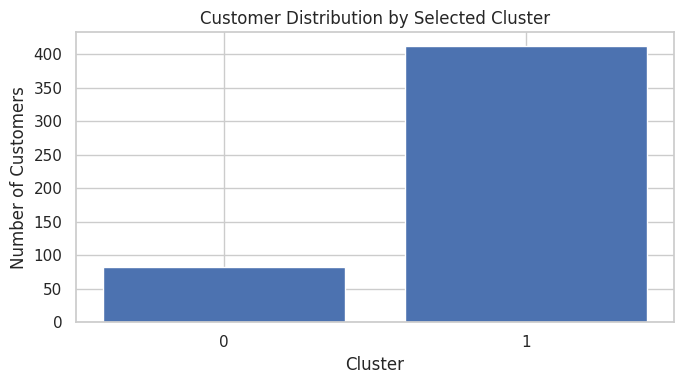

In [45]:
# Calculating customer distribution in the selected clustering model

stage5_cluster_distribution = (
    stage5_customer_profile["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Customer Count")
)
stage5_cluster_distribution["Percentage"] = (
    stage5_cluster_distribution["Customer Count"] /
    stage5_cluster_distribution["Customer Count"].sum() * 100
)

display(stage5_cluster_distribution.round({"Percentage": 2}))

plt.figure(figsize=(7, 4))
plt.bar(
    stage5_cluster_distribution["Cluster"].astype(str),
    stage5_cluster_distribution["Customer Count"]
)
plt.title("Customer Distribution by Selected Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Interpretasi hasil:**

Hasil distribusi menunjukkan bahwa Cluster 0 terdiri atas **83 pelanggan (16,77%)**, sedangkan Cluster 1 terdiri atas **412 pelanggan (83,23%)**.

Dengan demikian, hasil clustering membentuk satu kelompok pelanggan yang lebih kecil dan satu kelompok yang jauh lebih besar. Perbedaan ukuran ini tidak otomatis berarti cluster kecil lebih penting atau lebih bernilai. Karakteristik perilaku kedua kelompok perlu dilihat terlebih dahulu sebelum menentukan makna dan strategi bisnisnya.

Distribusi yang tidak seimbang ini juga menjadi salah satu keterbatasan segmentasi yang perlu diperhatikan ketika hasilnya digunakan untuk menyusun strategi bisnis.

## 5.3 Descriptive Cluster Profiling

Membandingkan nilai mean dan median dari 18 fitur yang digunakan pada representasi `C_Reduced18_Robust`. Median digunakan sebagai ukuran utama karena beberapa fitur memiliki distribusi yang menceng dan dapat dipengaruhi nilai ekstrem. Mean tetap ditampilkan sebagai informasi pendukung.

In [46]:
# Creating descriptive statistics for all 18 selected features

stage5_feature_profile_rows = []
for feature in reduced_feature_columns:
    group0 = stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 0, feature]
    group1 = stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 1, feature]
    mean0, mean1 = group0.mean(), group1.mean()
    median0, median1 = group0.median(), group1.median()
    pct_diff = np.nan if mean1 == 0 else (mean0 - mean1) / abs(mean1) * 100
    stage5_feature_profile_rows.append({
        "Feature": feature,
        "Mean Cluster 0": mean0,
        "Mean Cluster 1": mean1,
        "Median Cluster 0": median0,
        "Median Cluster 1": median1,
        "Mean Difference (%)": pct_diff
    })

stage5_feature_profile = pd.DataFrame(stage5_feature_profile_rows)
stage5_feature_profile["Absolute Mean Difference (%)"] = stage5_feature_profile["Mean Difference (%)"].abs()
stage5_feature_profile = stage5_feature_profile.sort_values(
    "Absolute Mean Difference (%)", ascending=False
).drop(columns="Absolute Mean Difference (%)")

display(stage5_feature_profile.round(3))

,Feature,Mean Cluster 0,Mean Cluster 1,Median Cluster 0,Median Cluster 1,Mean Difference (%)
11,Maximum_Login_Attempts,4.024,1.058,4.000,1.000,280.259
10,Average_Login_Attempts,1.630,1.012,1.571,1.000,61.038
6,Credit_Amount_Sum,446.465,324.159,254.920,155.290,37.730
0,Transaction_Record_Count,6.289,4.784,6.000,5.000,31.463
5,Debit_Amount_Sum,1385.493,1075.930,1294.770,933.970,28.772
1,Transaction_Span_Days,253.786,213.279,263.021,233.540,18.992
14,Online_Ratio,0.343,0.311,0.333,0.286,10.303
8,Std_Account_Balance,3766.168,3550.129,3592.863,3552.115,6.085
12,Credit_Ratio,0.227,0.216,0.200,0.200,5.086
4,Std_Transaction_Amount,267.267,255.545,234.762,231.719,4.587


**Interpretasi hasil:**

Hasil profiling menunjukkan bahwa Cluster 0 secara umum memiliki aktivitas transaksi yang lebih tinggi dibandingkan Cluster 1. Median jumlah transaksi pada Cluster 0 adalah **6 transaksi**, sedangkan Cluster 1 adalah **5 transaksi**. Median jumlah bulan aktif masing-masing sebesar **5 bulan** dan **4 bulan**.

Perbedaan juga terlihat pada total nominal transaksi yang teramati. Median `Observed_Transaction_Amount_Sum` Cluster 0 sebesar **1.718,02**, sedangkan Cluster 1 sebesar **1.195,43**. Namun, rata-rata nominal transaksi per transaksi relatif sama, yaitu sekitar **294** pada kedua cluster. Ini menunjukkan bahwa perbedaan total nominal lebih berkaitan dengan jumlah aktivitas transaksi, bukan karena nilai rata-rata setiap transaksi jauh lebih besar.

Rata-rata saldo akun juga hampir sama, sekitar **5.150** pada Cluster 0 dan **5.134** pada Cluster 1. Dengan demikian, kedua cluster tidak tepat disebut sebagai kelompok saldo tinggi dan saldo rendah.

Perbedaan yang paling menonjol terlihat pada fitur percobaan login. Median `Maximum_Login_Attempts` Cluster 0 sebesar **4**, sedangkan Cluster 1 sebesar **1**. Temuan ini perlu dibaca sebagai perbedaan jumlah percobaan login yang tercatat, bukan sebagai bukti adanya fraud atau aktivitas mencurigakan.

## 5.4 Statistical Comparison of Cluster Features

Melakukan perbandingan distribusi fitur antara Cluster 0 dan Cluster 1 menggunakan Mann–Whitney U test. Pengujian ini dipilih sebagai pendekatan non-parametrik karena beberapa fitur memiliki distribusi yang tidak simetris.

Ukuran efek yang ditampilkan adalah Cliff's Delta. Nilai positif menunjukkan kecenderungan nilai fitur lebih tinggi pada Cluster 0, sedangkan nilai negatif menunjukkan kecenderungan lebih tinggi pada Cluster 1. Nilai p kemudian disesuaikan menggunakan Benjamini–Hochberg untuk mengendalikan false discovery rate.

In [47]:
# Comparing feature distributions and adjusting p-values

stage5_test_rows = []
for feature in reduced_feature_columns:
    group0 = stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 0, feature].dropna().to_numpy()
    group1 = stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 1, feature].dropna().to_numpy()
    u_stat, p_value = mannwhitneyu(group0, group1, alternative="two-sided")
    cliffs_delta = (2 * u_stat / (len(group0) * len(group1))) - 1
    stage5_test_rows.append({
        "Feature": feature,
        "Cliff's Delta (C0 vs C1)": cliffs_delta,
        "P-Value": p_value,
        "N Cluster 0": len(group0),
        "N Cluster 1": len(group1)
    })

stage5_feature_tests = pd.DataFrame(stage5_test_rows)

# Benjamini-Hochberg false discovery rate adjustment (implemented directly).
p_values = stage5_feature_tests["P-Value"].to_numpy()
order = np.argsort(p_values)
ranked = p_values[order]
q_ranked = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
q_values = np.empty_like(q_ranked)
q_values[order] = np.clip(q_ranked, 0, 1)
stage5_feature_tests["Adjusted P-Value (BH)"] = q_values
stage5_feature_tests["Absolute Cliff's Delta"] = stage5_feature_tests["Cliff's Delta (C0 vs C1)"].abs()
stage5_feature_tests = stage5_feature_tests.sort_values(
    "Absolute Cliff's Delta", ascending=False
).drop(columns="Absolute Cliff's Delta")

stage5_significant_features = stage5_feature_tests[
    stage5_feature_tests["Adjusted P-Value (BH)"] < 0.05
]

display(stage5_feature_tests.round(4))
print("Features with adjusted p-value below 0.05:", len(stage5_significant_features))

,Feature,Cliff's Delta (C0 vs C1),P-Value,N Cluster 0,N Cluster 1,Adjusted P-Value (BH)
11,Maximum_Login_Attempts,0.9993,0.0000,83,412,0.0000
10,Average_Login_Attempts,0.9910,0.0000,83,412,0.0000
0,Transaction_Record_Count,0.3715,0.0000,83,412,0.0000
5,Debit_Amount_Sum,0.2170,0.0018,83,412,0.0081
1,Transaction_Span_Days,0.2049,0.0032,83,412,0.0096
6,Credit_Amount_Sum,0.2017,0.0032,83,412,0.0096
16,Locations_Per_Transaction,-0.1441,0.0091,83,412,0.0205
15,Merchants_Per_Transaction,-0.1201,0.0074,83,412,0.0189
14,Online_Ratio,0.1062,0.1246,83,412,0.2243
2,Transactions_Per_Active_Month,0.1045,0.1186,83,412,0.2243


Features with adjusted p-value below 0.05: 8


**Interpretasi hasil:**

Hasil perbandingan menunjukkan bahwa perbedaan paling kuat antara kedua cluster terdapat pada `Maximum_Login_Attempts` dan `Average_Login_Attempts`. Kedua fitur tersebut memiliki ukuran efek yang sangat besar dan nilai adjusted p-value di bawah 0,05.

Perbedaan yang juga terlihat pada tingkat aktivitas adalah jumlah transaksi, total nominal Debit dan Credit, serta rentang waktu aktivitas transaksi. Sebaliknya, fitur seperti rata-rata nominal transaksi dan rata-rata saldo akun tidak menunjukkan perbedaan yang berarti antara kedua cluster.

Hasil uji statistik ini digunakan sebagai pendukung deskriptif, bukan sebagai bukti independen bahwa segmentasi pasti berlaku pada populasi yang lebih luas. Fitur-fitur yang diuji juga merupakan bagian dari variabel yang digunakan untuk membentuk cluster, sehingga perbedaan di antara cluster memang diharapkan muncul.

## 5.5 Visual Comparison of Important Features

Memvisualisasikan beberapa fitur yang paling mudah menjelaskan perbedaan perilaku pelanggan. Grafik digunakan untuk melihat pola distribusi, bukan hanya membandingkan satu nilai rata-rata.

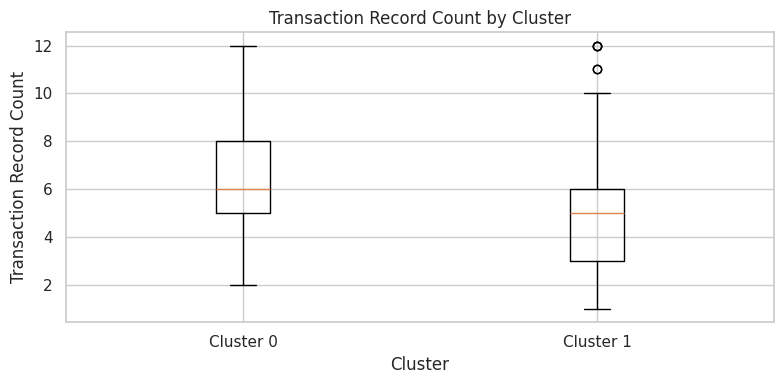

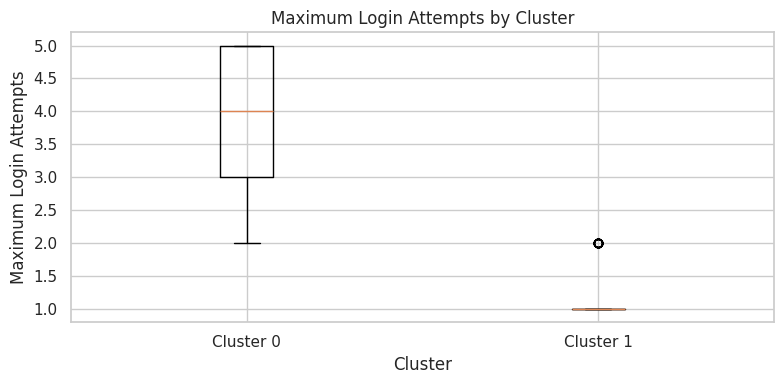

In [48]:
# Comparing transaction activity across clusters

plt.figure(figsize=(8, 4))
box_data = [
    stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 0, "Transaction_Record_Count"],
    stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 1, "Transaction_Record_Count"]
]
plt.boxplot(box_data, labels=["Cluster 0", "Cluster 1"], showfliers=True)
plt.title("Transaction Record Count by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Transaction Record Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
box_data = [
    stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 0, "Maximum_Login_Attempts"],
    stage5_customer_profile.loc[stage5_customer_profile["Cluster"] == 1, "Maximum_Login_Attempts"]
]
plt.boxplot(box_data, labels=["Cluster 0", "Cluster 1"], showfliers=True)
plt.title("Maximum Login Attempts by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Maximum Login Attempts")
plt.tight_layout()
plt.show()

**Interpretasi hasil:**

Visualisasi jumlah transaksi memperlihatkan bahwa Cluster 0 memiliki nilai tengah yang sedikit lebih tinggi dibandingkan Cluster 1. Hal ini sejalan dengan hasil statistik deskriptif sebelumnya, yaitu kelompok Cluster 0 cenderung memiliki jumlah transaksi dan bulan aktif yang lebih banyak.

Perbedaan yang lebih jelas terlihat pada `Maximum_Login_Attempts`. Sebagian besar pelanggan Cluster 1 berada pada nilai yang lebih rendah, sedangkan Cluster 0 memiliki nilai tengah dan rentang nilai yang lebih tinggi.

Temuan ini menunjukkan bahwa jumlah percobaan login merupakan salah satu pembeda utama antara kedua kelompok. Untuk memahami penyebabnya, diperlukan data tambahan seperti status login berhasil/gagal dan catatan autentikasi. Data yang tersedia saat ini belum cukup untuk menyimpulkan penyebab percobaan login yang lebih tinggi.

## 5.6 PCA Visualization

Menggunakan Principal Component Analysis (PCA) untuk memproyeksikan 18 fitur ke dalam dua dimensi agar struktur cluster dapat dilihat secara visual. Sebelum PCA, fitur diberi RobustScaler dengan pendekatan yang sama seperti konfigurasi model terpilih pada Tahap 3.

PCA berfungsi sebagai alat bantu visualisasi. Dua komponen utama tidak mewakili seluruh informasi dari 18 fitur, sehingga plot ini tidak digunakan sebagai satu-satunya dasar penilaian kualitas cluster.

ARI between saved Stage 3 labels and reproduced labels: 1.0000
PC1 explained variance: 18.84%
PC2 explained variance: 14.77%
Total explained variance (PC1 + PC2): 33.61%


,AccountID,PC1,PC2,Cluster
0,AC00001,-2.343417,0.168147,1
1,AC00002,0.500815,0.458379,1
2,AC00003,-0.561869,-0.261048,1
3,AC00004,-0.157462,-0.408899,1
4,AC00005,0.873413,-0.367401,1


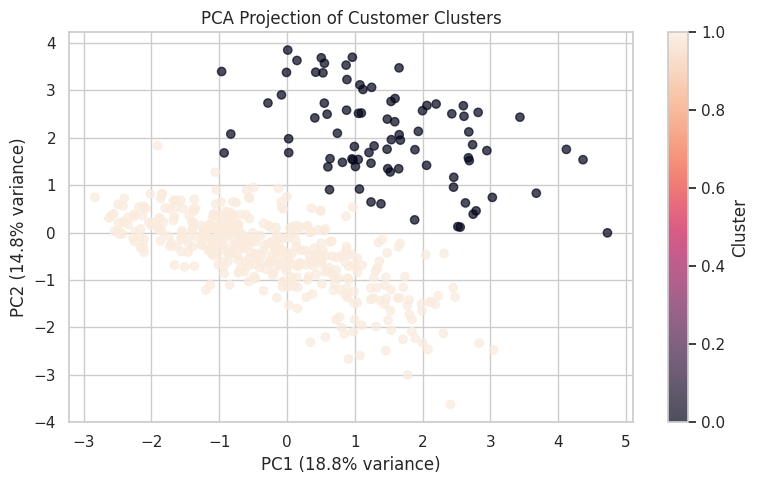

In [49]:
# Reconstructing the selected robust-scaled representation and applying PCA

X_stage5_unscaled = reduced_features_df.set_index("AccountID")[reduced_feature_columns]
scaler_stage5 = RobustScaler()
X_stage5_scaled = scaler_stage5.fit_transform(X_stage5_unscaled)

# Verify that the selected K-Means labels can be reproduced with Stage 3 parameters.
stage5_kmeans_check = KMeans(
    n_clusters=2, random_state=42, n_init=30, max_iter=500
)
reproduced_labels = stage5_kmeans_check.fit_predict(X_stage5_scaled)
reproduction_ari = adjusted_rand_score(
    stage5_label_df.set_index("AccountID").loc[X_stage5_unscaled.index, "Cluster"],
    reproduced_labels
)
print(f"ARI between saved Stage 3 labels and reproduced labels: {reproduction_ari:.4f}")

pca_stage5 = PCA(n_components=2, random_state=42)
pcs_stage5 = pca_stage5.fit_transform(X_stage5_scaled)
stage5_pca_coordinates = pd.DataFrame({
    "AccountID": X_stage5_unscaled.index,
    "PC1": pcs_stage5[:, 0],
    "PC2": pcs_stage5[:, 1],
    "Cluster": stage5_label_df.set_index("AccountID").loc[X_stage5_unscaled.index, "Cluster"].to_numpy()
})

explained_pc1 = pca_stage5.explained_variance_ratio_[0] * 100
explained_pc2 = pca_stage5.explained_variance_ratio_[1] * 100
explained_total = pca_stage5.explained_variance_ratio_.sum() * 100
print(f"PC1 explained variance: {explained_pc1:.2f}%")
print(f"PC2 explained variance: {explained_pc2:.2f}%")
print(f"Total explained variance (PC1 + PC2): {explained_total:.2f}%")

display(stage5_pca_coordinates.head())

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    stage5_pca_coordinates["PC1"],
    stage5_pca_coordinates["PC2"],
    c=stage5_pca_coordinates["Cluster"],
    alpha=0.7
)
plt.title("PCA Projection of Customer Clusters")
plt.xlabel(f"PC1 ({explained_pc1:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_pc2:.1f}% variance)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

**Interpretasi hasil:**

Hasil pemeriksaan reproduksi menghasilkan ARI sebesar **1,00**, yang menunjukkan bahwa label K-Means yang dibentuk ulang dengan parameter yang sama sesuai dengan label hasil Tahap 3.

Dua komponen utama PCA menjelaskan sekitar **33,61% variasi data**. Artinya, visualisasi dua dimensi ini hanya menampilkan sebagian informasi dari 18 fitur yang digunakan dalam clustering.

PCA membantu melihat kecenderungan posisi pelanggan pada ruang dua dimensi, tetapi sebagian informasi tetap berada pada komponen lainnya. Oleh sebab itu, kualitas pemisahan cluster tetap perlu dibaca bersama Silhouette Score pada Tahap 4 dan hasil profiling fitur pada bagian sebelumnya.

## 5.7 Transaction Channel and Type Analysis

Menghubungkan label cluster dengan cleaned transaction dataset untuk melihat apakah terdapat perbedaan pola kanal transaksi dan jenis transaksi.

Transaksi tanpa `AccountID` tidak dapat dipasangkan dengan cluster sehingga dikeluarkan dari analisis ini. Baris dengan nilai `Channel` atau `TransactionType` kosong tetap dihitung dalam pemeriksaan kualitas data, tetapi tidak dimasukkan ke dalam persentase kategori yang diketahui.

In [50]:
# Joining transaction-level records to customer clusters

stage5_transactions = cleaned_transactions_df[
    cleaned_transactions_df["AccountID"].notna()
].merge(
    stage5_label_df,
    on="AccountID",
    how="inner",
    validate="many_to_one"
)

# Channel proportions are calculated among records with a known channel.
stage5_channel_counts = pd.crosstab(
    stage5_transactions["Cluster"], stage5_transactions["Channel"]
)
stage5_channel_mix = pd.crosstab(
    stage5_transactions["Cluster"], stage5_transactions["Channel"],
    normalize="index"
) * 100
stage5_channel_mix = stage5_channel_mix.reset_index().melt(
    id_vars="Cluster", var_name="Channel", value_name="Percentage"
)

# Transaction type proportions are calculated among records with a known type.
stage5_type_counts = pd.crosstab(
    stage5_transactions["Cluster"], stage5_transactions["TransactionType"]
)
stage5_type_mix = pd.crosstab(
    stage5_transactions["Cluster"], stage5_transactions["TransactionType"],
    normalize="index"
) * 100
stage5_type_mix = stage5_type_mix.reset_index().melt(
    id_vars="Cluster", var_name="Transaction Type", value_name="Percentage"
)

print("Transaction rows assigned to a customer cluster:", len(stage5_transactions))
print("Transactions without AccountID excluded:", cleaned_transactions_df["AccountID"].isna().sum())
print("\nChannel mix (% of records with known channel):")
display(stage5_channel_mix.round(2))
print("\nTransaction type mix (% of records with known type):")
display(stage5_type_mix.round(2))
print("\nKnown channel counts:")
display(stage5_channel_counts)
print("\nKnown transaction type counts:")
display(stage5_type_counts)

Transaction rows assigned to a customer cluster: 2493
Transactions without AccountID excluded: 20

Channel mix (% of records with known channel):


,Cluster,Channel,Percentage
0,0,ATM,32.50
1,1,ATM,33.71
2,0,Branch,33.66
3,1,Branch,34.68
4,0,Online,33.85
5,1,Online,31.61



Transaction type mix (% of records with known type):


,Cluster,Transaction Type,Percentage
0,0,Credit,22.91
1,1,Credit,22.48
2,0,Debit,77.09
3,1,Debit,77.52



Known channel counts:


Channel,ATM,Branch,Online
Cluster,,,
0,168,174,175
1,657,676,616



Known transaction type counts:


TransactionType,Credit,Debit
Cluster,,
0,118,397
1,438,1510


**Interpretasi hasil:**

Dari 2.513 baris pada cleaned transaction dataset, sebanyak **2.493 transaksi** memiliki `AccountID` dan dapat dihubungkan dengan 495 pelanggan. Sebanyak 20 baris tidak memiliki `AccountID`, sehingga tidak dapat dimasukkan ke analisis berdasarkan cluster.

Proporsi kanal ATM, Branch, dan Online terlihat relatif serupa pada kedua cluster. Pada Cluster 0, transaksi Online sekitar 33,85%, sedangkan pada Cluster 1 sekitar 31,61%. Perbedaan ini belum menunjukkan adanya preferensi kanal yang sangat kuat.

Jenis transaksi juga relatif serupa. Debit mencakup sekitar 77,09% transaksi yang memiliki informasi jenis transaksi pada Cluster 0 dan 77,52% pada Cluster 1. Dengan demikian, pembeda utama kedua cluster bukanlah pilihan kanal atau jenis transaksi, melainkan tingkat aktivitas dan jumlah percobaan login yang tercatat.

## 5.8 Data Quality Review and Cluster Labeling

Memeriksa kembali kelengkapan atribut transaksi yang digunakan sebagai pendukung interpretasi bisnis. Pada bagian ini, konsistensi `CustomerAge` dan `CustomerOccupation` juga diperiksa pada tingkat `AccountID`.

Jika suatu atribut memiliki nilai berbeda di antara transaksi milik akun yang sama, atribut tersebut tidak digunakan untuk membuat kesimpulan demografis pelanggan. Setelah itu, nama segmen diberikan berdasarkan fitur yang benar-benar menunjukkan perbedaan yang konsisten.

In [51]:
# Reviewing transaction data quality and assigning descriptive segment names

assigned_account_ids = set(stage5_label_df["AccountID"])
quality_transactions = stage5_transactions.copy()

age_nunique_by_account = quality_transactions.groupby("AccountID")["CustomerAge"].nunique(dropna=True)
occupation_nunique_by_account = quality_transactions.groupby("AccountID")["CustomerOccupation"].nunique(dropna=True)

stage5_data_quality = pd.DataFrame([
    {"Check": "Customer accounts in selected model", "Count": stage5_label_df["AccountID"].nunique()},
    {"Check": "Transaction rows in cleaned dataset", "Count": len(cleaned_transactions_df)},
    {"Check": "Transaction rows with AccountID", "Count": len(stage5_transactions)},
    {"Check": "Transaction rows without AccountID", "Count": cleaned_transactions_df["AccountID"].isna().sum()},
    {"Check": "Missing Channel values among assigned transactions", "Count": quality_transactions["Channel"].isna().sum()},
    {"Check": "Missing TransactionType values among assigned transactions", "Count": quality_transactions["TransactionType"].isna().sum()},
    {"Check": "Missing CustomerAge values among assigned transactions", "Count": quality_transactions["CustomerAge"].isna().sum()},
    {"Check": "Missing CustomerOccupation values among assigned transactions", "Count": quality_transactions["CustomerOccupation"].isna().sum()},
    {"Check": "Accounts with more than one recorded age", "Count": int((age_nunique_by_account > 1).sum())},
    {"Check": "Accounts with more than one recorded occupation", "Count": int((occupation_nunique_by_account > 1).sum())}
])

display(stage5_data_quality)

segment_name_mapping = {
    0: "Aktivitas Relatif Lebih Tinggi dan Lebih Banyak Percobaan Login",
    1: "Aktivitas Relatif Lebih Rendah"
}
stage5_customer_profile["Behavioral Segment"] = stage5_customer_profile["Cluster"].map(segment_name_mapping)

stage5_segment_summary = (
    stage5_customer_profile.groupby(["Cluster", "Behavioral Segment"])
    .agg(
        Customer_Count=("AccountID", "nunique"),
        Median_Transactions=("Transaction_Record_Count", "median"),
        Median_Active_Months=("Active_Months", "median"),
        Median_Observed_Amount=("Observed_Transaction_Amount_Sum", "median"),
        Median_Max_Login_Attempts=("Maximum_Login_Attempts", "median"),
        Median_Account_Balance=("Average_Account_Balance", "median")
    )
    .reset_index()
)
stage5_segment_summary["Customer_Percentage"] = (
    stage5_segment_summary["Customer_Count"] / len(stage5_customer_profile) * 100
)
display(stage5_segment_summary.round(2))

,Check,Count
0,Customer accounts in selected model,495
1,Transaction rows in cleaned dataset,2513
2,Transaction rows with AccountID,2493
3,Transaction rows without AccountID,20
4,Missing Channel values among assigned transact...,27
5,Missing TransactionType values among assigned ...,30
6,Missing CustomerAge values among assigned tran...,18
7,Missing CustomerOccupation values among assign...,23
8,Accounts with more than one recorded age,467
9,Accounts with more than one recorded occupation,460


,Cluster,Behavioral Segment,Customer_Count,Median_Transactions,Median_Active_Months,Median_Observed_Amount,Median_Max_Login_Attempts,Median_Account_Balance,Customer_Percentage
0,0,Aktivitas Relatif Lebih Tinggi dan Lebih Banya...,83,6.0,5.0,1718.02,4.0,5081.76,16.77
1,1,Aktivitas Relatif Lebih Rendah,412,5.0,4.0,1195.43,1.0,5089.99,83.23


**Interpretasi hasil:**

Pemeriksaan kualitas data menunjukkan bahwa 20 baris transaksi tidak memiliki `AccountID`. Selain itu, terdapat nilai kosong pada `Channel`, `TransactionType`, `CustomerAge`, dan `CustomerOccupation`.

Pemeriksaan konsistensi juga menunjukkan bahwa **467 dari 495 akun memiliki lebih dari satu nilai usia yang tercatat**, sedangkan **460 akun memiliki lebih dari satu kategori pekerjaan** pada baris transaksinya. Karena kedua atribut tersebut tidak konsisten pada tingkat akun, usia dan pekerjaan tidak digunakan untuk memberi nama segmen atau membuat rekomendasi demografis.

Berdasarkan fitur yang paling jelas membedakan kedua cluster, Cluster 0 diberi nama **Aktivitas Relatif Lebih Tinggi dan Lebih Banyak Percobaan Login**. Cluster 1 diberi nama **Aktivitas Relatif Lebih Rendah**. Nama tersebut bersifat deskriptif dan tidak menunjukkan nilai pelanggan, tingkat kekayaan, maupun risiko fraud.

## 5.9 Export Cluster Profiling Results

Menyimpan hasil profiling agar dapat digunakan kembali pada tahap interpretasi bisnis dan sebagai dokumentasi penelitian.

In [52]:
# Exporting Stage 5 profiling artifacts

stage5_output_dir = Path("stage5_outputs")
stage5_output_dir.mkdir(exist_ok=True)

stage5_cluster_distribution.to_csv(stage5_output_dir / "stage5_cluster_distribution.csv", index=False)
stage5_feature_profile.to_csv(stage5_output_dir / "stage5_feature_profile.csv", index=False)
stage5_feature_tests.to_csv(stage5_output_dir / "stage5_feature_tests.csv", index=False)
stage5_channel_mix.to_csv(stage5_output_dir / "stage5_channel_mix.csv", index=False)
stage5_type_mix.to_csv(stage5_output_dir / "stage5_transaction_type_mix.csv", index=False)
stage5_segment_summary.to_csv(stage5_output_dir / "stage5_segment_summary.csv", index=False)
stage5_data_quality.to_csv(stage5_output_dir / "stage5_data_quality_checks.csv", index=False)
stage5_pca_coordinates.to_csv(stage5_output_dir / "stage5_pca_coordinates.csv", index=False)

stage5_customer_segments = stage5_customer_profile[
    ["AccountID", "Cluster", "Behavioral Segment"] +
    [c for c in customer_features_df.columns if c != "AccountID"]
].copy()
stage5_customer_segments.to_csv(
    stage5_output_dir / "stage5_customer_segments.csv", index=False
)

print("Stage 5 outputs successfully exported:")
for output_file in sorted(stage5_output_dir.iterdir()):
    print("-", output_file.name)

Stage 5 outputs successfully exported:
- stage5_channel_mix.csv
- stage5_cluster_distribution.csv
- stage5_customer_segments.csv
- stage5_data_quality_checks.csv
- stage5_feature_profile.csv
- stage5_feature_tests.csv
- stage5_pca_coordinates.csv
- stage5_segment_summary.csv
- stage5_transaction_type_mix.csv


**Interpretasi hasil:**

Seluruh hasil Cluster Profiling berhasil disimpan ke folder `stage5_outputs`. File tersebut mencakup distribusi cluster, ringkasan fitur, hasil perbandingan statistik, komposisi kanal dan jenis transaksi, ringkasan segmen, pemeriksaan kualitas data, koordinat PCA, serta daftar pelanggan beserta label segmennya.

Artefak ini menjadi dasar untuk menyusun business interpretation dan rekomendasi pada Tahap 6.

# 6. BUSINESS INTERPRETATION & RECOMMENDATIONS

Tahap ini mengubah hasil clustering menjadi pemahaman perilaku pelanggan dan rekomendasi yang dapat dipertimbangkan dari perspektif bisnis. Rekomendasi dibatasi pada temuan yang benar-benar terlihat di dalam data.

Hasil clustering bersifat eksploratif. Model belum memiliki label kebenaran (ground truth) dan belum diuji terhadap outcome bisnis seperti profitabilitas, churn, kepuasan, atau fraud. Oleh karena itu, rekomendasi berikut diposisikan sebagai hipotesis strategi yang perlu diuji lebih lanjut, bukan keputusan otomatis terhadap pelanggan.

## 6.1 Summary of Customer Behavior Insights

Merangkum perbedaan perilaku utama yang ditemukan pada Tahap 5. Fokus diberikan pada aktivitas transaksi, total nominal transaksi, percobaan login, saldo, serta pola kanal transaksi.

In [53]:
# Building a concise evidence-based customer insight summary

cluster_means = stage5_customer_profile.groupby("Cluster").agg(
    Customers=("AccountID", "nunique"),
    Transactions_Mean=("Transaction_Record_Count", "mean"),
    Active_Months_Mean=("Active_Months", "mean"),
    Observed_Amount_Sum_Mean=("Observed_Transaction_Amount_Sum", "mean"),
    Avg_Transaction_Amount_Mean=("Average_Transaction_Amount", "mean"),
    Avg_Balance_Mean=("Average_Account_Balance", "mean"),
    Avg_Login_Attempts_Mean=("Average_Login_Attempts", "mean"),
    Max_Login_Attempts_Mean=("Maximum_Login_Attempts", "mean")
).reset_index()

display(cluster_means.round(2))

stage6_insight_summary = pd.DataFrame([
    {
        "Insight Area": "Transaction activity",
        "Cluster 0": "Higher: mean 6.29 transaction records per customer",
        "Cluster 1": "Lower: mean 4.78 transaction records per customer",
        "Interpretation": "Cluster 0 records more transaction activity in the observed dataset."
    },
    {
        "Insight Area": "Active period",
        "Cluster 0": "Mean 5.00 active months",
        "Cluster 1": "Mean 3.91 active months",
        "Interpretation": "Cluster 0 is observed across more active months on average."
    },
    {
        "Insight Area": "Transaction amount",
        "Cluster 0": "Mean average transaction amount about 294.01",
        "Cluster 1": "Mean average transaction amount about 294.40",
        "Interpretation": "Average transaction amount is almost identical; total amount differs mainly alongside transaction count."
    },
    {
        "Insight Area": "Login attempts",
        "Cluster 0": "Mean maximum login attempts 4.02",
        "Cluster 1": "Mean maximum login attempts 1.06",
        "Interpretation": "More login attempts are recorded in Cluster 0; their success or failure is unknown."
    },
    {
        "Insight Area": "Account balance",
        "Cluster 0": "Mean average account balance about 5,150.63",
        "Cluster 1": "Mean average account balance about 5,134.17",
        "Interpretation": "Average balance is very similar between clusters."
    },
    {
        "Insight Area": "Transaction channel",
        "Cluster 0": "ATM 32.50%, Branch 33.66%, Online 33.85%",
        "Cluster 1": "ATM 33.71%, Branch 34.68%, Online 31.61%",
        "Interpretation": "The channel mix is broadly similar across the two clusters."
    }
])
display(stage6_insight_summary)

,Cluster,Customers,Transactions_Mean,Active_Months_Mean,Observed_Amount_Sum_Mean,Avg_Transaction_Amount_Mean,Avg_Balance_Mean,Avg_Login_Attempts_Mean,Max_Login_Attempts_Mean
0,0,83,6.29,5.00,1847.41,294.01,5150.63,1.63,4.02
1,1,412,4.78,3.91,1413.67,294.40,5134.17,1.01,1.06


,Insight Area,Cluster 0,Cluster 1,Interpretation
0,Transaction activity,Higher: mean 6.29 transaction records per cust...,Lower: mean 4.78 transaction records per customer,Cluster 0 records more transaction activity in...
1,Active period,Mean 5.00 active months,Mean 3.91 active months,Cluster 0 is observed across more active month...
2,Transaction amount,Mean average transaction amount about 294.01,Mean average transaction amount about 294.40,Average transaction amount is almost identical...
3,Login attempts,Mean maximum login attempts 4.02,Mean maximum login attempts 1.06,More login attempts are recorded in Cluster 0;...
4,Account balance,"Mean average account balance about 5,150.63","Mean average account balance about 5,134.17",Average balance is very similar between clusters.
5,Transaction channel,"ATM 32.50%, Branch 33.66%, Online 33.85%","ATM 33.71%, Branch 34.68%, Online 31.61%",The channel mix is broadly similar across the ...


**Interpretasi hasil:**

Hasil rangkuman menunjukkan bahwa perbedaan utama kedua cluster terletak pada intensitas aktivitas. Cluster 0 mencatat rata-rata sekitar **6,29 transaksi per pelanggan**, dibandingkan **4,78 transaksi** pada Cluster 1. Cluster 0 juga memiliki rata-rata bulan aktif yang lebih tinggi.

Meskipun total nominal transaksi Cluster 0 lebih tinggi, rata-rata nominal setiap transaksi hampir sama pada kedua cluster. Rata-rata saldo akun juga relatif serupa. Dengan demikian, Cluster 0 lebih tepat dipahami sebagai kelompok dengan aktivitas transaksi yang lebih tinggi, bukan kelompok pelanggan dengan saldo atau nilai transaksi per transaksi yang lebih tinggi.

Jumlah percobaan login yang lebih besar pada Cluster 0 merupakan temuan lain yang perlu diperiksa lebih lanjut. Data yang tersedia tidak membedakan percobaan login berhasil dan gagal, sehingga temuan ini belum dapat diartikan sebagai masalah keamanan atau indikasi fraud.

Pola ATM, Branch, dan Online relatif serupa. Karena itu, strategi bisnis tidak perlu membedakan kedua cluster hanya berdasarkan preferensi kanal.

## 6.2 Business Implications

Menghubungkan temuan kuantitatif dengan kemungkinan implikasi bisnis. Setiap implikasi disusun secara hati-hati agar tidak melampaui informasi yang tersedia di dataset.

In [54]:
# Presenting business implications derived from the observed cluster differences

stage6_business_implications = pd.DataFrame([
    {
        "Observed Finding": "Cluster 0 has more transaction records and active months.",
        "Business Implication": "This group may already have more frequent engagement with the bank's transaction services.",
        "Interpretation Boundary": "The data does not establish that these customers are more profitable or more loyal."
    },
    {
        "Observed Finding": "Cluster 0 has higher maximum and average login attempts.",
        "Business Implication": "The bank may review the login journey and authentication experience for this group.",
        "Interpretation Boundary": "Login success/failure, device risk, and fraud outcomes are not available."
    },
    {
        "Observed Finding": "Average transaction amount and average balance are similar across clusters.",
        "Business Implication": "Activity level should not be treated as a direct proxy for customer wealth or value.",
        "Interpretation Boundary": "Revenue, fees, profitability, and customer lifetime value are not measured."
    },
    {
        "Observed Finding": "ATM, Branch, and Online proportions are broadly similar.",
        "Business Implication": "A consistent cross-channel experience may be more relevant than a channel-specific strategy based on these clusters.",
        "Interpretation Boundary": "The dataset does not explain channel satisfaction or reasons for channel choice."
    }
])
display(stage6_business_implications)

,Observed Finding,Business Implication,Interpretation Boundary
0,Cluster 0 has more transaction records and act...,This group may already have more frequent enga...,The data does not establish that these custome...
1,Cluster 0 has higher maximum and average login...,The bank may review the login journey and auth...,"Login success/failure, device risk, and fraud ..."
2,Average transaction amount and average balance...,Activity level should not be treated as a dire...,"Revenue, fees, profitability, and customer lif..."
3,"ATM, Branch, and Online proportions are broadl...",A consistent cross-channel experience may be m...,The dataset does not explain channel satisfact...


**Interpretasi hasil:**

Hasil business interpretation menunjukkan bahwa Cluster 0 berpotensi menjadi kelompok yang sudah lebih sering berinteraksi dengan layanan transaksi bank. Kondisi ini dapat menjadi dasar untuk menguji program engagement atau pemeliharaan hubungan pelanggan.

Di sisi lain, jumlah percobaan login yang lebih tinggi dapat menjadi alasan untuk meninjau kemudahan proses login dan autentikasi. Namun, pemeriksaan tersebut perlu didukung data tambahan agar bank dapat membedakan apakah percobaan berulang disebabkan oleh lupa kredensial, kendala teknis, atau faktor lainnya.

Karena rata-rata nominal transaksi dan saldo kedua cluster relatif serupa, hasil segmentasi ini tidak cukup untuk menentukan kelas kekayaan atau nilai ekonomi pelanggan. Begitu pula, komposisi kanal yang hampir sama belum mendukung strategi yang membedakan pelanggan berdasarkan kanal tertentu.

## 6.3 Strategic Recommendations

Menyusun rekomendasi yang dapat diuji berdasarkan karakteristik cluster. Rekomendasi tidak dianggap sebagai hasil yang sudah terbukti berhasil; implementasinya perlu dievaluasi melalui pilot program dan pengukuran KPI.

In [55]:
# Preparing practical recommendations for each customer segment

stage6_recommendations = pd.DataFrame([
    {
        "Target Segment": "Aktivitas Relatif Lebih Tinggi dan Lebih Banyak Percobaan Login (Cluster 0)",
        "Recommendation": "Pertahankan engagement melalui komunikasi layanan yang relevan dan program apresiasi yang tidak hanya bergantung pada besarnya saldo.",
        "Reason": "Kelompok ini memiliki jumlah transaksi dan bulan aktif yang lebih tinggi.",
        "Validation Needed": "Uji respons, repeat transaction rate, dan perubahan aktivitas sebelum dan sesudah program."
    },
    {
        "Target Segment": "Aktivitas Relatif Lebih Tinggi dan Lebih Banyak Percobaan Login (Cluster 0)",
        "Recommendation": "Tinjau pengalaman login dan autentikasi; periksa log berhasil/gagal, pola pengulangan, dan keluhan pengguna.",
        "Reason": "Rata-rata dan maksimum percobaan login yang tercatat lebih tinggi pada kelompok ini.",
        "Validation Needed": "Tambahkan login success/failure logs, reset-password events, dan laporan kendala; jangan menganggapnya sebagai fraud tanpa bukti."
    },
    {
        "Target Segment": "Aktivitas Relatif Lebih Rendah (Cluster 1)",
        "Recommendation": "Uji program engagement ringan, edukasi fitur, atau pengingat layanan yang relevan untuk mendorong penggunaan berulang.",
        "Reason": "Kelompok ini memiliki lebih sedikit transaksi dan bulan aktif dalam periode pengamatan.",
        "Validation Needed": "Lakukan pilot terukur dan bandingkan perubahan aktivitas dengan kelompok pembanding."
    },
    {
        "Target Segment": "Kedua cluster",
        "Recommendation": "Pertahankan pengalaman layanan yang konsisten di ATM, Branch, dan Online.",
        "Reason": "Komposisi kanal transaksi kedua kelompok relatif serupa.",
        "Validation Needed": "Ukur kualitas layanan, keluhan, keberhasilan transaksi, dan kepuasan per kanal."
    },
    {
        "Target Segment": "Kedua cluster",
        "Recommendation": "Gunakan label cluster sebagai alat bantu analisis, bukan sebagai dasar tunggal untuk keputusan kredit, pembatasan akun, atau penilaian risiko.",
        "Reason": "Clustering bersifat eksploratif dan belum divalidasi dengan outcome bisnis atau risiko.",
        "Validation Needed": "Lakukan validasi eksternal sebelum digunakan pada keputusan operasional yang berdampak pada pelanggan."
    }
])
display(stage6_recommendations)

,Target Segment,Recommendation,Reason,Validation Needed
0,Aktivitas Relatif Lebih Tinggi dan Lebih Banya...,Pertahankan engagement melalui komunikasi laya...,Kelompok ini memiliki jumlah transaksi dan bul...,"Uji respons, repeat transaction rate, dan peru..."
1,Aktivitas Relatif Lebih Tinggi dan Lebih Banya...,Tinjau pengalaman login dan autentikasi; perik...,Rata-rata dan maksimum percobaan login yang te...,"Tambahkan login success/failure logs, reset-pa..."
2,Aktivitas Relatif Lebih Rendah (Cluster 1),"Uji program engagement ringan, edukasi fitur, ...",Kelompok ini memiliki lebih sedikit transaksi ...,Lakukan pilot terukur dan bandingkan perubahan...
3,Kedua cluster,Pertahankan pengalaman layanan yang konsisten ...,Komposisi kanal transaksi kedua kelompok relat...,"Ukur kualitas layanan, keluhan, keberhasilan t..."
4,Kedua cluster,Gunakan label cluster sebagai alat bantu anali...,Clustering bersifat eksploratif dan belum diva...,Lakukan validasi eksternal sebelum digunakan p...


**Interpretasi hasil:**

Rekomendasi untuk Cluster 0 berfokus pada pemeliharaan engagement dan pemeriksaan pengalaman login. Rekomendasi ini didasarkan pada jumlah transaksi, bulan aktif, dan percobaan login yang relatif lebih tinggi.

Untuk Cluster 1, pendekatan yang dapat diuji adalah edukasi fitur atau program engagement ringan agar pelanggan memiliki kesempatan untuk menggunakan layanan secara lebih rutin. Namun, aktivitas yang lebih rendah tidak selalu berarti pelanggan tidak puas atau berisiko churn. Data churn dan kepuasan belum tersedia.

Untuk kedua cluster, kualitas layanan perlu dijaga secara konsisten pada seluruh kanal karena distribusi ATM, Branch, dan Online tidak menunjukkan perbedaan yang besar. Seluruh rekomendasi perlu diuji melalui program percontohan sebelum diterapkan secara luas.

## 6.4 Suggested Business Monitoring KPIs

Menentukan indikator yang dapat digunakan untuk mengukur apakah rekomendasi bisnis memberikan perubahan yang diharapkan. KPI berikut merupakan usulan pengukuran untuk tahap implementasi, bukan metrik yang sudah tersedia pada dataset saat ini.

In [56]:
# Defining measurable KPIs for future business validation

stage6_kpi_framework = pd.DataFrame([
    {"Business Objective": "Increase recurring engagement", "Suggested KPI": "Transactions per active customer per month", "Why It Matters": "Measures whether customer activity becomes more regular."},
    {"Business Objective": "Improve customer activity", "Suggested KPI": "Active months and repeat transaction rate", "Why It Matters": "Measures continuity of customer interaction over time."},
    {"Business Objective": "Improve login experience", "Suggested KPI": "Login success rate and repeated failed-login rate", "Why It Matters": "Helps distinguish normal repeated attempts from authentication friction."},
    {"Business Objective": "Maintain channel service quality", "Suggested KPI": "Transaction success rate and complaint rate by channel", "Why It Matters": "Evaluates service quality across ATM, Branch, and Online."},
    {"Business Objective": "Evaluate campaign effectiveness", "Suggested KPI": "Incremental change versus a control group", "Why It Matters": "Helps determine whether a program causes measurable improvement."}
])
display(stage6_kpi_framework)

,Business Objective,Suggested KPI,Why It Matters
0,Increase recurring engagement,Transactions per active customer per month,Measures whether customer activity becomes mor...
1,Improve customer activity,Active months and repeat transaction rate,Measures continuity of customer interaction ov...
2,Improve login experience,Login success rate and repeated failed-login rate,Helps distinguish normal repeated attempts fro...
3,Maintain channel service quality,Transaction success rate and complaint rate by...,"Evaluates service quality across ATM, Branch, ..."
4,Evaluate campaign effectiveness,Incremental change versus a control group,Helps determine whether a program causes measu...


**Interpretasi hasil:**

KPI yang disarankan dirancang untuk mengukur dampak strategi secara lebih objektif. Jumlah transaksi per bulan aktif dan repeat transaction rate dapat digunakan untuk melihat perubahan engagement. Login success rate dan repeated failed-login rate dapat membantu memahami temuan percobaan login yang lebih tinggi.

Sementara itu, transaction success rate dan complaint rate dapat digunakan untuk menilai kualitas layanan pada masing-masing kanal. Apabila bank menjalankan program engagement, perubahan KPI sebaiknya dibandingkan dengan kelompok pembanding agar dampak program tidak langsung dianggap sebagai akibat dari rekomendasi tersebut.

## 6.5 Research Limitations

Mencatat keterbatasan data, model, dan proses interpretasi agar kesimpulan penelitian tidak melebihi bukti yang tersedia.

In [57]:
# Summarizing quantitative limitations from the available files

n_customers = stage5_label_df["AccountID"].nunique()
n_assigned_transactions = len(stage5_transactions)
n_total_transactions = len(cleaned_transactions_df)
missing_account_rows = int(cleaned_transactions_df["AccountID"].isna().sum())
age_inconsistent = int((age_nunique_by_account > 1).sum())
occupation_inconsistent = int((occupation_nunique_by_account > 1).sum())

stage6_limitations = pd.DataFrame([
    {"Limitation": "Customer sample size", "Evidence": f"The selected model covers {n_customers} customer accounts.", "Impact": "Results may not represent the wider bank customer population."},
    {"Limitation": "Unassigned transaction records", "Evidence": f"{missing_account_rows} of {n_total_transactions} transaction rows have no AccountID; {n_assigned_transactions} rows can be assigned.", "Impact": "Transactions without AccountID cannot be linked to a customer segment."},
    {"Limitation": "Inconsistent demographic attributes", "Evidence": f"{age_inconsistent} accounts have multiple recorded ages and {occupation_inconsistent} accounts have multiple recorded occupations.", "Impact": "Age and occupation are excluded from segment interpretation."},
    {"Limitation": "Missing transaction categories", "Evidence": f"{int(stage5_transactions['Channel'].isna().sum())} missing Channel values and {int(stage5_transactions['TransactionType'].isna().sum())} missing TransactionType values among assigned transactions.", "Impact": "Channel and transaction-type percentages are calculated only among known values."},
    {"Limitation": "Cluster separation", "Evidence": "Stage 4 Silhouette Score for the selected model is approximately 0.2048.", "Impact": "Cluster separation is limited; customer profiles may overlap."},
    {"Limitation": "Unequal cluster sizes", "Evidence": "Cluster 0 contains 83 customers and Cluster 1 contains 412 customers.", "Impact": "The smaller segment should be interpreted carefully and may require further validation."},
    {"Limitation": "Limited business outcome variables", "Evidence": "No direct churn, profitability, customer satisfaction, fraud label, or campaign outcome is provided.", "Impact": "Business recommendations are hypotheses and cannot establish causal impact."},
    {"Limitation": "PCA information loss", "Evidence": f"The first two components explain {explained_total:.2f}% of variance.", "Impact": "The two-dimensional plot does not show all information in the 18-dimensional feature space."}
])
display(stage6_limitations)

,Limitation,Evidence,Impact
0,Customer sample size,The selected model covers 495 customer accounts.,Results may not represent the wider bank custo...
1,Unassigned transaction records,20 of 2513 transaction rows have no AccountID;...,Transactions without AccountID cannot be linke...
2,Inconsistent demographic attributes,467 accounts have multiple recorded ages and 4...,Age and occupation are excluded from segment i...
3,Missing transaction categories,27 missing Channel values and 30 missing Trans...,Channel and transaction-type percentages are c...
4,Cluster separation,Stage 4 Silhouette Score for the selected mode...,Cluster separation is limited; customer profil...
5,Unequal cluster sizes,Cluster 0 contains 83 customers and Cluster 1 ...,The smaller segment should be interpreted care...
6,Limited business outcome variables,"No direct churn, profitability, customer satis...",Business recommendations are hypotheses and ca...
7,PCA information loss,The first two components explain 33.61% of var...,The two-dimensional plot does not show all inf...


**Interpretasi hasil:**

Penelitian ini memiliki beberapa keterbatasan. Pertama, model mencakup 495 akun dan 2.493 transaksi yang dapat dihubungkan dengan pelanggan. Sebanyak 20 transaksi tidak memiliki `AccountID`, sehingga tidak dapat dimasukkan dalam analisis per segmen.

Kedua, atribut usia dan pekerjaan tidak konsisten pada tingkat akun. Selain itu, masih terdapat nilai kosong pada kanal dan jenis transaksi. Oleh karena itu, interpretasi tidak menggunakan profil demografis dan persentase kanal maupun jenis transaksi hanya dihitung dari baris dengan kategori yang diketahui.

Ketiga, nilai Silhouette Score sebesar sekitar 0,2048 menunjukkan bahwa pemisahan cluster masih terbatas. Distribusi cluster juga tidak seimbang. PCA dua dimensi hanya menjelaskan sebagian variasi data.

Terakhir, dataset belum menyediakan informasi profitabilitas, churn, kepuasan pelanggan, atau label fraud. Karena itu, penelitian ini belum dapat membuktikan nilai ekonomi setiap segmen, memprediksi churn, maupun mengidentifikasi fraud. Rekomendasi bisnis yang disusun perlu divalidasi dengan data tambahan dan pengujian lanjutan.

## 6.6 Final Conclusion

Berdasarkan proses eksperimen dan evaluasi, model yang dibawa ke proses Cluster Profiling adalah **K-Means dengan representasi `C_Reduced18_Robust` dan 2 cluster**. Model ini dipilih karena memiliki Silhouette Score sebesar 0,2048 di antara konfigurasi yang mengelompokkan seluruh pelanggan, tidak menghasilkan noise, serta menunjukkan kestabilan yang tinggi pada pengujian random seed dan sampling di Tahap 4.

Hasil profiling memperlihatkan dua kelompok dengan karakteristik aktivitas yang berbeda. Cluster 0 mencakup 83 pelanggan (16,77%) dan memiliki jumlah transaksi, bulan aktif, total nominal transaksi, serta jumlah percobaan login yang relatif lebih tinggi. Cluster 1 mencakup 412 pelanggan (83,23%) dan menunjukkan tingkat aktivitas yang relatif lebih rendah.

Rata-rata nominal transaksi per transaksi dan rata-rata saldo akun kedua kelompok relatif serupa. Komposisi kanal transaksi juga tidak menunjukkan perbedaan yang besar. Oleh karena itu, hasil segmentasi lebih menggambarkan perbedaan intensitas aktivitas daripada perbedaan nilai saldo, preferensi kanal, atau tingkat kekayaan pelanggan.

Dari perspektif bisnis, Cluster 0 dapat menjadi sasaran pemeliharaan engagement dan pemeriksaan pengalaman login, sedangkan Cluster 1 dapat menjadi sasaran uji coba program engagement ringan. Strategi tersebut perlu dievaluasi melalui KPI dan kelompok pembanding.

Secara keseluruhan, penelitian ini berhasil membentuk segmentasi perilaku pelanggan yang dapat digunakan sebagai dasar eksplorasi insight bisnis. Namun, karena pemisahan cluster masih terbatas dan data outcome bisnis belum tersedia, hasil clustering sebaiknya digunakan sebagai alat bantu analisis, bukan sebagai dasar tunggal untuk keputusan operasional yang berdampak langsung pada pelanggan.

## 6.7 Export Business Interpretation Results

Menyimpan ringkasan insight, implikasi bisnis, rekomendasi strategis, KPI, dan keterbatasan penelitian sebagai artefak akhir Tahap 6.

In [58]:
# Exporting Stage 6 business interpretation artifacts

stage6_output_dir = Path("stage6_outputs")
stage6_output_dir.mkdir(exist_ok=True)

stage6_insight_summary.to_csv(stage6_output_dir / "stage6_customer_behavior_insights.csv", index=False)
stage6_business_implications.to_csv(stage6_output_dir / "stage6_business_implications.csv", index=False)
stage6_recommendations.to_csv(stage6_output_dir / "stage6_strategic_recommendations.csv", index=False)
stage6_kpi_framework.to_csv(stage6_output_dir / "stage6_kpi_framework.csv", index=False)
stage6_limitations.to_csv(stage6_output_dir / "stage6_research_limitations.csv", index=False)

print("Stage 6 outputs successfully exported:")
for output_file in sorted(stage6_output_dir.iterdir()):
    print("-", output_file.name)

Stage 6 outputs successfully exported:
- stage6_business_implications.csv
- stage6_customer_behavior_insights.csv
- stage6_kpi_framework.csv
- stage6_research_limitations.csv
- stage6_strategic_recommendations.csv


**Interpretasi hasil:**

Seluruh hasil Tahap 6 berhasil disimpan ke folder `stage6_outputs`. File yang dihasilkan berisi rangkuman perilaku pelanggan, implikasi bisnis, rekomendasi strategis, KPI yang disarankan, serta keterbatasan penelitian.

Dengan tersimpannya hasil tersebut, rangkaian penelitian dari Exploratory Data Analysis, Data Cleaning and Preprocessing, Model Experimentation, Model Evaluation, Cluster Profiling, hingga Business Interpretation and Recommendations telah terdokumentasi dalam dua notebook yang saling terhubung.